## =====================================
## Восстанавливаем поля по зашумленным RM
## =====================================

### Векторный потенциал     $A = (0, A_\phi, 0) $ 
> ↓ $B = Rot(A) = (-\frac{dA_\phi}{dz}, 0, \frac{1}{\rho} \frac{d}{d\rho}(\rho A_\phi))$
### Истинные поля:          ${B_{\phi}}^{true}, {B_{z}}^{true} $
 > ↓ прямая задача 

### Истинная RM:            $B_\phi \rightarrow  RM_{odd} ,\ B_z \rightarrow RM_{even}$, $| RM = RM_{odd} + RM_{even}$
                            
> ↓ добавляем шум на B 

### Зашумлённые поля:       $B_{phi}^{noise}, B_z^{noise}$
> ↓ прямая задача 

### Наблюдаемая RM:         $RM_{odd}^{obs}, RM_{even}^{obs}$  ← вход для обратной задачи 
 > ↓ обратная задача (регуляризация) 

### Восстановленные поля:   $B_\phi^{rec}, B_z^{rec} $
 > ↓ прямая задача

# ---------------------------------------------

In [1]:
# ==============================================================================
# 1: Импорты
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Magnetic_Field import (
    make_A_phi, A_phi_gaussian, A_phi_uniform, A_phi_power, A_phi_screen,
    compute_B_from_A_phi, extract_axial_profiles,
    save_field_to_csv, load_field_from_csv,
)
from methods import (
    build_operators, forward_rm, regularizer, RegularizedInversion,
    choose_alpha_lcurve, electron_density, rel_error, relative_error,
    add_noise, plot_recovery, plot_sweep, plot_A_and_B,
    plot_A_phi_profiles, plot_B_profiles, 
)

try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    plt.style.use('default')

print("✅ Модули загружены.")



✅ Модули загружены.


In [2]:
def Calculate(A_phi_func, delta=0.05,
                   reg_kind="second_order", n_e_model="uniform", plot=True):
    # Вариант A: готовая функция из библиотеки
    A_phi_func = make_A_phi(A_phi_func, A0=1.0)
    
    # --- Сетка ---
    N_rho, N_z = 200, 120
    RHO_MAX, Z_MAX = 15.0, 8.0
    rho_vals = np.linspace(0.05, RHO_MAX, N_rho)
    z_vals   = np.linspace(-Z_MAX, Z_MAX, N_z)
    
    print(f"Сетка: N_rho={N_rho}, N_z={N_z}, ρ∈[{rho_vals[0]:.2f},{rho_vals[-1]:.1f}], z∈[{z_vals[0]:.1f},{z_vals[-1]:.1f}]")
    
    
    # ==============================================================================
    # ЯЧЕЙКА 3: Расчёт B = rot(A) и визуализация
    # ==============================================================================
    field = compute_B_from_A_phi(A_phi_func, rho_vals, z_vals)
    plot_A_and_B(field, rho_vals, z_vals)
    plot_A_phi_profiles(field, rho_vals, z_vals)
    plot_B_profiles(field, rho_vals, z_vals)
    
    # Осевой профиль (z = 0) — это будет "истина" для обратной задачи
    prof = extract_axial_profiles(field)
    rho  = prof['rho']
    B_z_true   = prof['B_z']
    B_phi_true = prof['B_phi']   # тождественно 0
    
    print(f"Осевой срез z = {prof['z_value']:.2f}")
    print(f"max|B_z| = {np.max(np.abs(B_z_true)):.4f},  max|B_phi| = {np.max(np.abs(B_phi_true)):.4f}")
    
    
    # ==============================================================================
    # ЯЧЕЙКА 4: Параметры физики и плотности
    # ==============================================================================
    K_RM      = 1.0
    theta_deg = 80.0
    n_e_model = "constant"
    n_e_scale = RHO_MAX / 3.0
    n_e_true  = electron_density(rho, model=n_e_model, scale=n_e_scale)
    
    # Источники для прямой задачи
    f_z_true   = n_e_true * B_z_true
    f_phi_true = n_e_true * B_phi_true   # = 0
    
    # Операторы
    M_z, M_phi = build_operators(rho, K_RM=K_RM, theta_deg=theta_deg, n_quad=400)
    
    # Прямая задача
    RM_even_true, RM_odd_true, RM_total_true = forward_rm(M_z, M_phi, f_z_true, f_phi_true)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].plot(rho, RM_even_true, 'b-'); axes[0].set_title(r'$RM_{even}$')
    axes[1].plot(rho, RM_odd_true,  'g-'); axes[1].set_title(r'$RM_{odd}$ (≈0)')
    axes[2].plot(rho, RM_total_true,'k-'); axes[2].set_title(r'$RM_{total}$')
    for ax in axes: ax.set_xlabel(r'$\rho$'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    
    
    # ==============================================================================
    # ЯЧЕЙКА 5: Шум и обратная задача
    # ==============================================================================
    delta_noise = delta
    RM_even_noisy = add_noise(RM_even_true, delta_noise, seed=42)
    RM_odd_noisy  = add_noise(RM_odd_true,  delta_noise, seed=43)
    
    N = len(rho)
    H_z   = regularizer(N, kind="second_order")
    H_phi = regularizer(N, kind="second_order")
    inv_z   = RegularizedInversion(M_z,   H_z)
    inv_phi = RegularizedInversion(M_phi, H_phi)
    
    alphas = np.logspace(-6, -1, 50)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    alpha_z_opt, residuals_z, penalties_z = choose_alpha_lcurve(inv_z,   RM_even_noisy, alphas, label="B_z",   ax=axes[0])
    alpha_phi_opt, residuals_phi, penalties_phi = choose_alpha_lcurve(inv_phi, RM_odd_noisy,  alphas, label="B_phi", ax=axes[1])
    plt.tight_layout(); plt.show()
    
    print(f"α(B_z)   = {alpha_z_opt:.2e}")
    print(f"α(B_phi) = {alpha_phi_opt:.2e}")
    # ---------------------------------------------------------
    ## Доп диагностика
    # ---------------------------------------------------------

    alpha_opt   = alpha_z_opt
    residuals   = residuals_z
    penalties   = penalties_z
    
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    
    # 1) классическая L-кривая
    idx_opt = int(np.argmin(np.abs(alphas - alpha_opt)))
    axes[0].loglog(residuals, penalties,   'o-')
    axes[0].scatter( residuals[idx_opt],penalties[idx_opt],
                    s=120, facecolors='none', edgecolors='red', lw=2)
    axes[0].set_xlabel('Residual'); axes[0].set_ylabel('Penalty')
    axes[0].set_title('L-curve'); axes[0].grid(alpha=0.3)

    # 1.2) классическая L-кривая
    idx_opt = int(np.argmin(np.abs(alphas - alpha_opt)))
    axes[1].loglog(penalties, residuals,   'o-')
    axes[1].scatter( penalties[idx_opt], residuals[idx_opt],
                    s=120, facecolors='none', edgecolors='red', lw=2)
    axes[1].set_xlabel('Penalty'); axes[1].set_ylabel('Residual')
    axes[1].set_title('L-curve_inverse'); axes[1].grid(alpha=0.3)
    
    # 2) residual vs alpha
    axes[2].loglog(alphas, residuals, 'o-')
    axes[2].axvline(alpha_opt, color='r', ls='--')
    axes[2].set_xlabel(r'$\alpha$'); axes[2].set_ylabel('Residual')
    axes[2].set_title(r'Residual vs $\alpha$'); axes[2].grid(alpha=0.3)
    
    # 3) penalty vs alpha
    axes[3].loglog(alphas, penalties, 'o-')
    axes[3].axvline(alpha_opt, color='r', ls='--')
    axes[3].set_xlabel(r'$\alpha$'); axes[3].set_ylabel('Penalty')
    axes[3].set_title(r'Penalty vs $\alpha$'); axes[3].grid(alpha=0.3)
    
    plt.tight_layout(); plt.show()

    
    df_alpha = pd.DataFrame({
    'alpha':     alphas,
    'residual':  residuals,
    'penalty':   penalties,
    })
    df_alpha['is_opt'] = np.isclose(df_alpha['alpha'], alpha_opt)

    # Полный вывод
    pd.set_option('display.max_rows', None)
    pd.set_option('display.float_format', '{:.6e}'.format)
    # print(df_alpha.to_string(index=True))
    
    # Восстановление
    f_z_rec   = inv_z(RM_even_noisy, alpha_z_opt)
    f_phi_rec = inv_phi(RM_odd_noisy, alpha_phi_opt)
    
    n_e_safe   = np.where(n_e_true > 1e-10, n_e_true, 1e-10)
    B_z_rec    = f_z_rec   / n_e_safe
    B_phi_rec  = f_phi_rec / n_e_safe
    
    err_B_z   = relative_error(B_z_true,   B_z_rec)
    err_B_phi = relative_error(B_phi_true, B_phi_rec)
    print(f"ε(B_z)   = {err_B_z:.4e}")
    print(f"ε(B_phi) = {err_B_phi:.4e}")
    
    
    # ==============================================================================
    # ЯЧЕЙКА 6: Визуализация восстановления
    # ==============================================================================
    plot_recovery(
        rho=rho,
        true_fields=(B_phi_true, B_z_true),
        rec_fields=(B_phi_rec, B_z_rec),
        alphas=(alpha_phi_opt, alpha_z_opt),
        delta=delta_noise,
        trivial_phi=True,     # B_phi тождественно ноль — не рисуем восстановление
    )

    # ==============================================================================
    # ЯЧЕЙКА 7: Устойчивость к шуму
    # ==============================================================================
    deltas_list = [0.0, 0.005, 0.01, 0.02, 0.05, 0.10]
    errors_z, errors_phi = [], []
    
    for d in deltas_list:
        rm_e = add_noise(RM_even_true, d, seed=42)
        rm_o = add_noise(RM_odd_true,  d, seed=43)
        bz_r = inv_z(rm_e, alpha_z_opt)     / n_e_safe
        bp_r = inv_phi(rm_o, alpha_phi_opt) / n_e_safe
        errors_z.append(relative_error(B_z_true, bz_r))
        errors_phi.append(relative_error(B_phi_true, bp_r))
    
    df_sweep = pd.DataFrame({'delta': deltas_list, 'err_Bz': errors_z, 'err_Bphi': errors_phi})
    plot_sweep(df_sweep, 'delta', ['err_Bz', 'err_Bphi'],
               [r'$\epsilon(B_z)$', r'$\epsilon(B_\phi)$'],
               "Ошибка vs уровень шума", tol=0.1)
    
    
    
    

### ==============================================================================
### 2: >>> ВЕКТОРНЫЙ ПОТЕНЦИАЛ A_phi <<<
### ==============================================================================


 | type | Потенциал | Ожидаемое B_z |
 |---|---|---|
 | 1 | `A0·ρ` | постоянность |
 | 2 | `A0·ρ²/R` | линейный рост |
 | 3 | `A0·ρ·exp(-ρ/L)` | локальный горб смена знака |

 **Важно про нечётный канал.** Если задан только `A_phi`, то
 `B_phi = rot(A)_phi ≡ 0` тождественно. Поэтому `RM_odd ≡ 0`


In [3]:

def A_phi_gaussian(rho, z, A0=1.0, rho_scale=5.0, z_scale=3.0):
    """A_phi = A0 * rho * exp(-(rho/rho_scale)^2 - (z/z_scale)^2)."""
    return A0 * rho * np.exp(-(rho / rho_scale) ** 2 - (z / z_scale) ** 2)


def A_phi_uniform(rho, z, A0=1.0):
    """A_phi = A0 * rho  ->  однородное B_z = 2*A0."""
    return A0 * rho


def A_phi_power(rho, z, A0=1.0, power=3.0, rho_scale=5.0):
    """A_phi = A0 * rho ^ power """
    return A0 * np.power(rho, power) 

def A_phi_exp(rho, z, A0=1.0, power=2.0, rho_scale=5.0):
    """A_phi = A0 * exp(-rho)."""
    return A0 * np.exp(-rho)

def A_phi_screen(rho, z, A0=1.0, rho_scale=5.0, z_scale=3.0):
    """A_phi = A0 * rho * exp(-rho/rho_scale) * cos(z/z_scale)."""
    return A0 * rho * np.exp(-rho / rho_scale) * np.cos(z / z_scale)



In [4]:
delta_arr = [0.05, 0.1, 0.15, 0.2]

# $A_\phi = \exp( - \rho)$

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


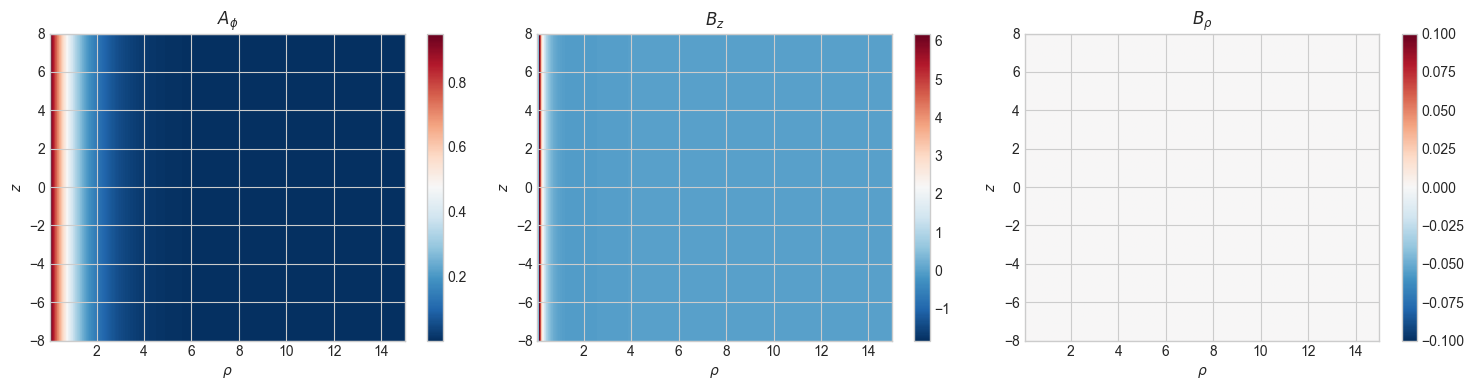

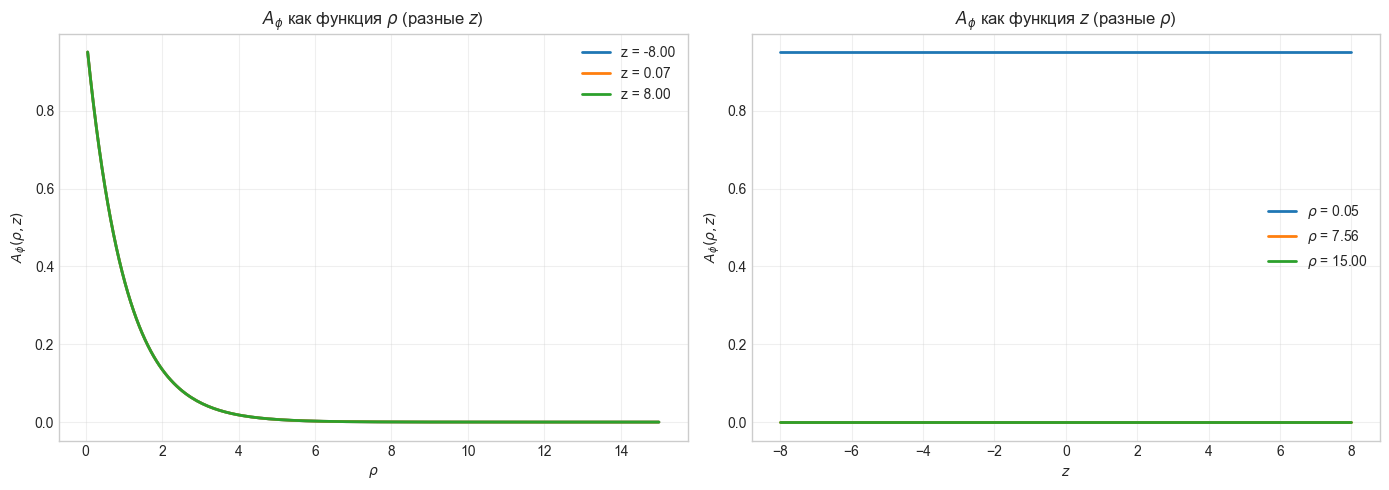

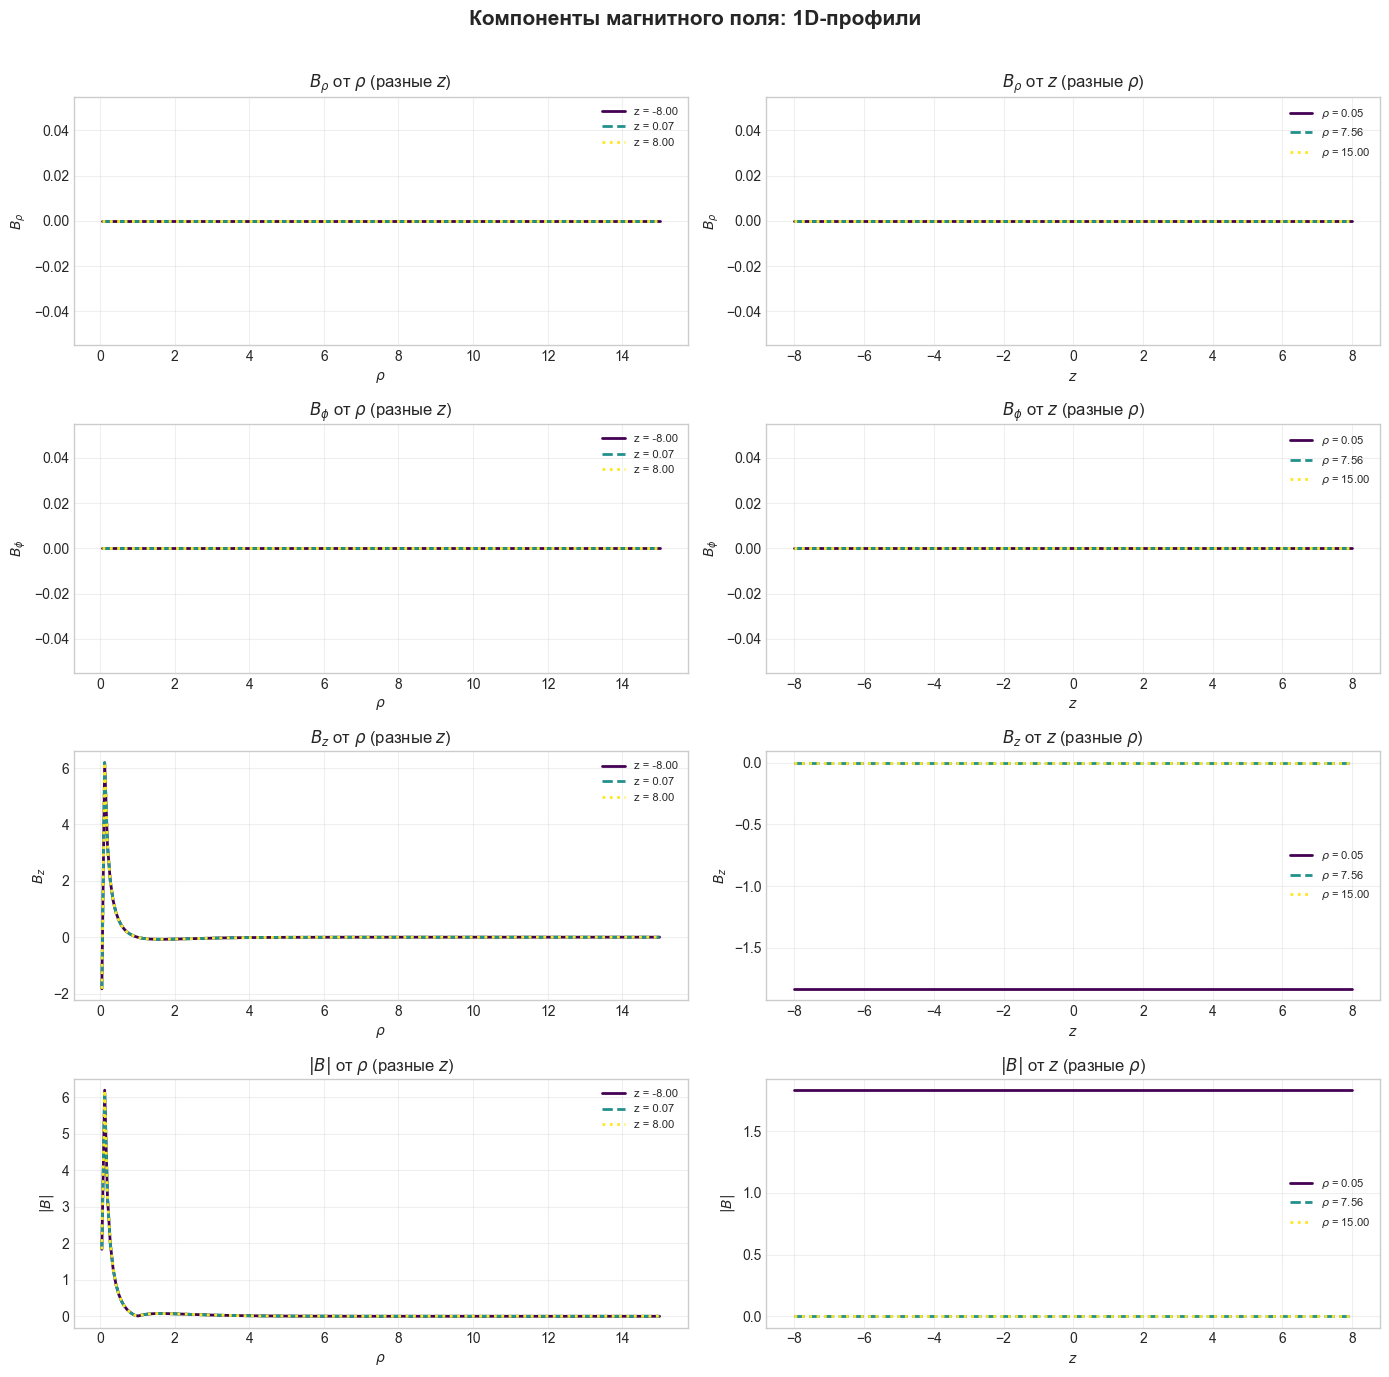

Осевой срез z = 0.07
max|B_z| = 6.1887,  max|B_phi| = 0.0000


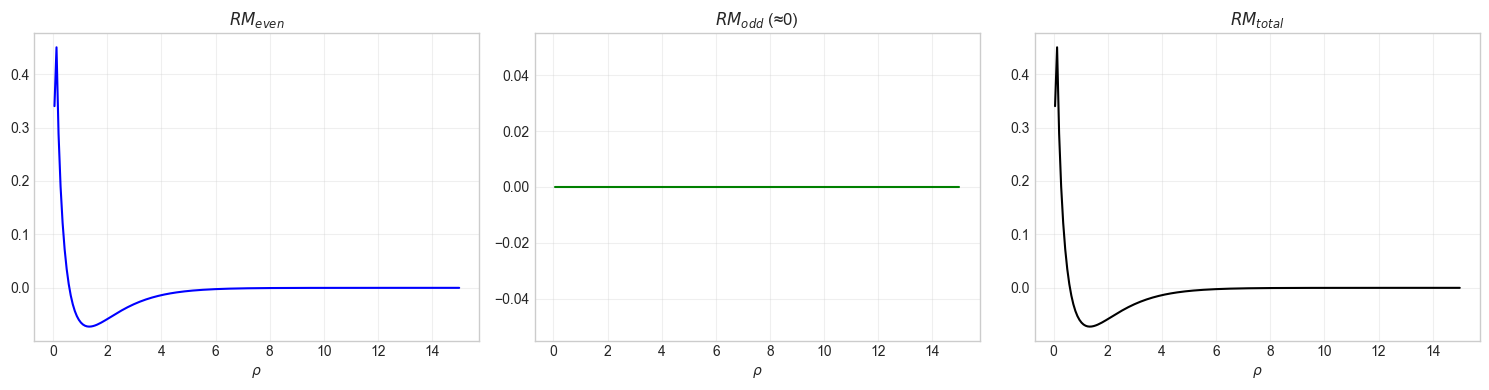

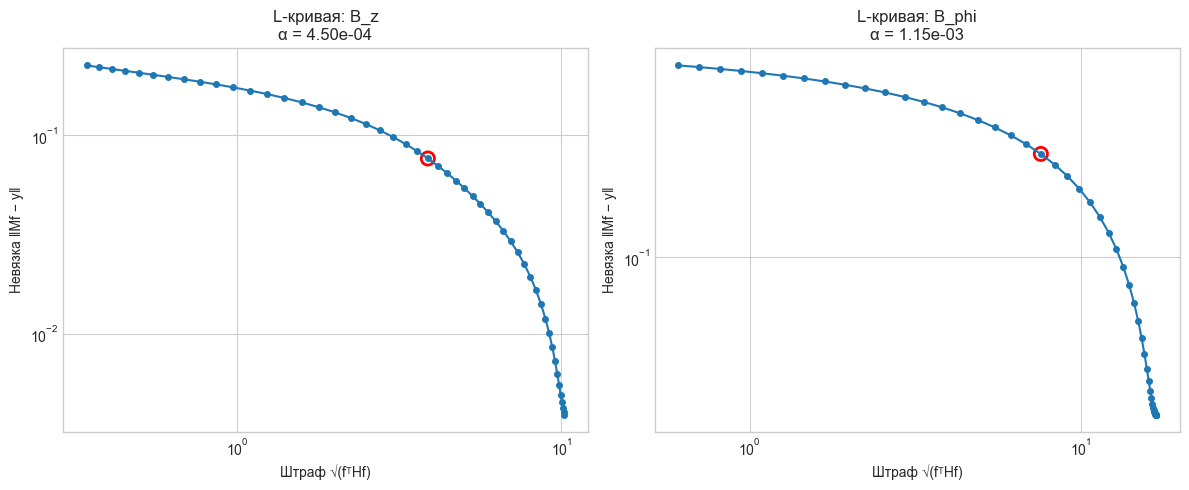

α(B_z)   = 4.50e-04
α(B_phi) = 1.15e-03


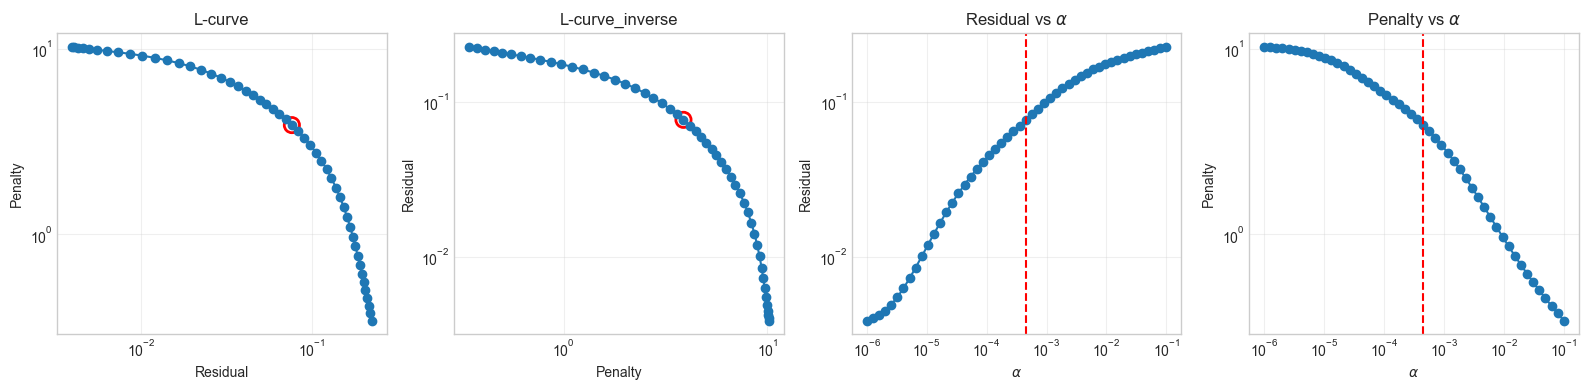

ε(B_z)   = 6.3715e-01
ε(B_phi) = 0.0000e+00


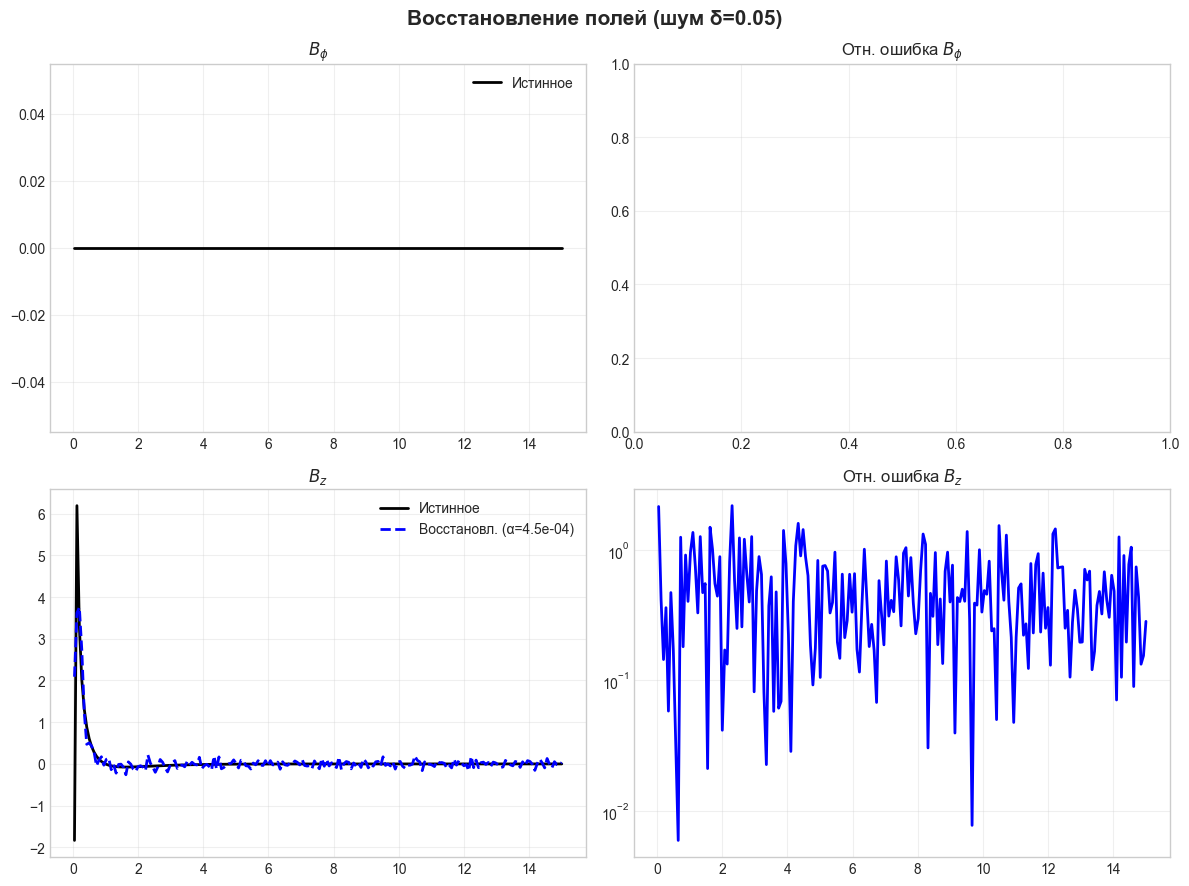

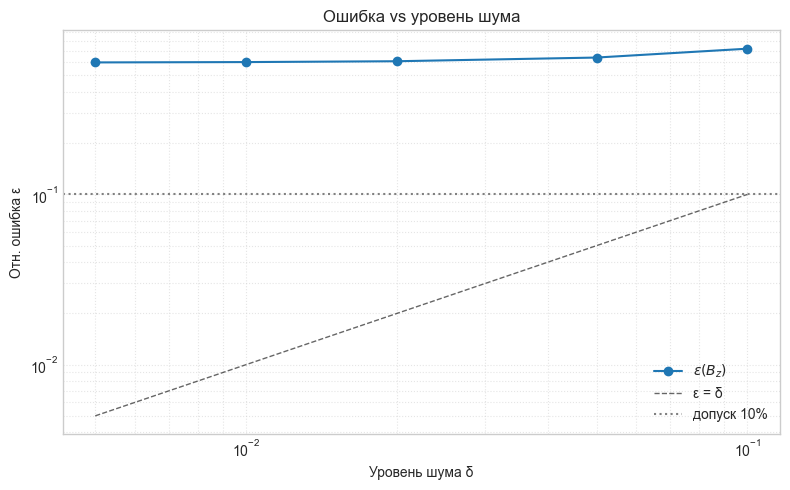

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


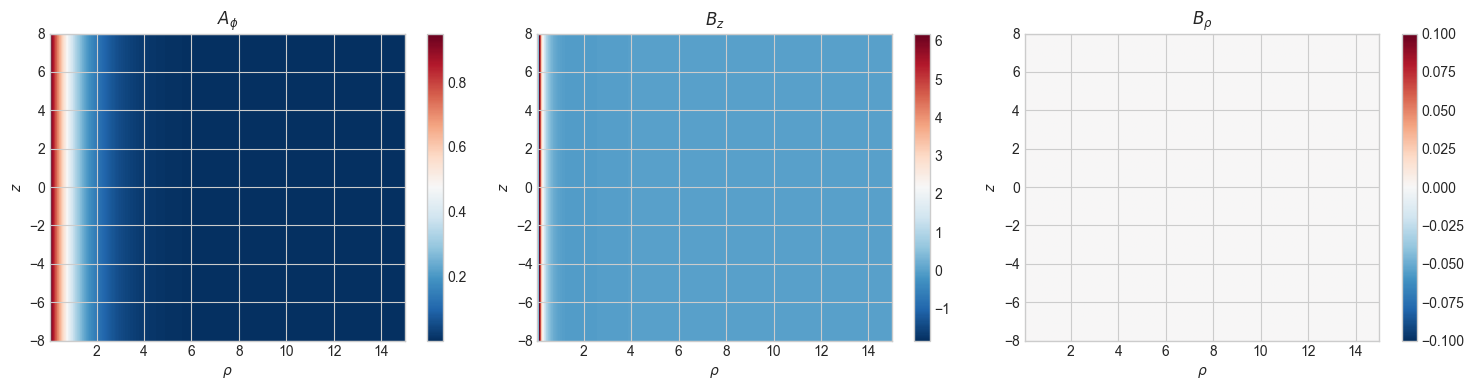

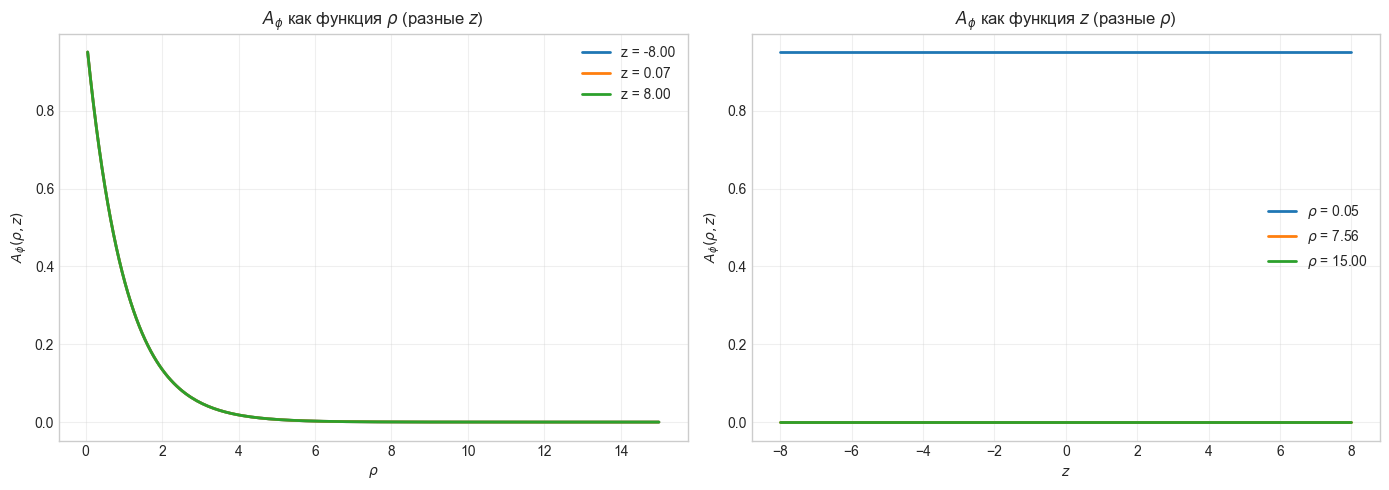

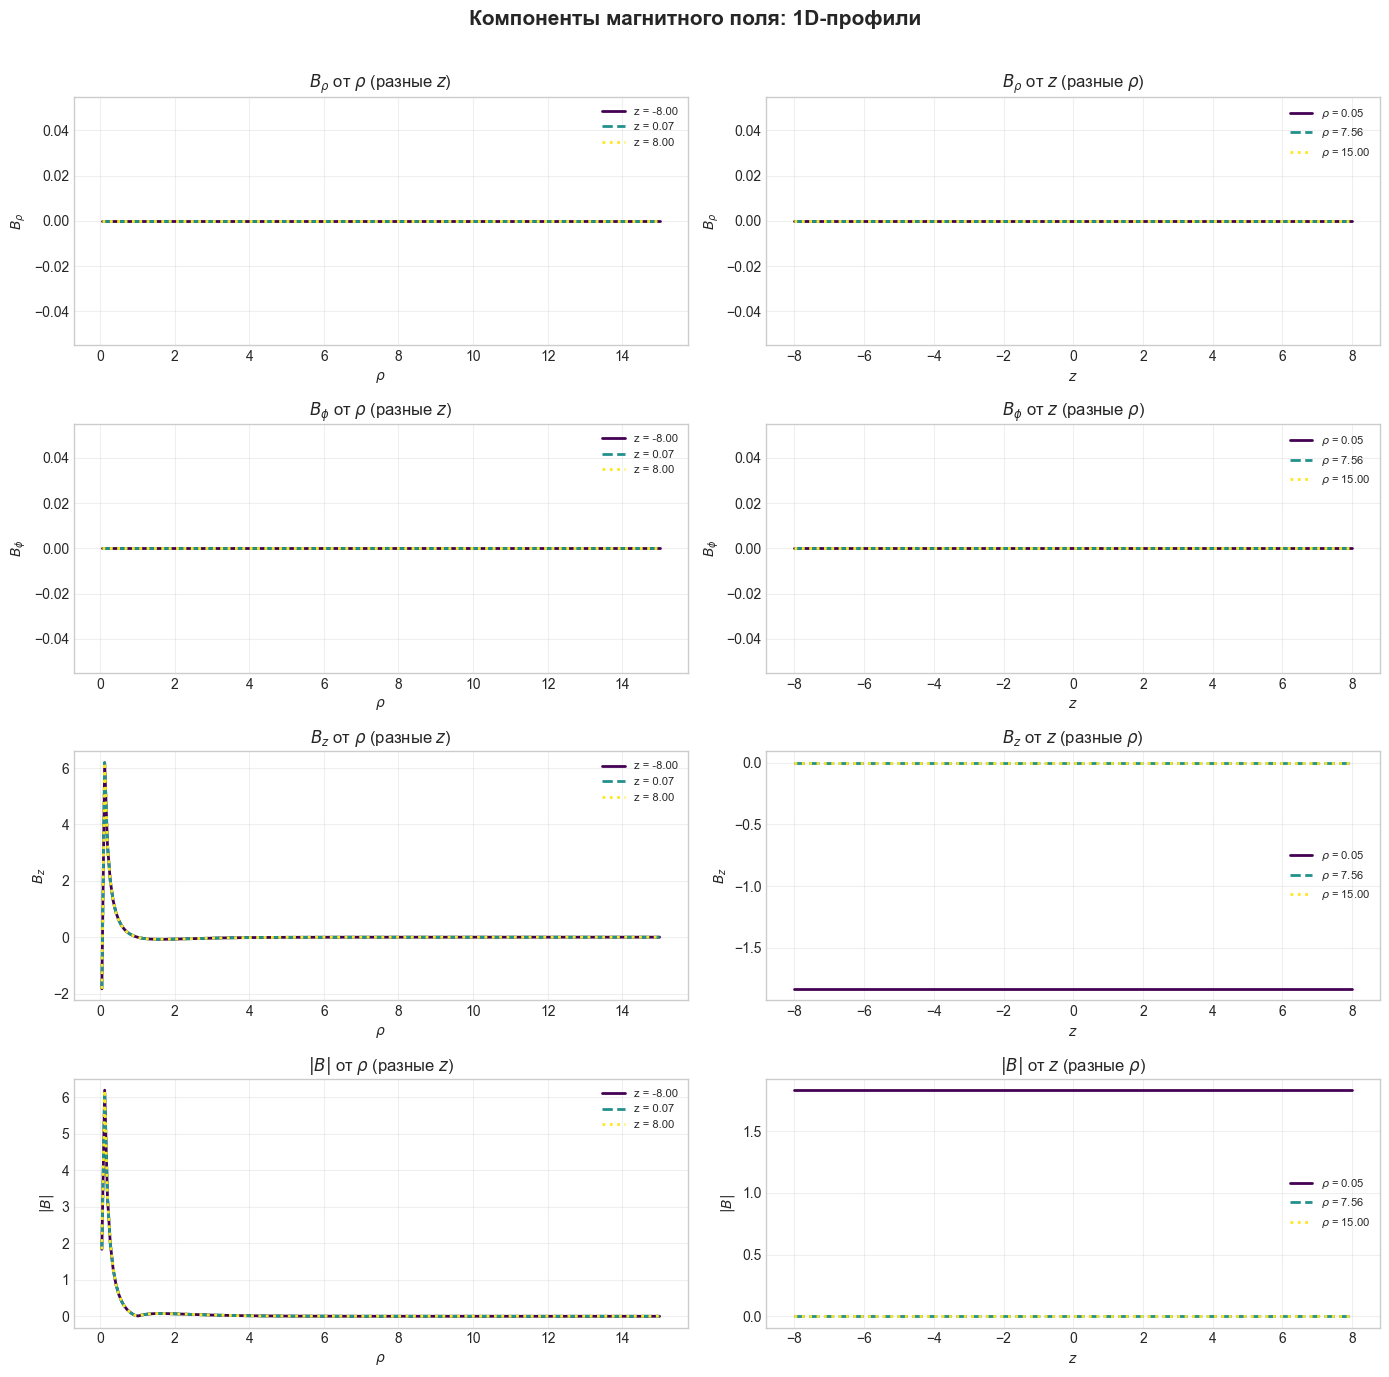

Осевой срез z = 0.07
max|B_z| = 6.1887,  max|B_phi| = 0.0000


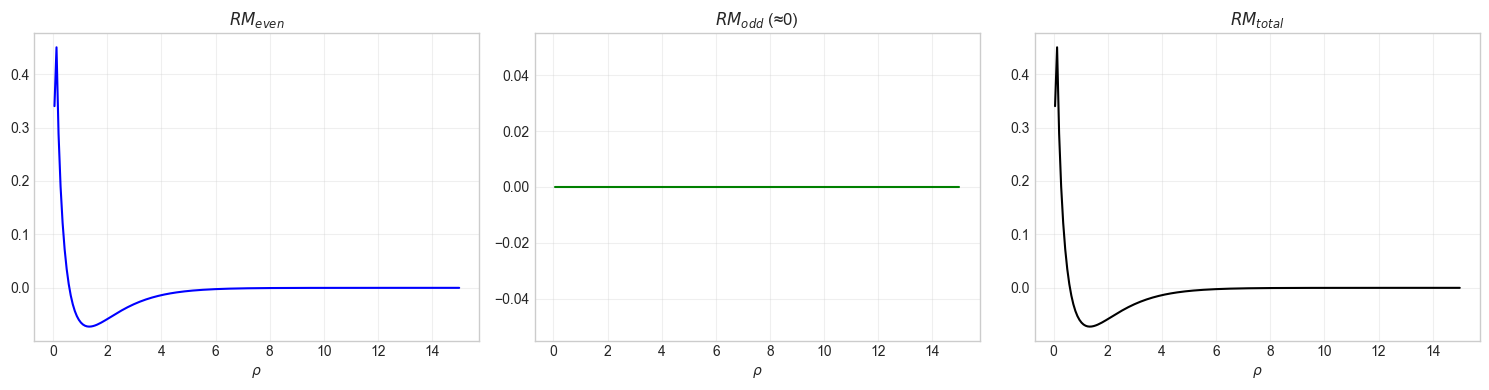

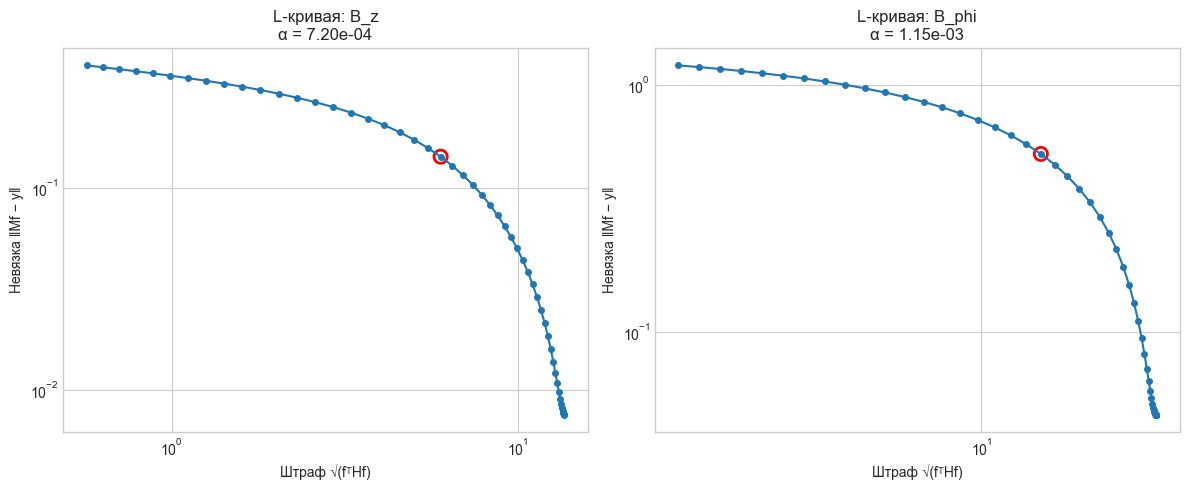

α(B_z)   = 7.20e-04
α(B_phi) = 1.15e-03


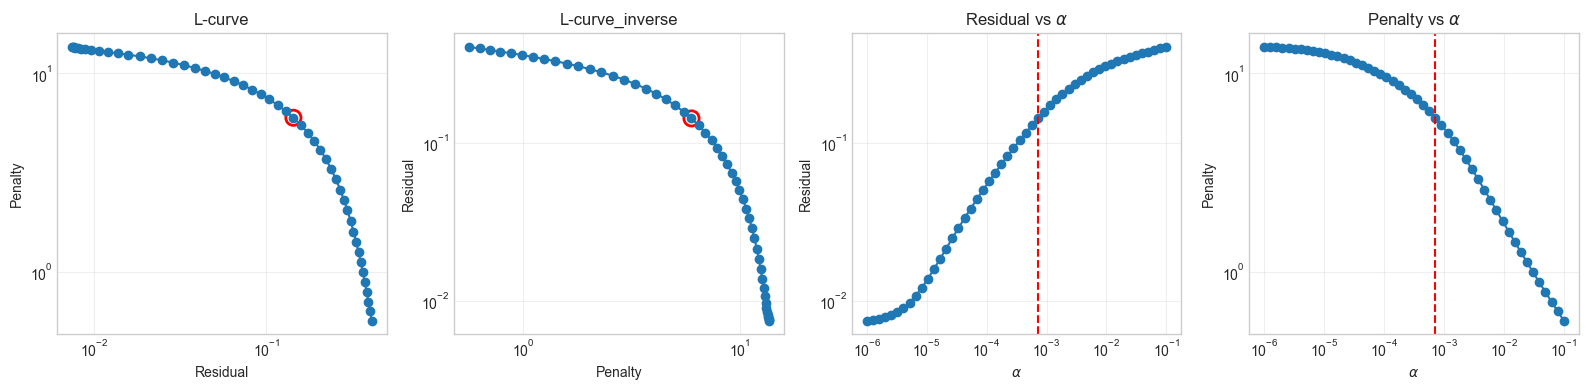

ε(B_z)   = 7.2910e-01
ε(B_phi) = 0.0000e+00


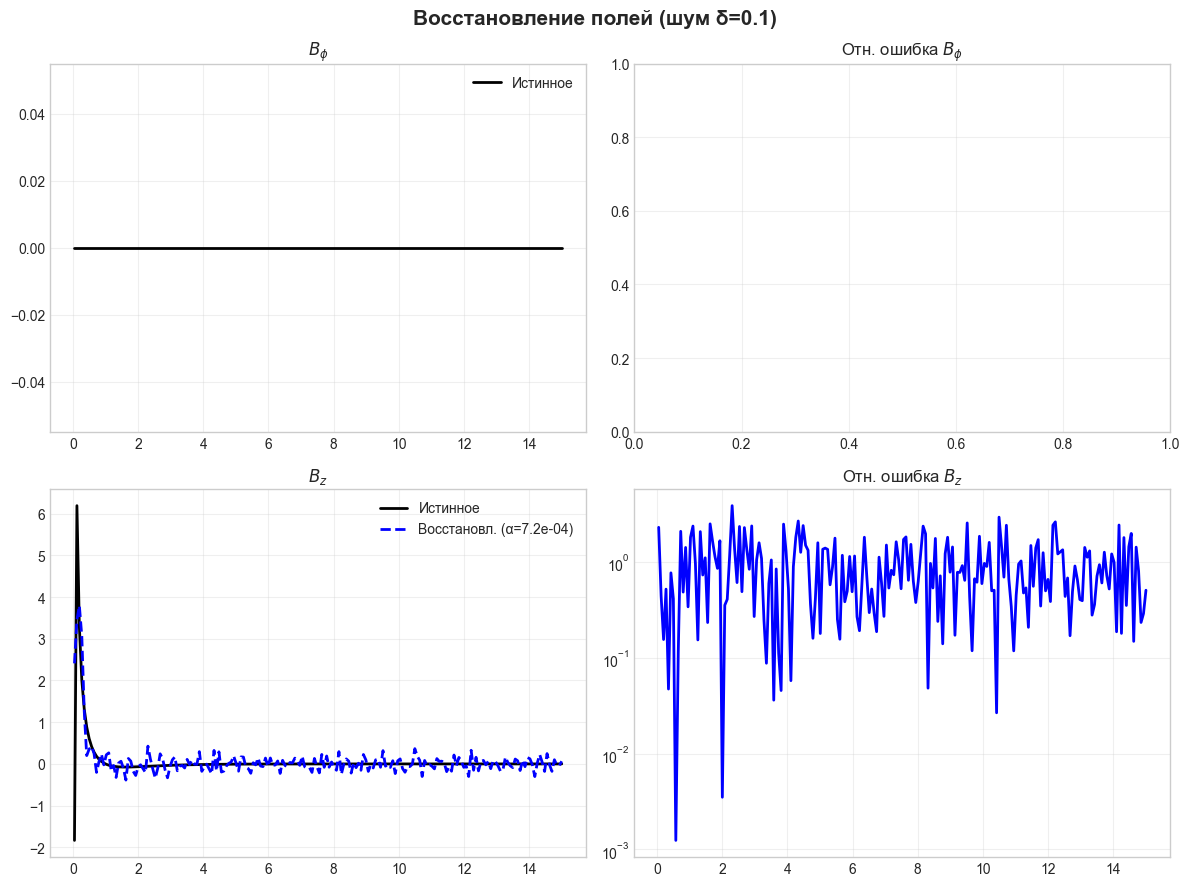

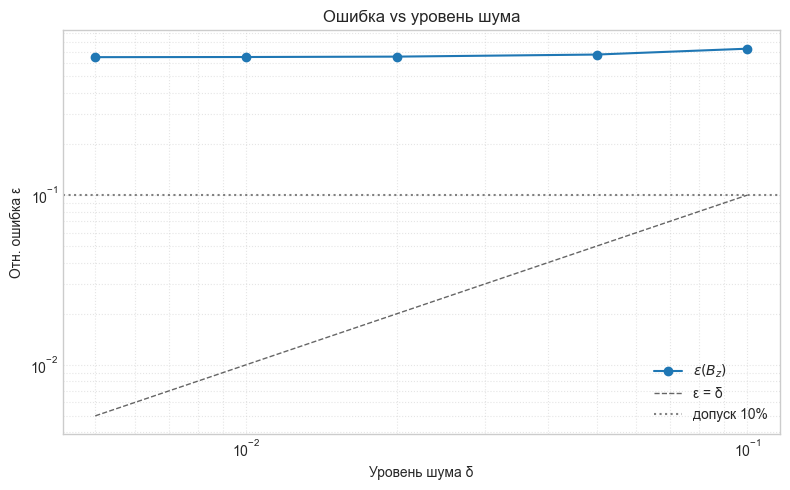

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


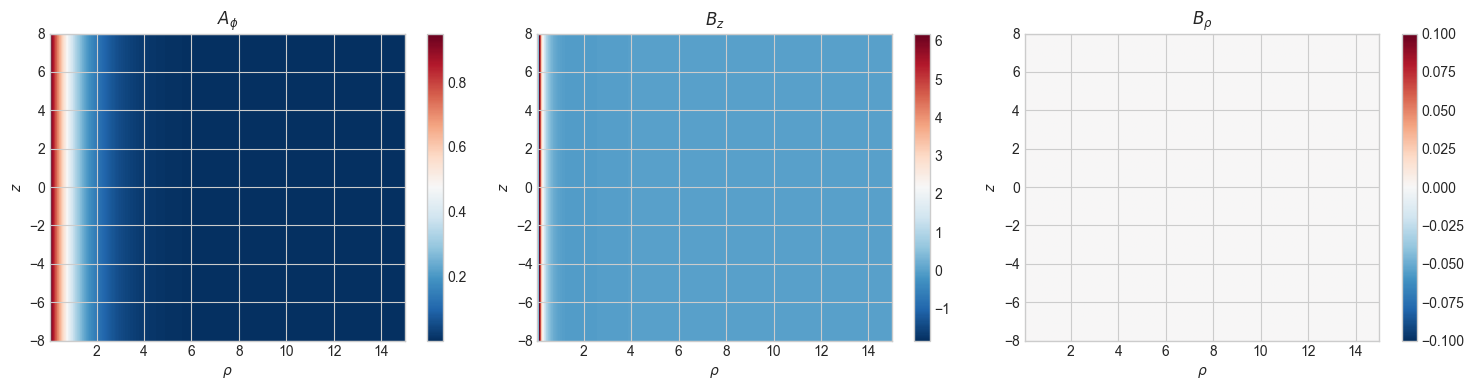

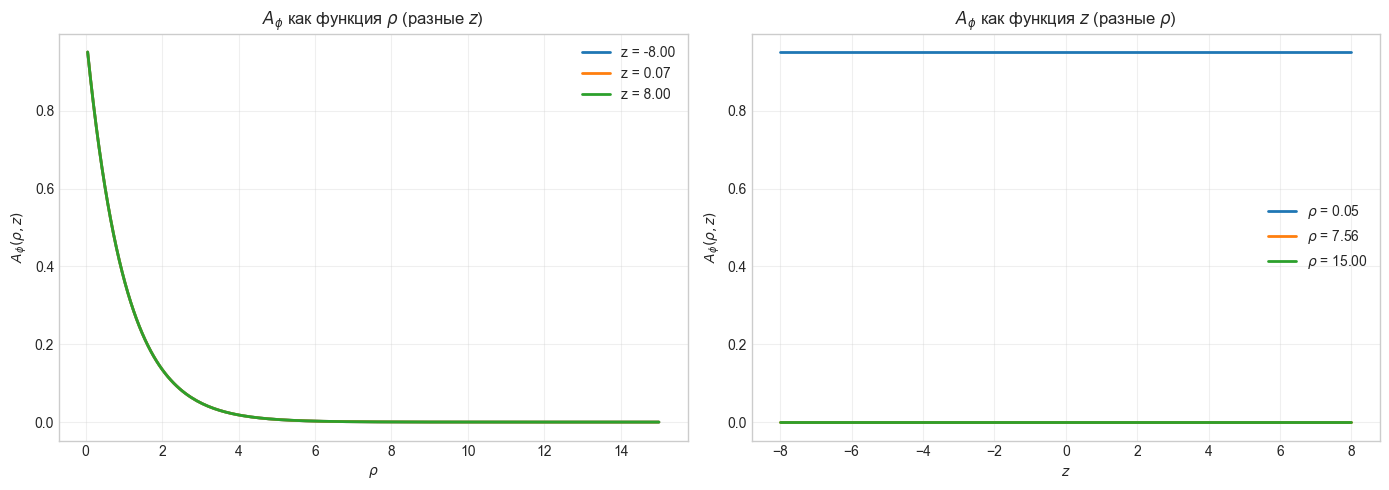

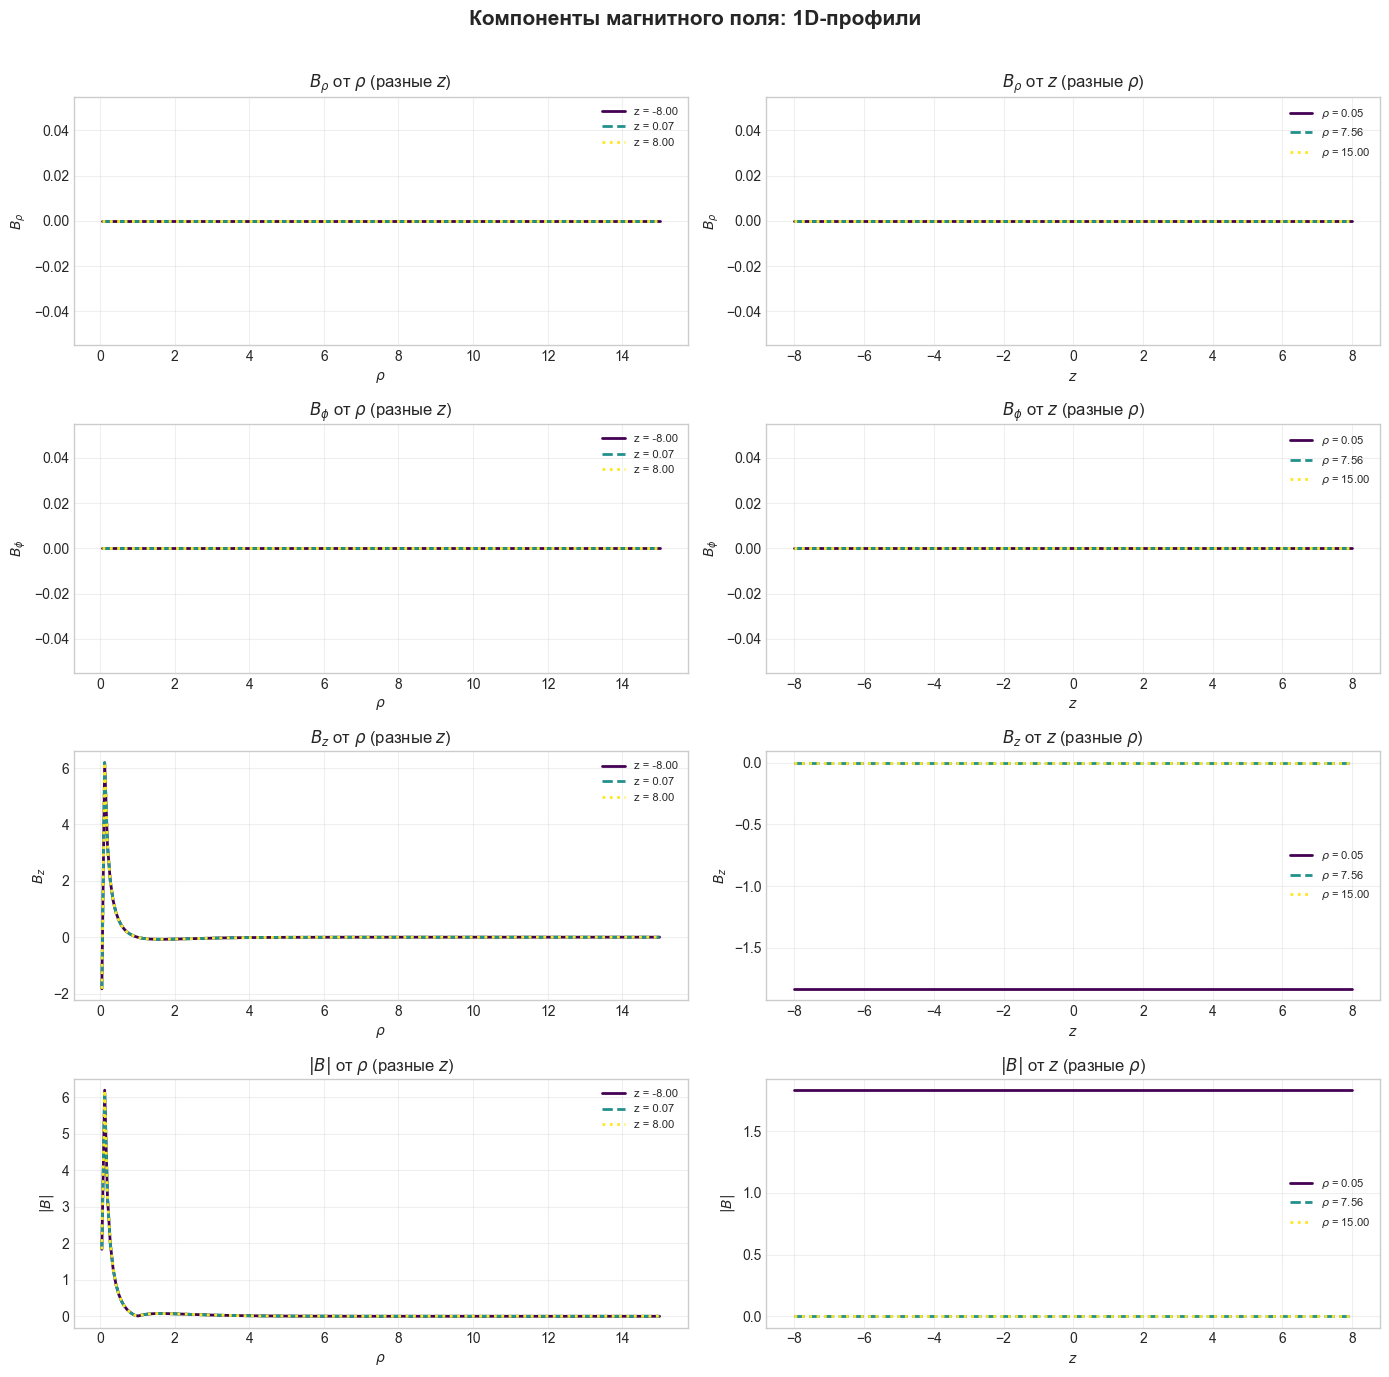

Осевой срез z = 0.07
max|B_z| = 6.1887,  max|B_phi| = 0.0000


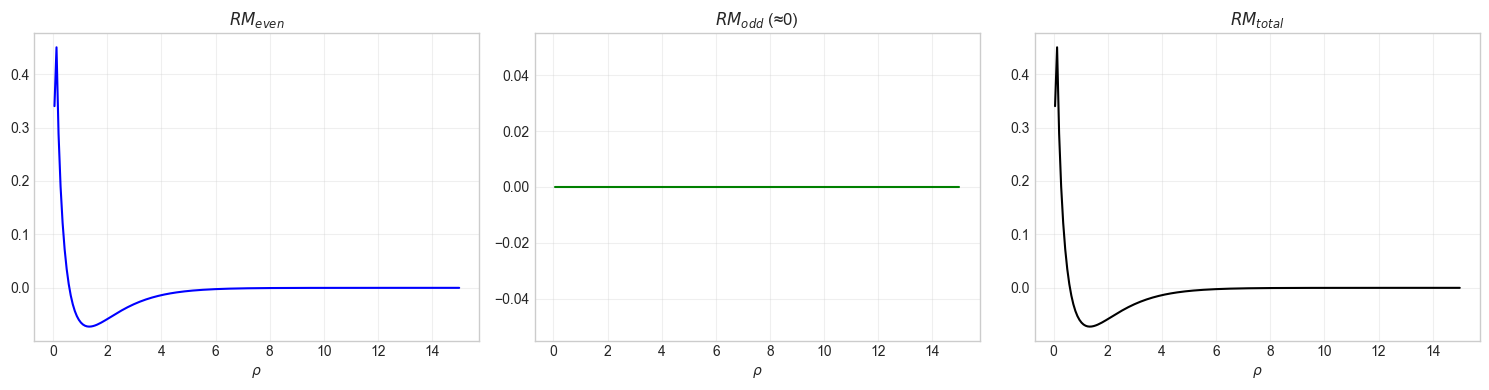

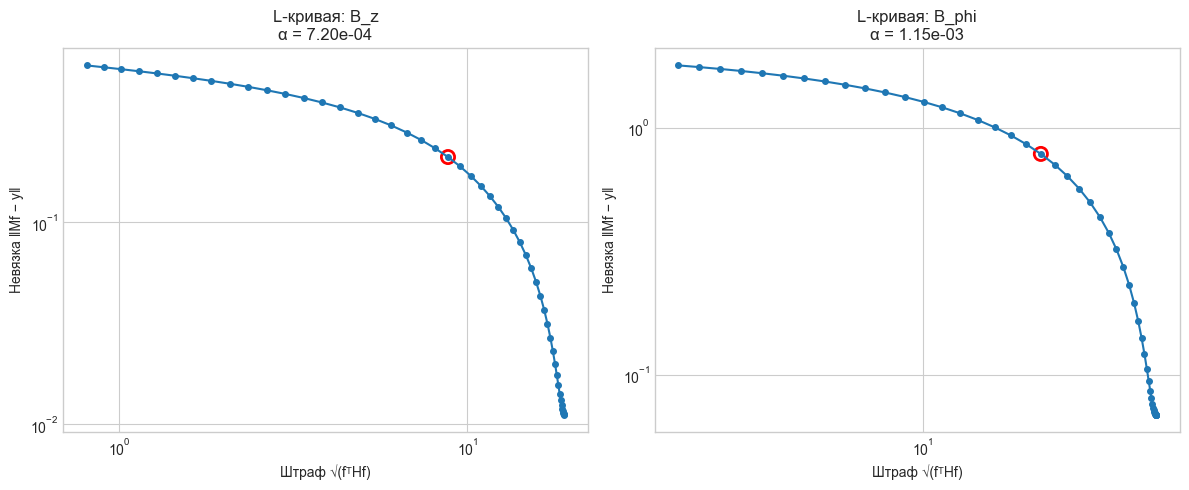

α(B_z)   = 7.20e-04
α(B_phi) = 1.15e-03


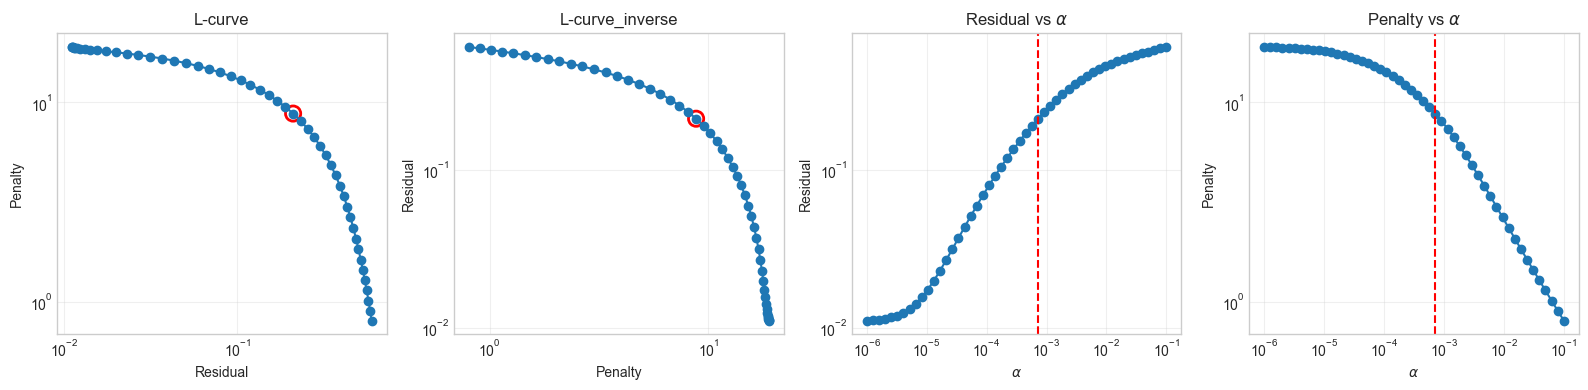

ε(B_z)   = 8.0993e-01
ε(B_phi) = 0.0000e+00


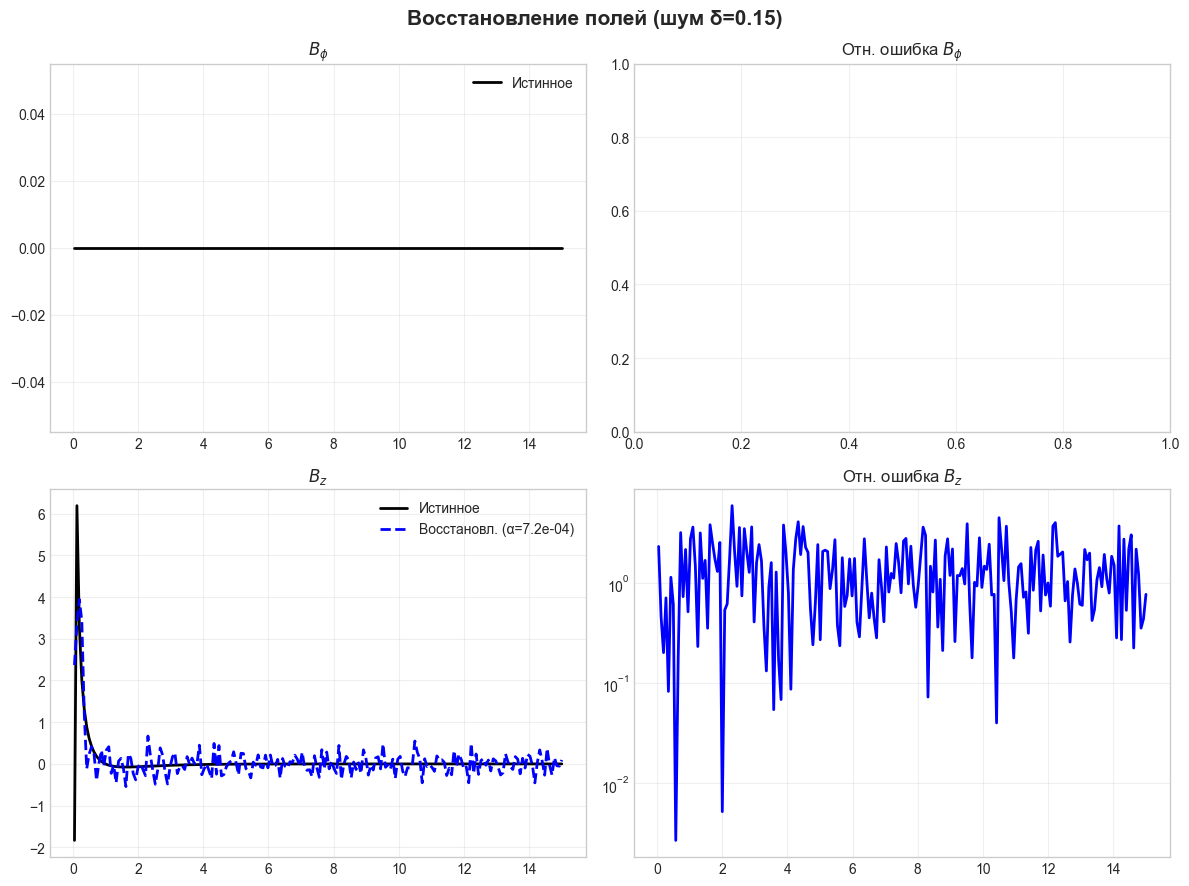

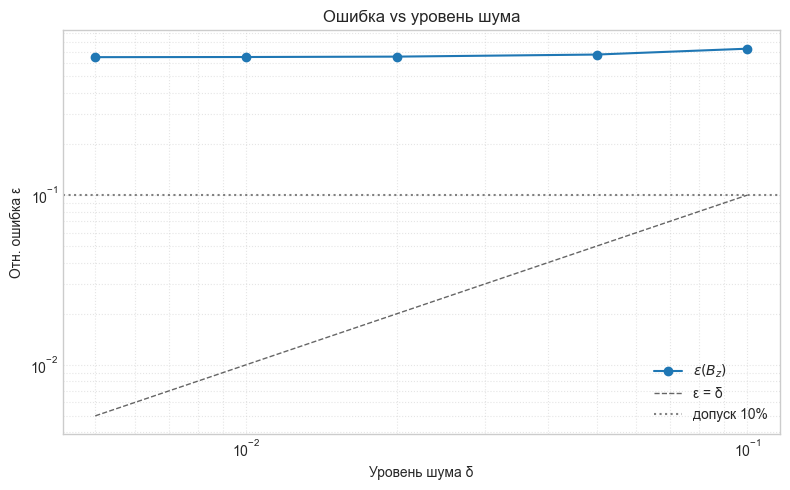

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


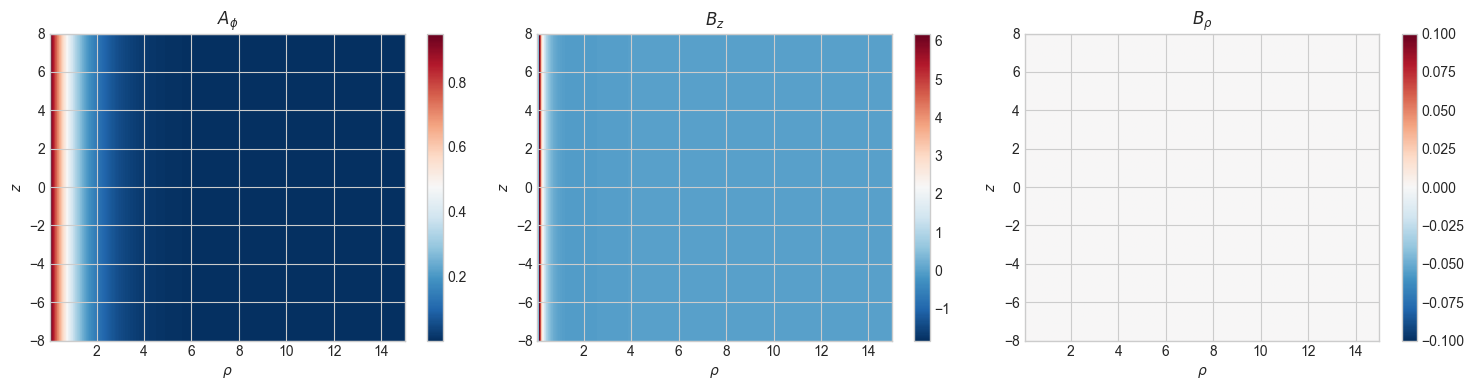

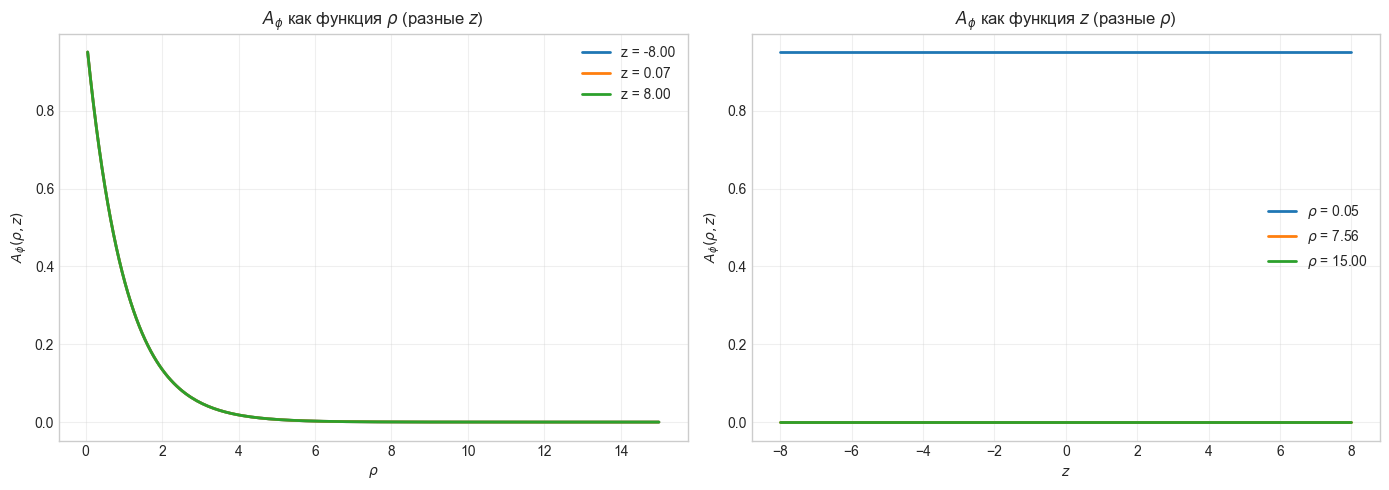

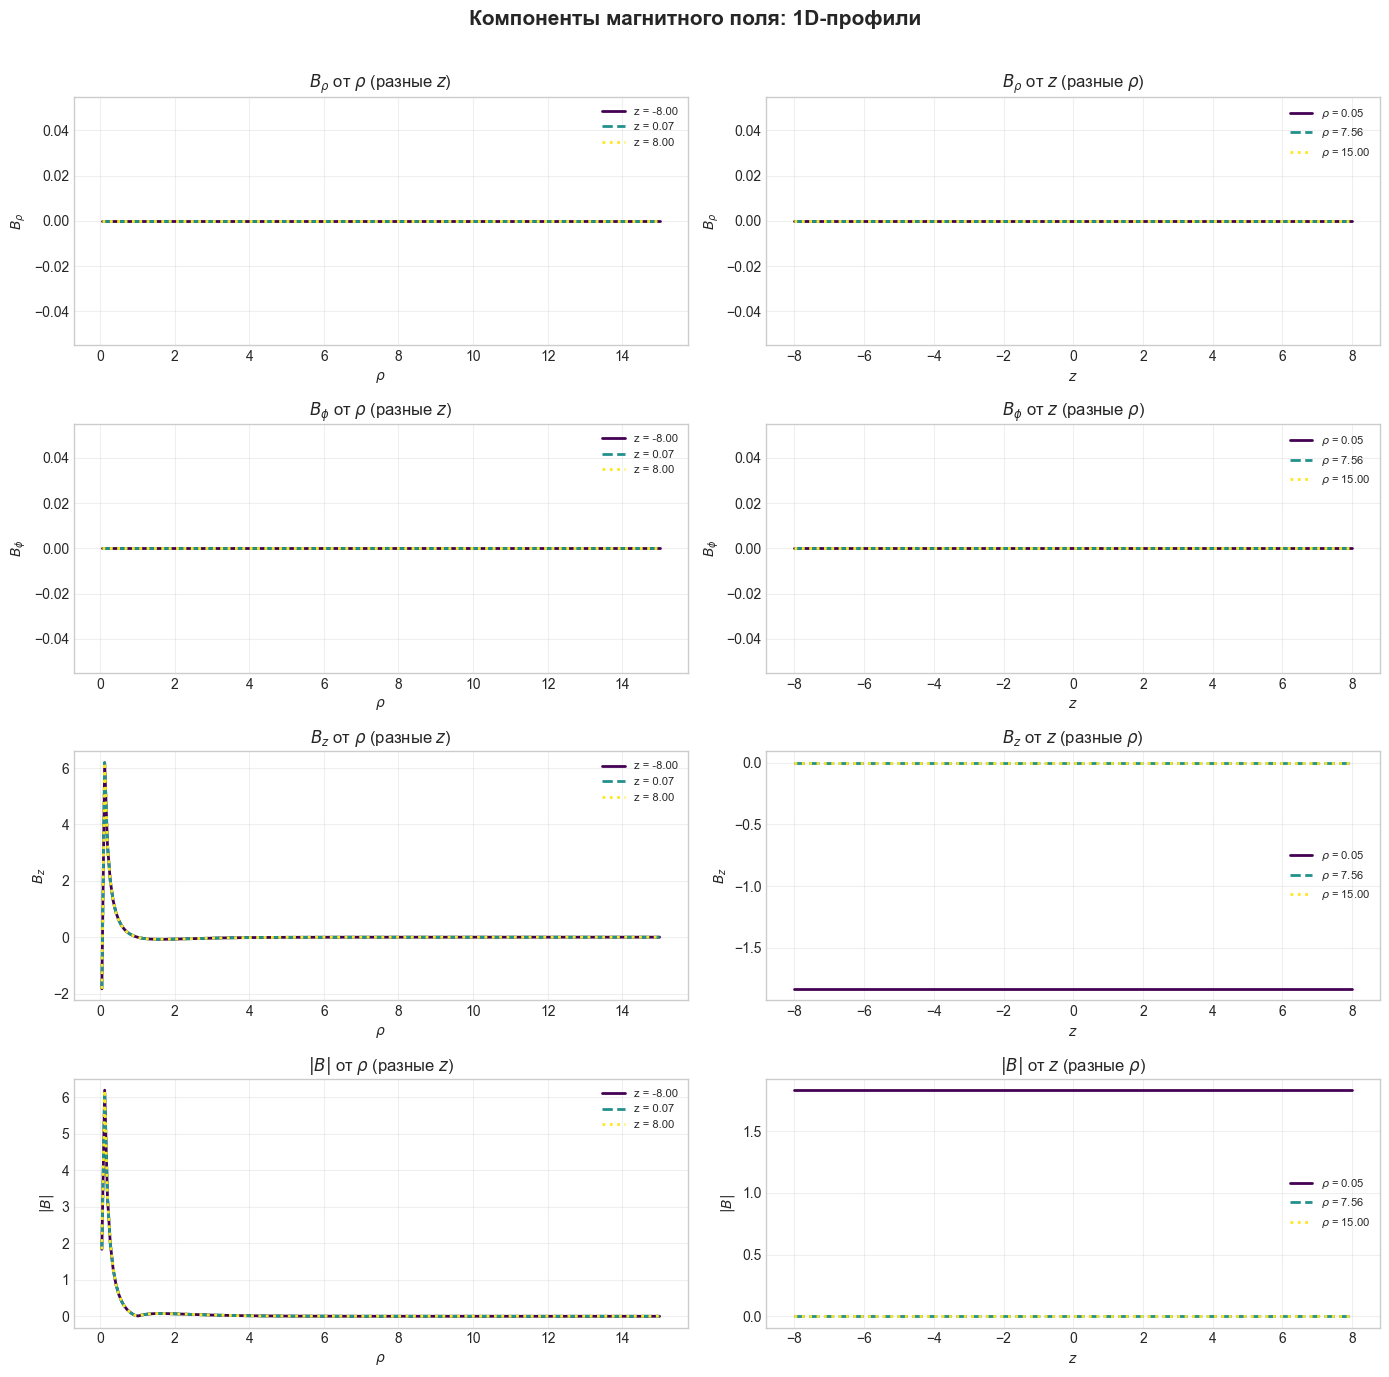

Осевой срез z = 0.07
max|B_z| = 6.1887,  max|B_phi| = 0.0000


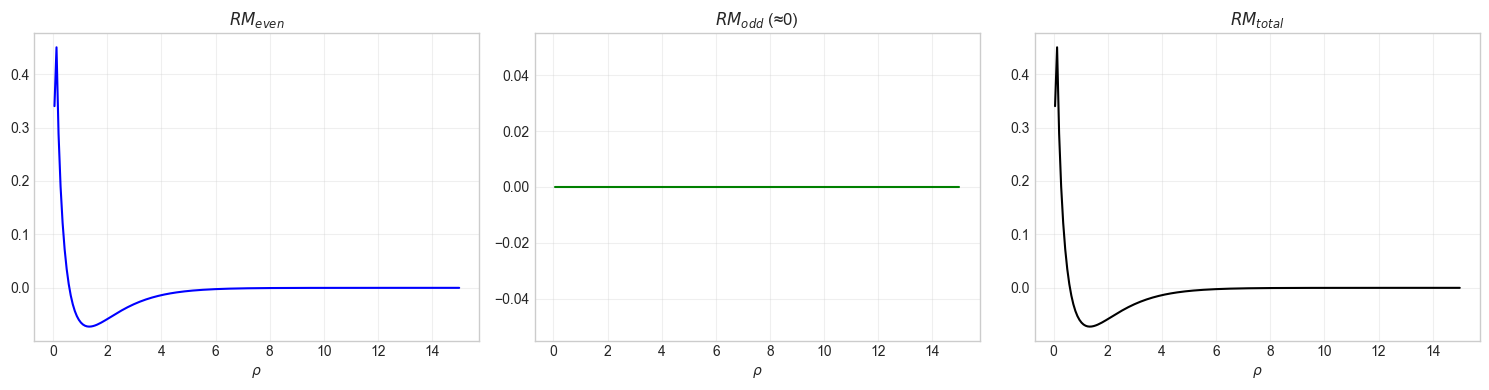

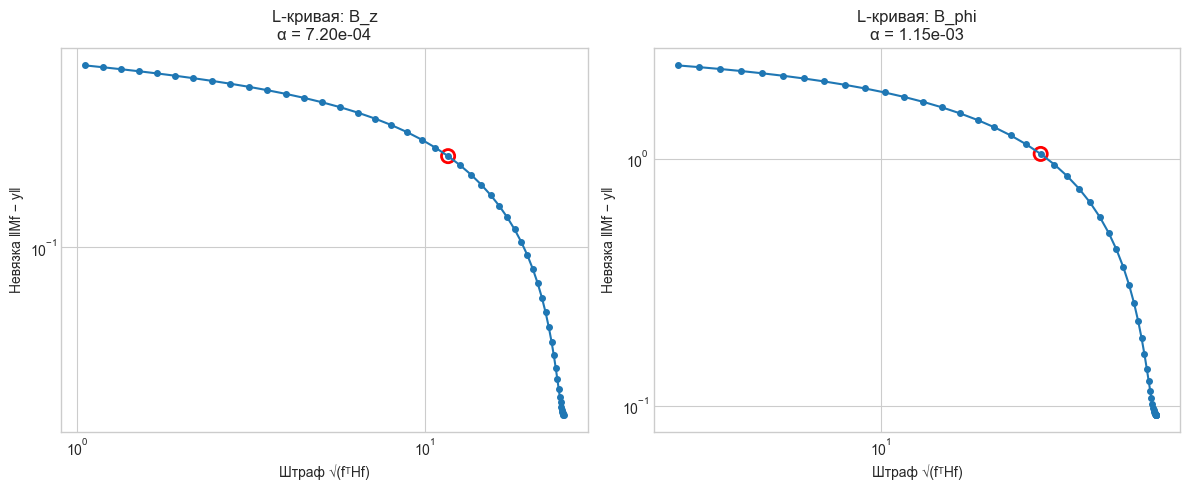

α(B_z)   = 7.20e-04
α(B_phi) = 1.15e-03


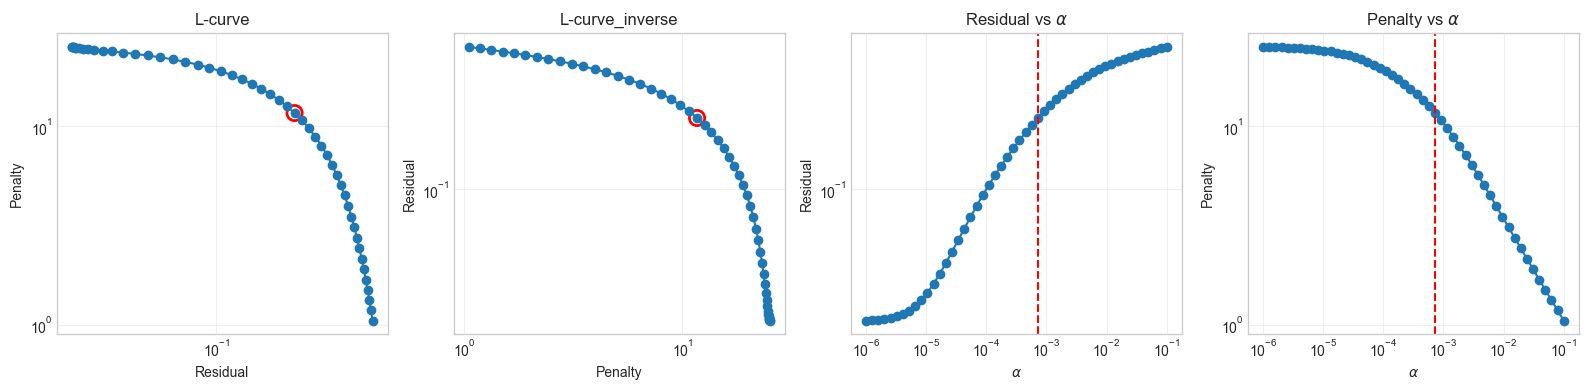

ε(B_z)   = 9.0915e-01
ε(B_phi) = 0.0000e+00


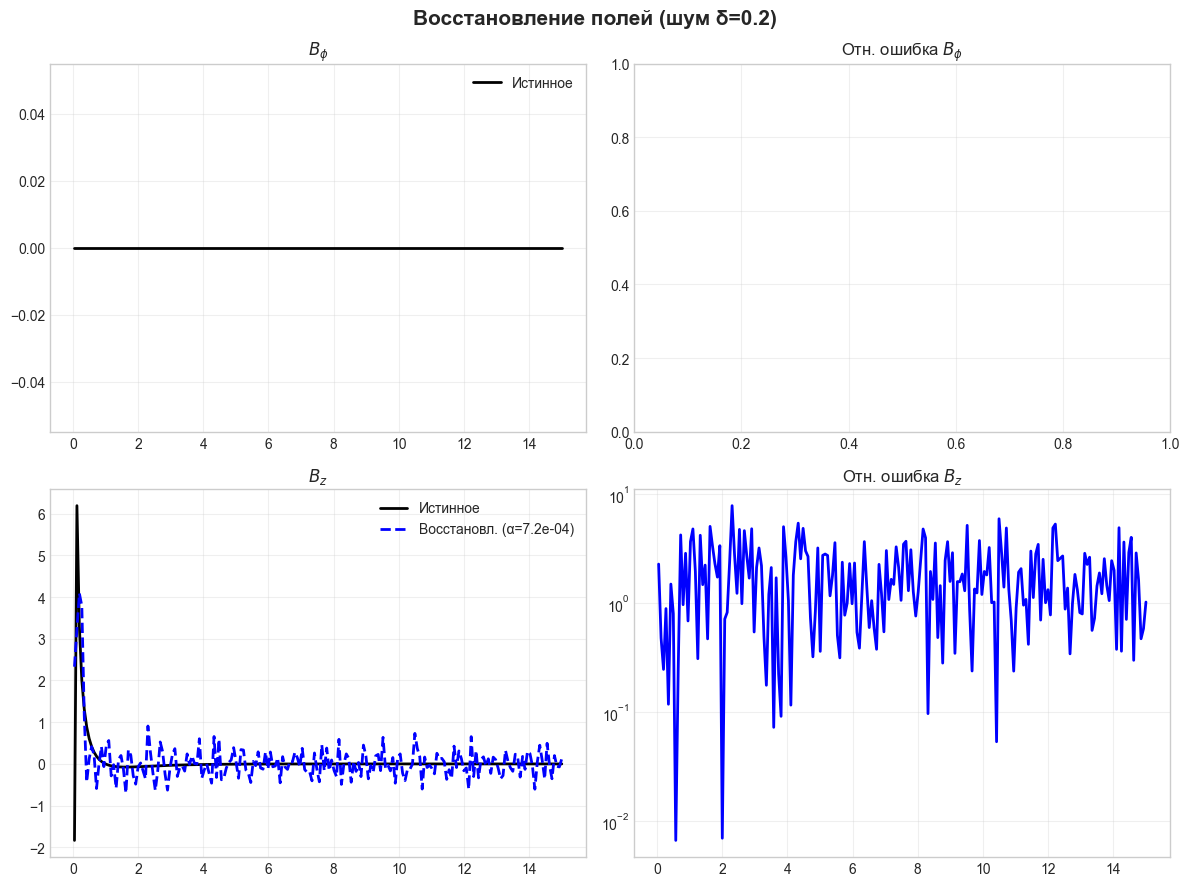

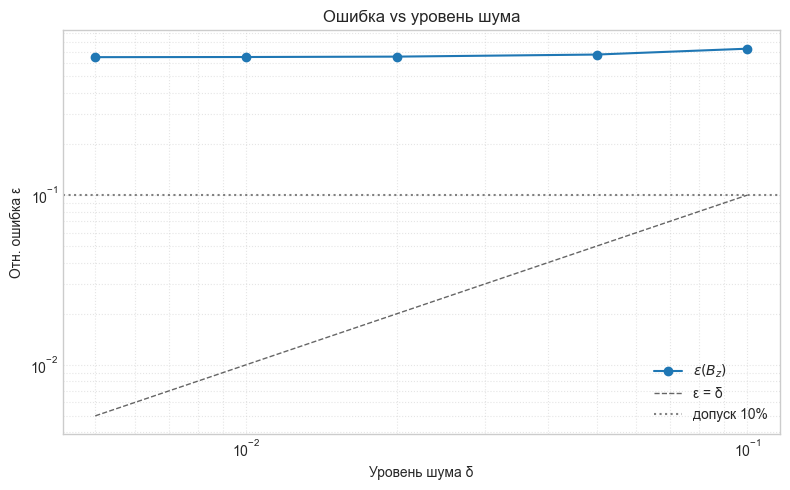

In [5]:
for delta in delta_arr:
    Calculate(A_phi_exp, delta= delta)

# $A_\phi = \rho$

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


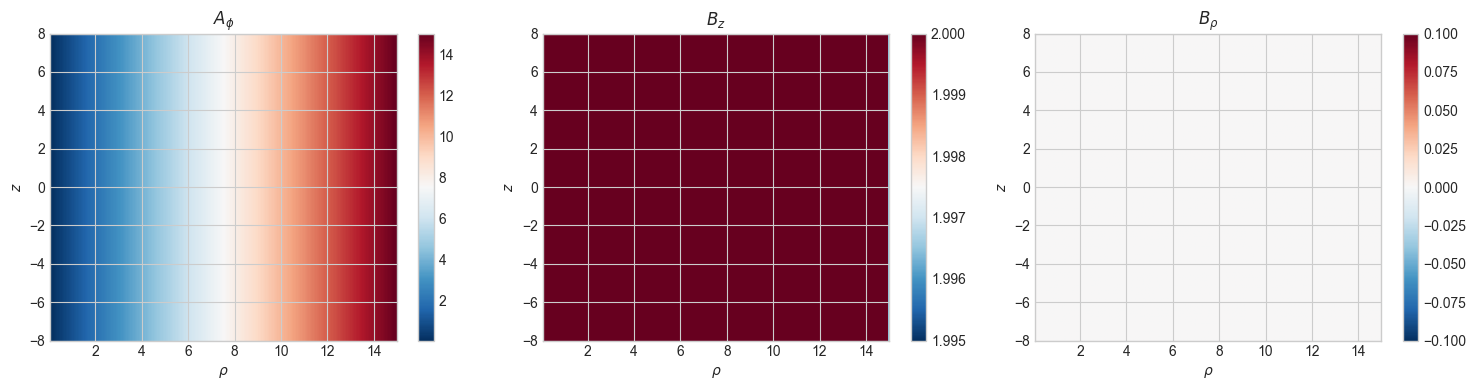

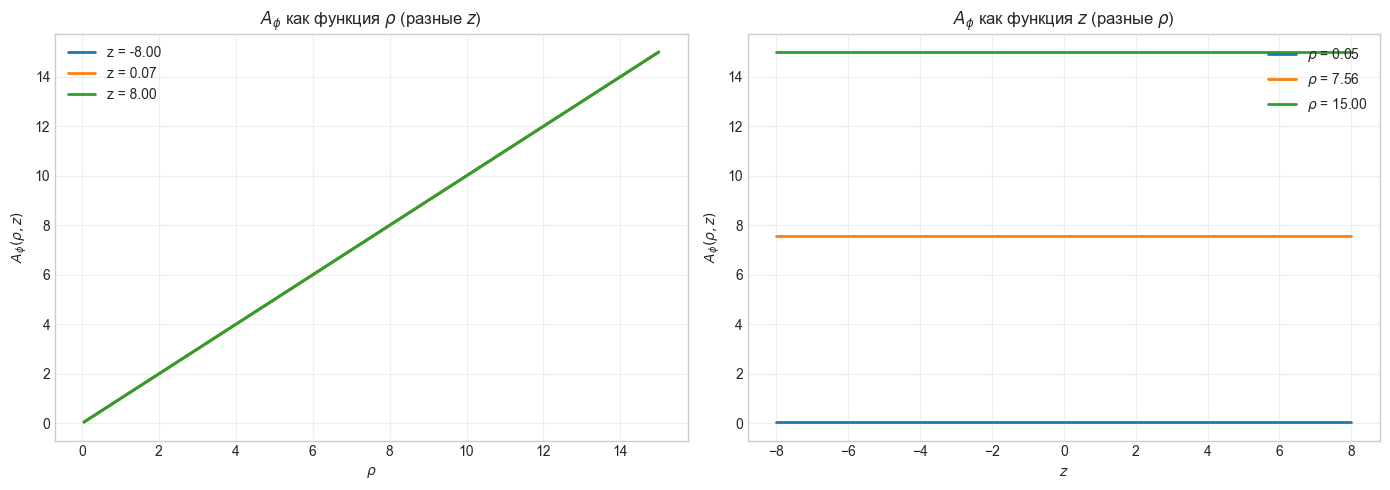

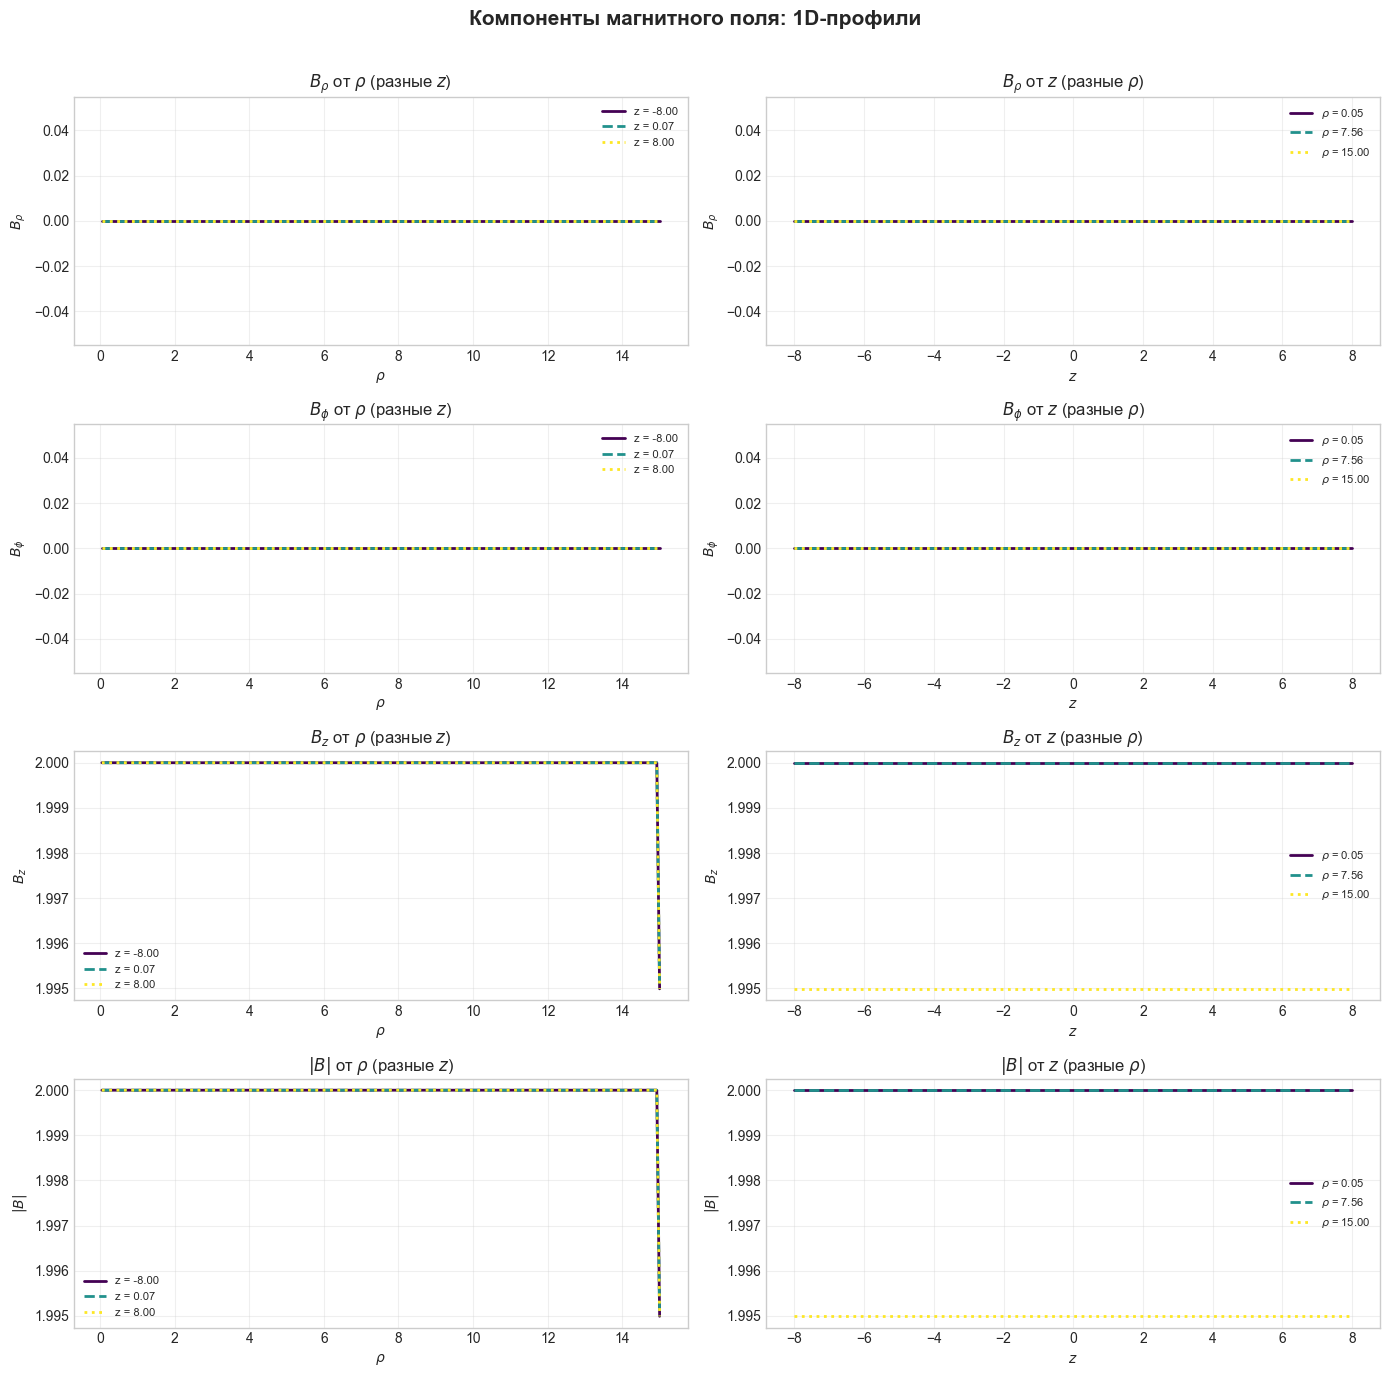

Осевой срез z = 0.07
max|B_z| = 2.0000,  max|B_phi| = 0.0000


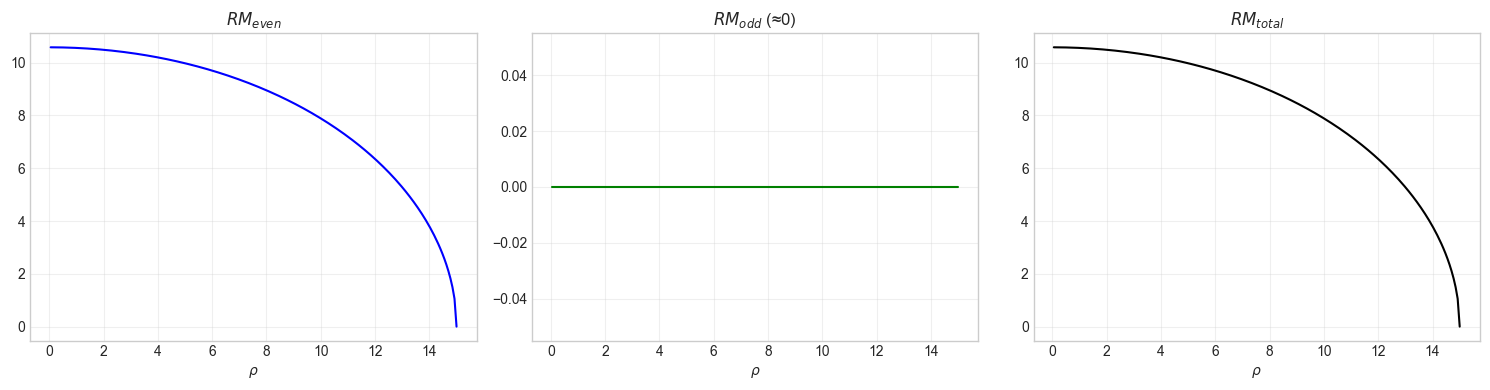

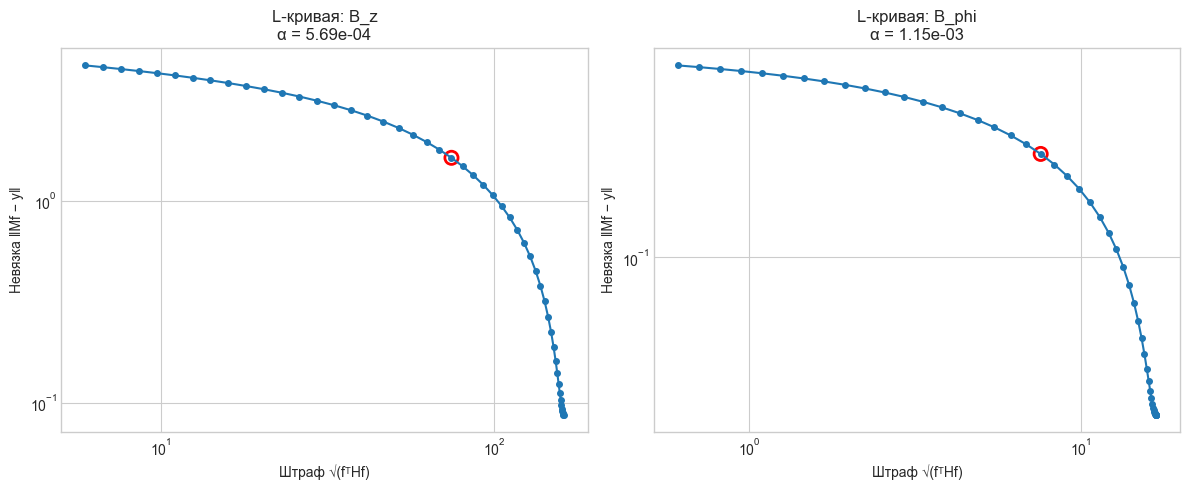

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


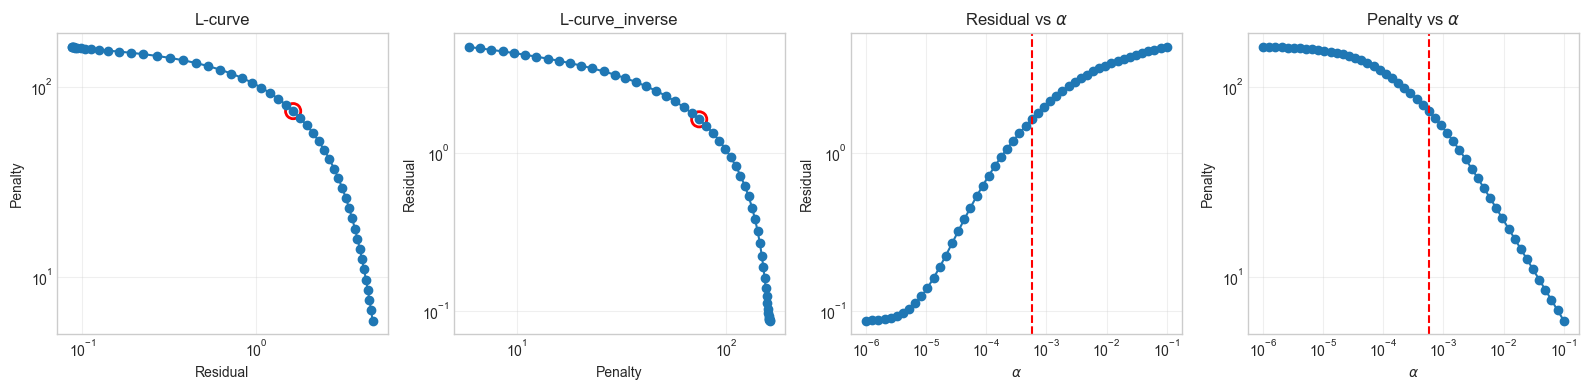

ε(B_z)   = 1.0296e+00
ε(B_phi) = 0.0000e+00


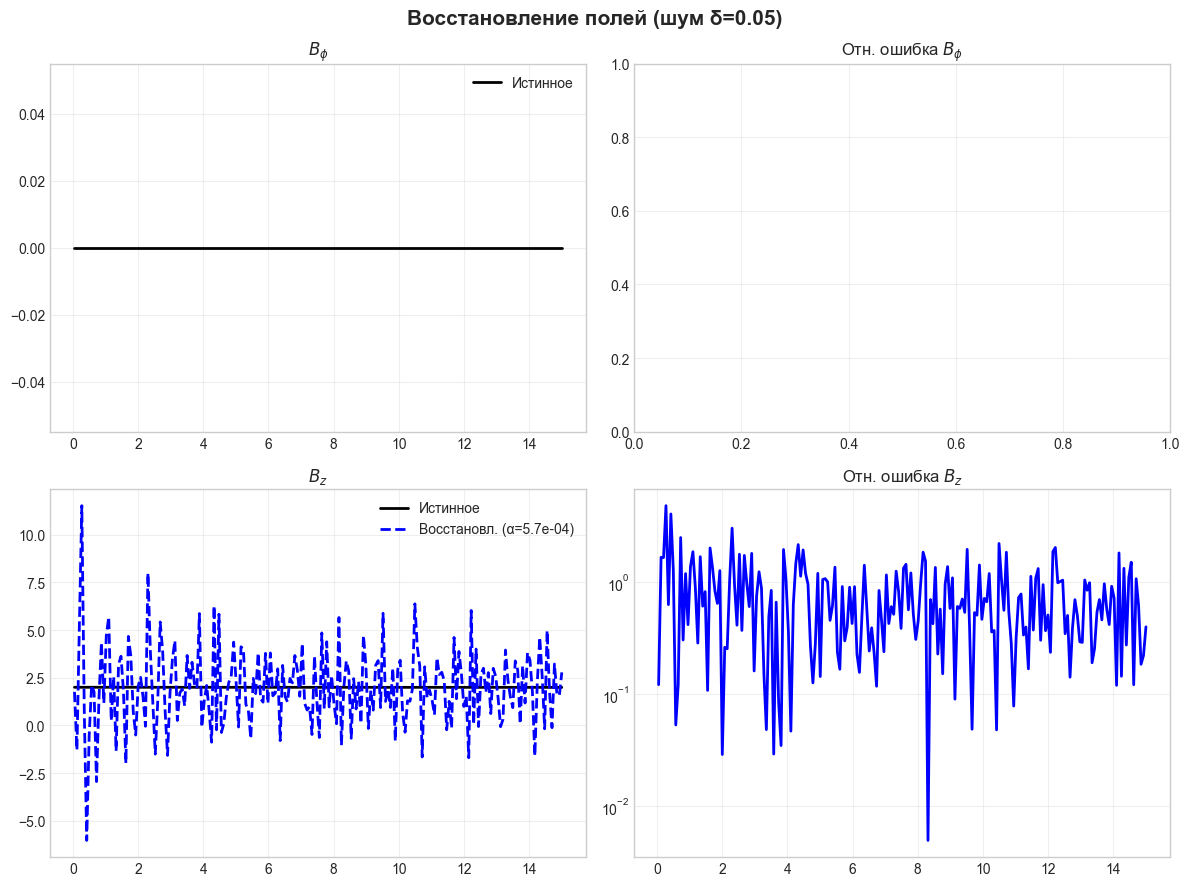

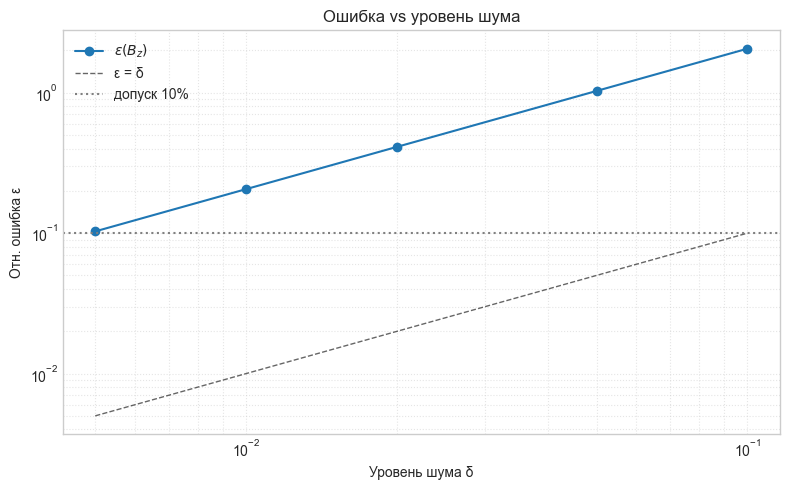

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


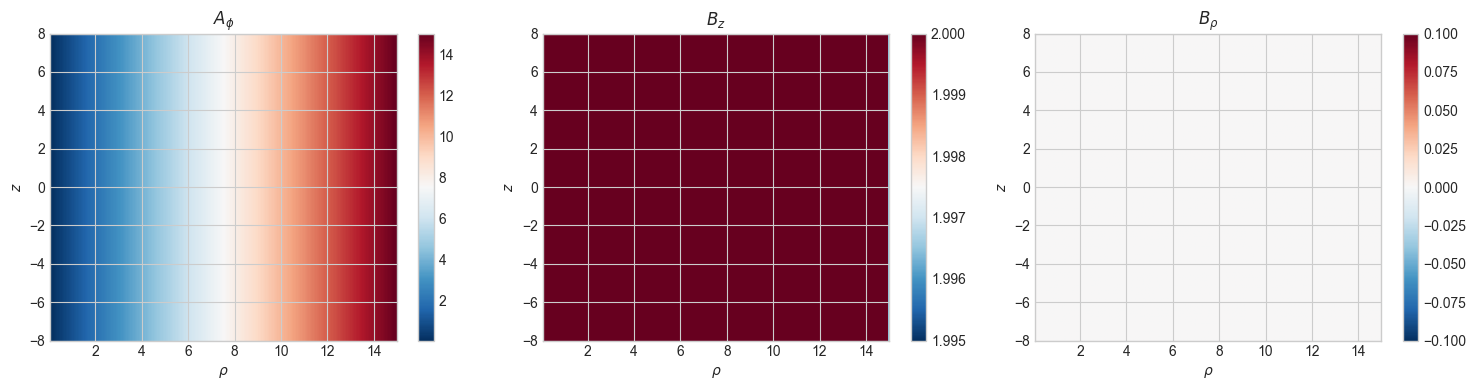

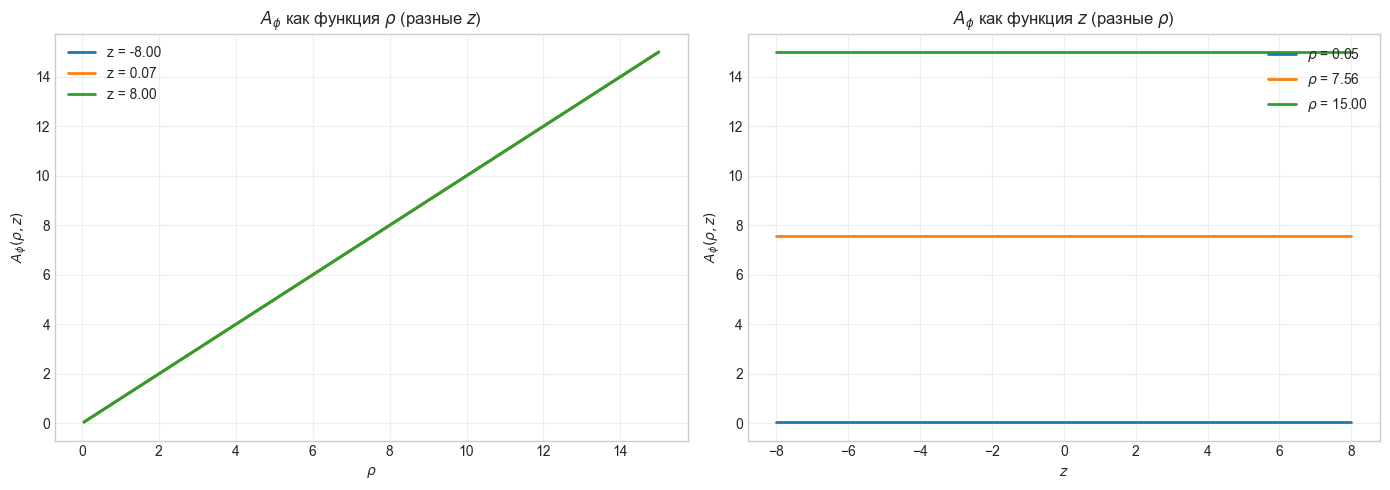

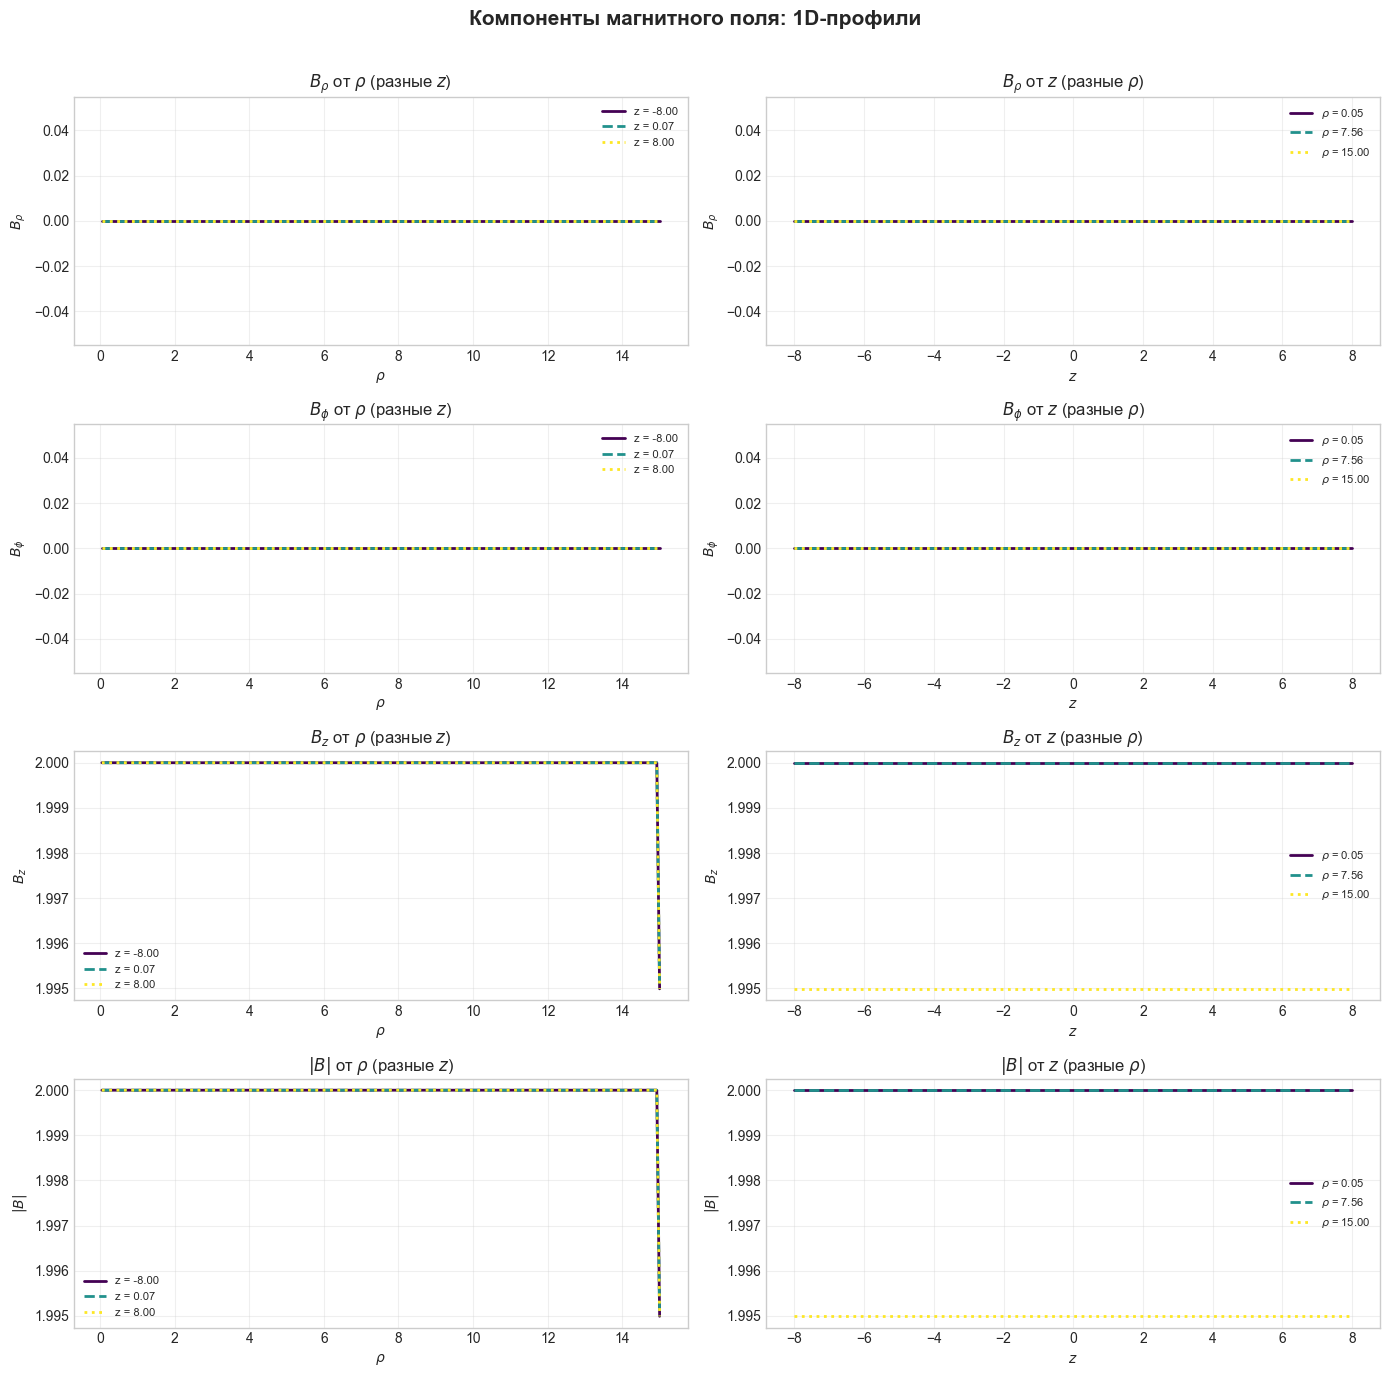

Осевой срез z = 0.07
max|B_z| = 2.0000,  max|B_phi| = 0.0000


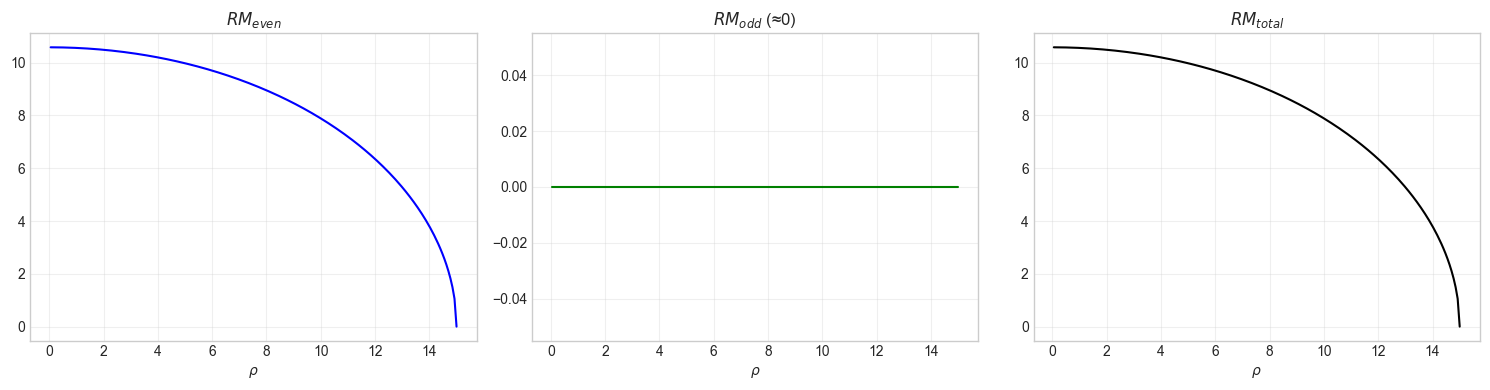

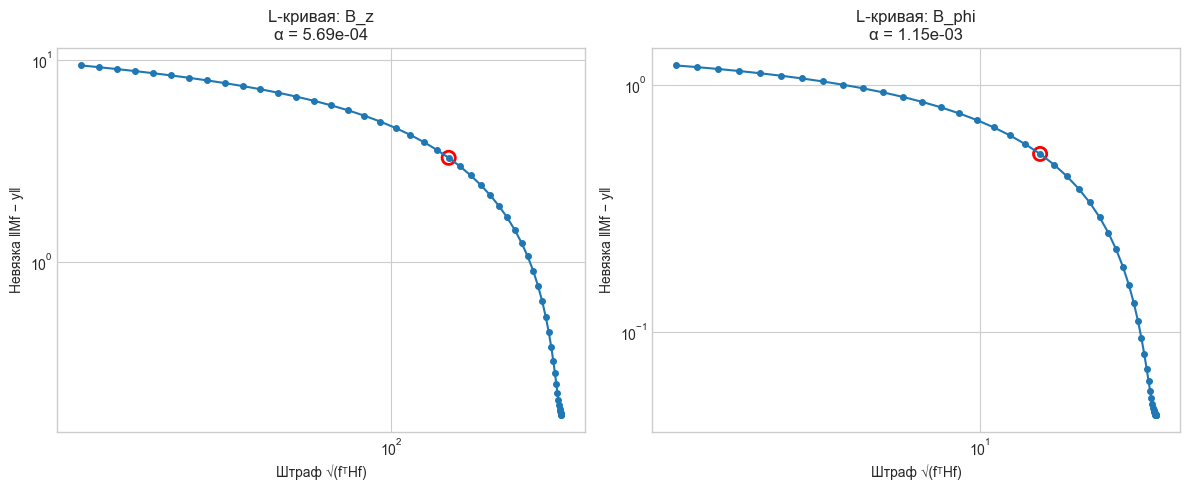

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


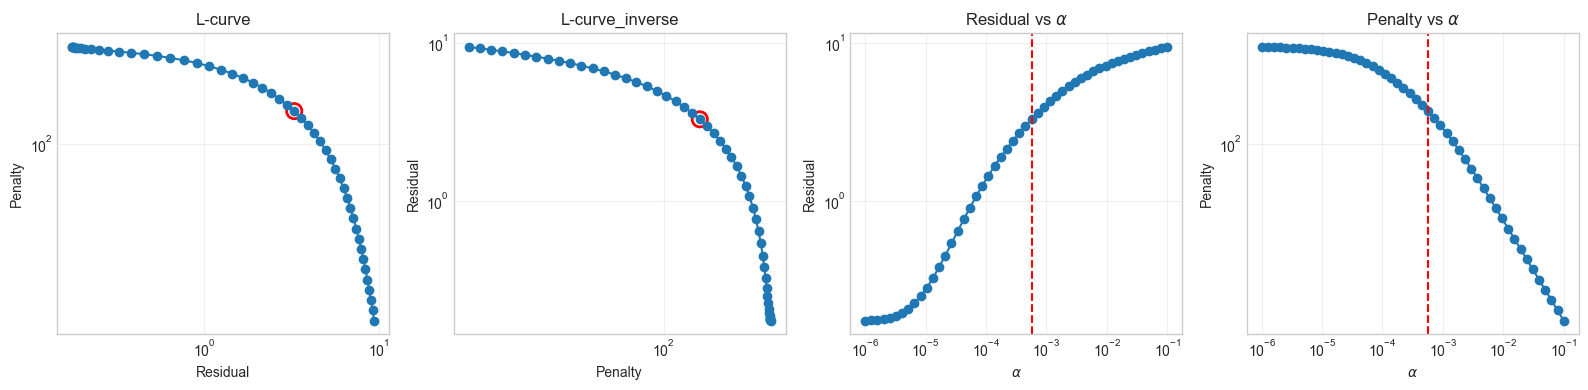

ε(B_z)   = 2.0592e+00
ε(B_phi) = 0.0000e+00


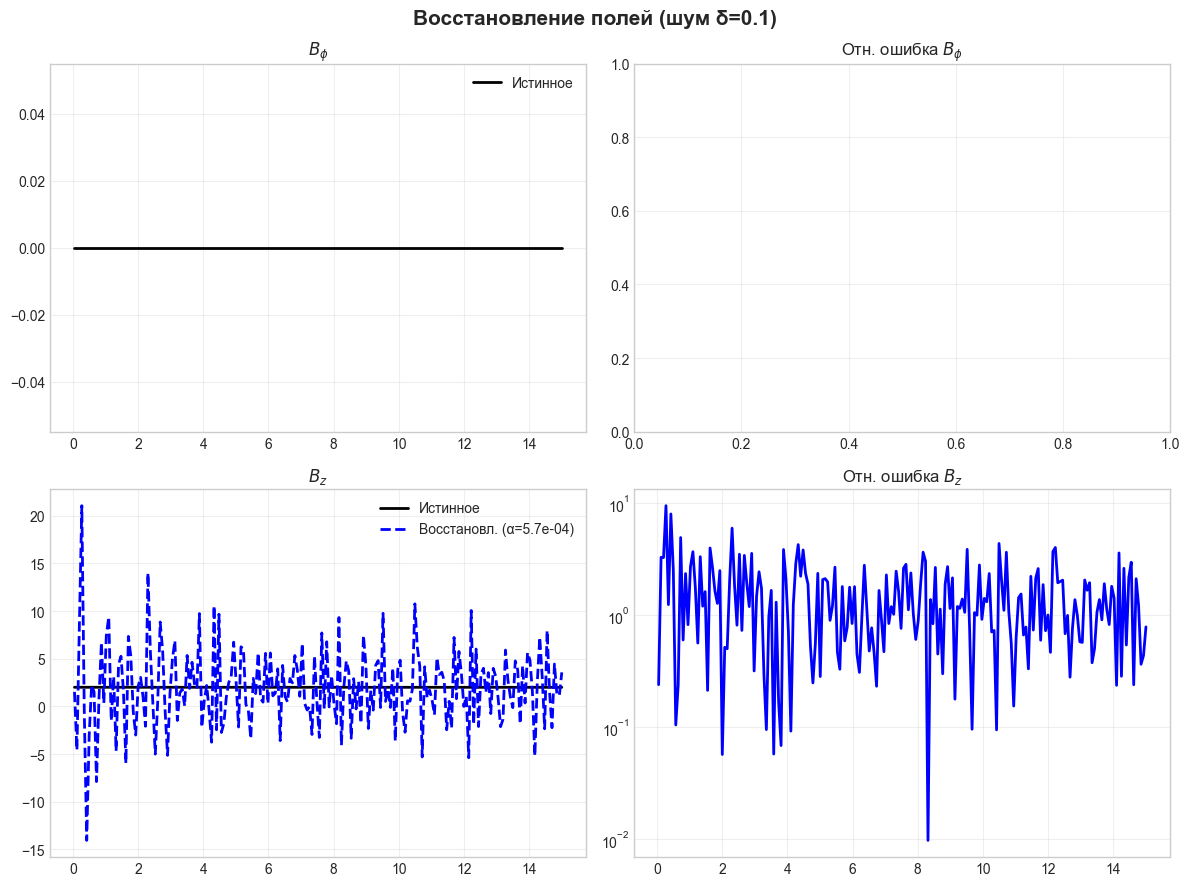

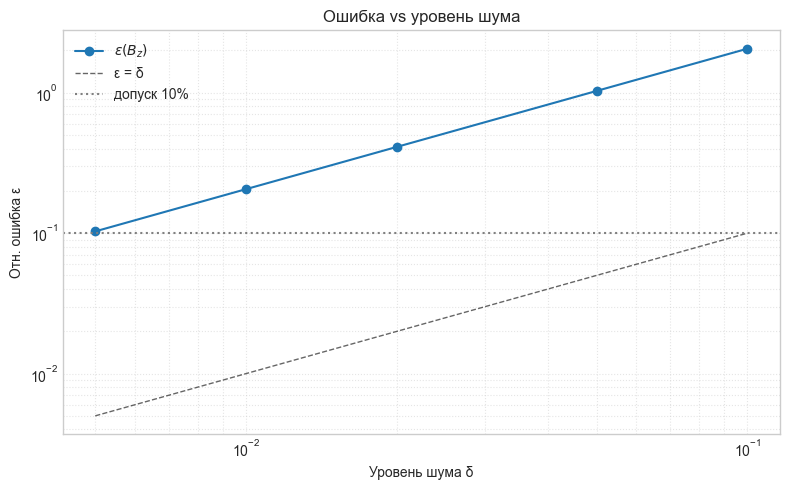

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


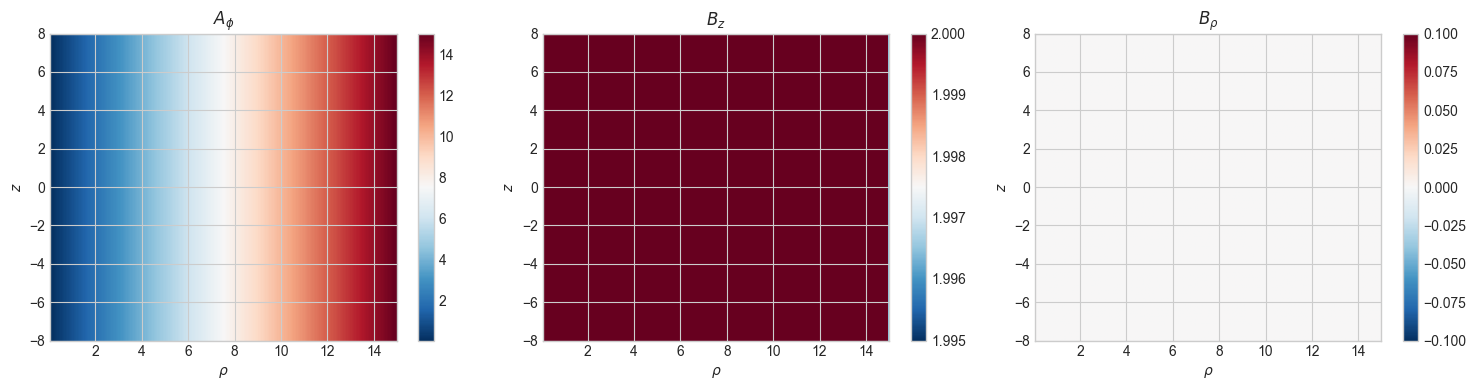

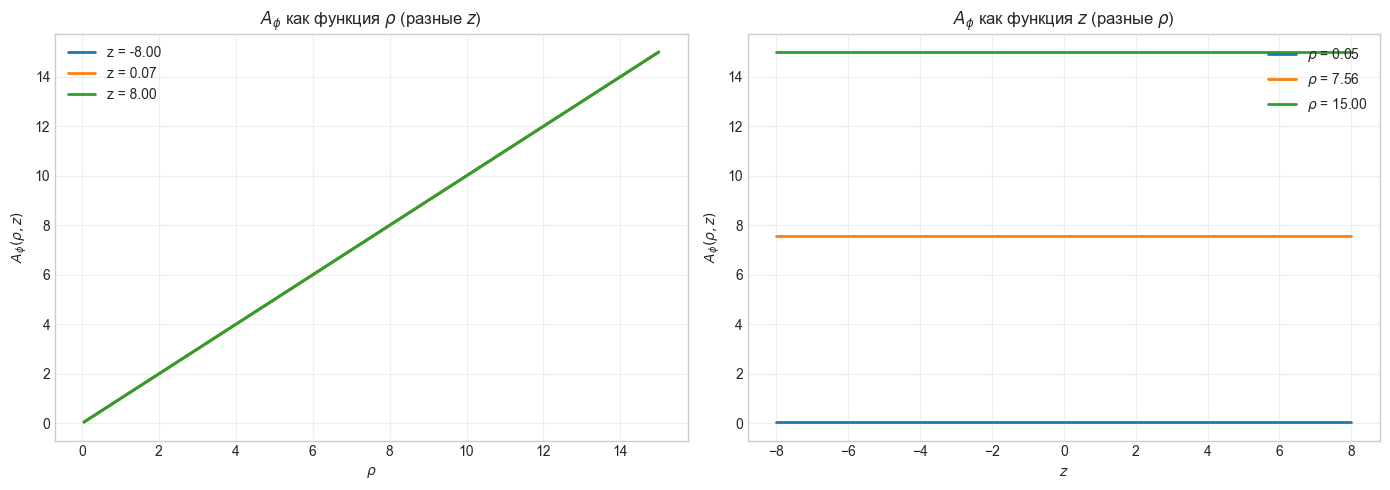

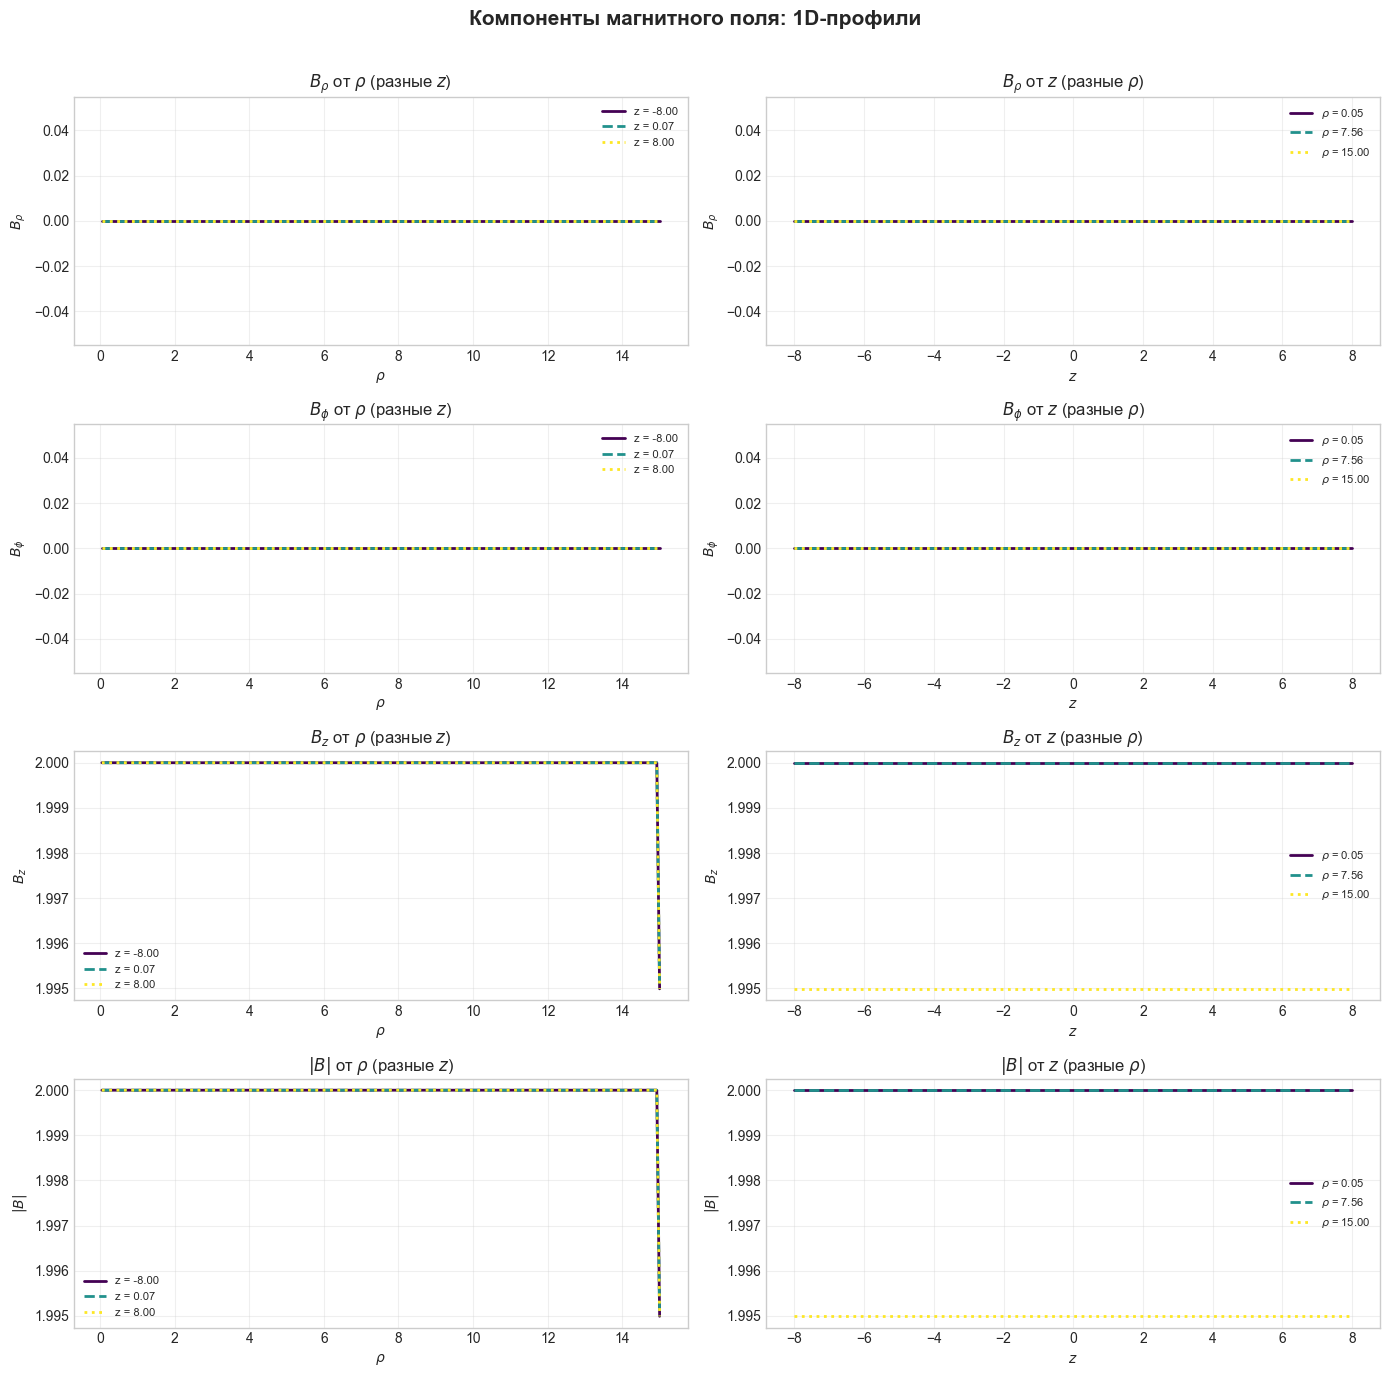

Осевой срез z = 0.07
max|B_z| = 2.0000,  max|B_phi| = 0.0000


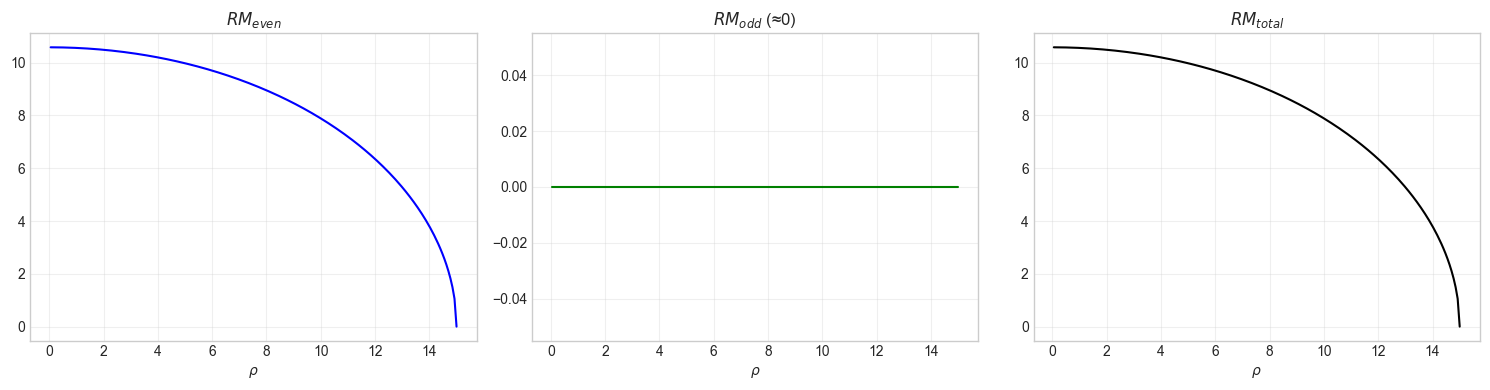

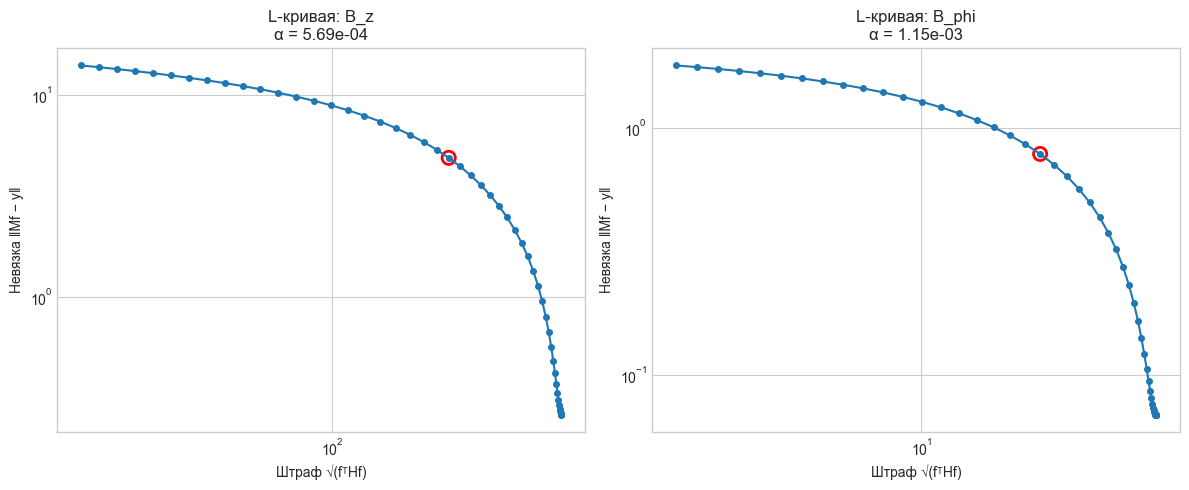

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


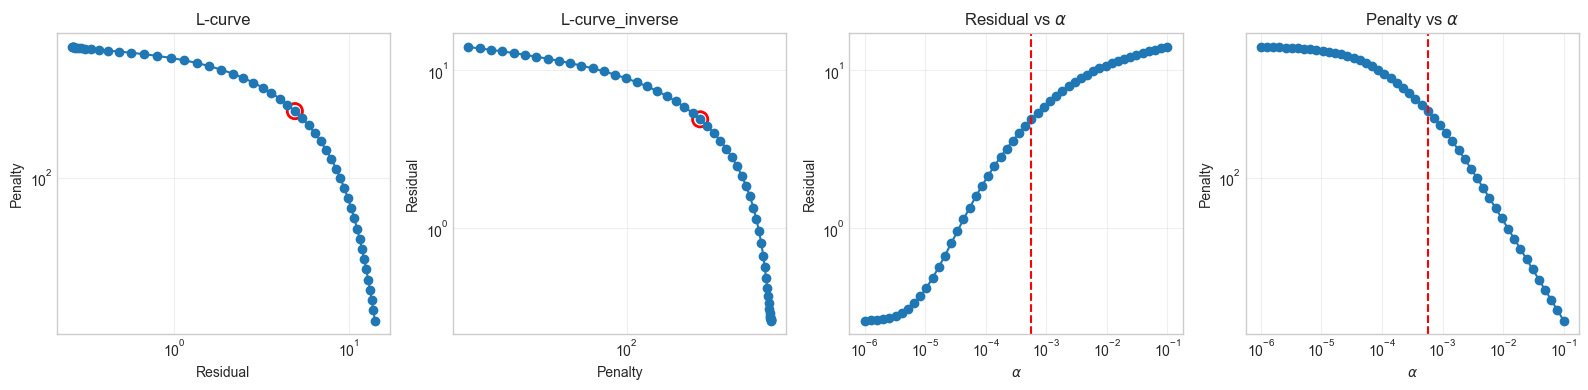

ε(B_z)   = 3.0888e+00
ε(B_phi) = 0.0000e+00


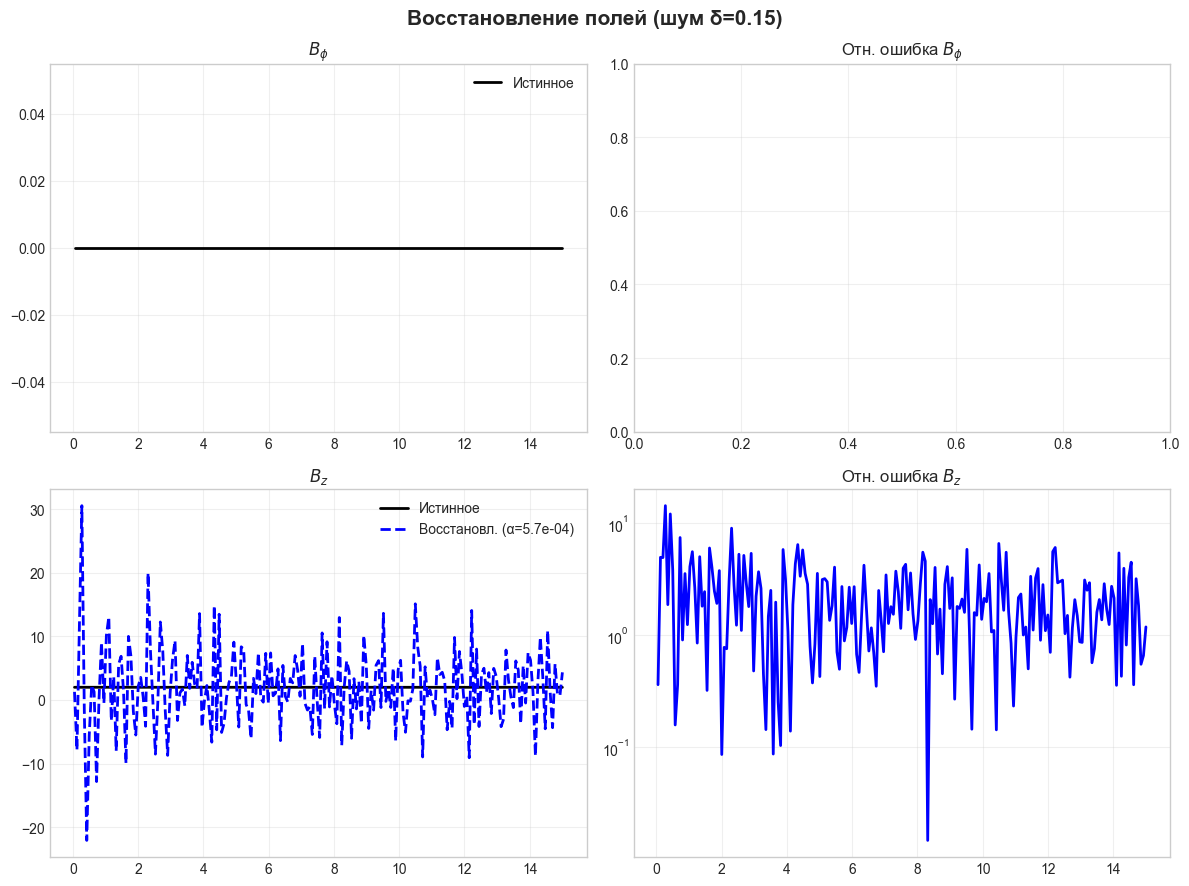

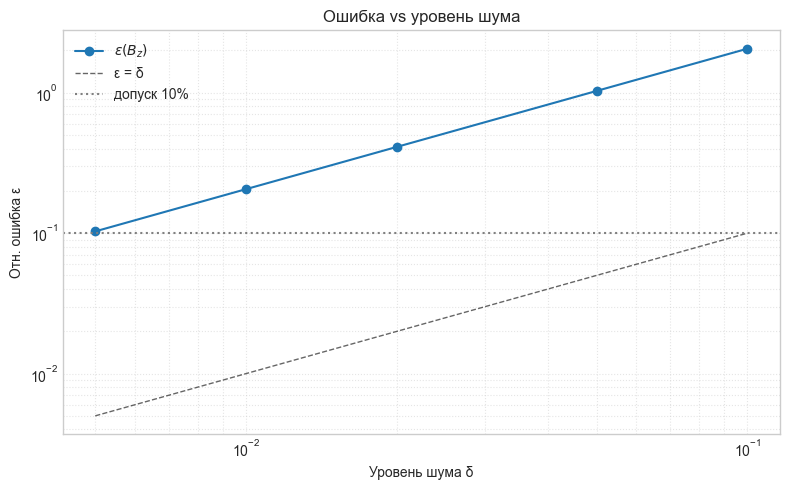

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


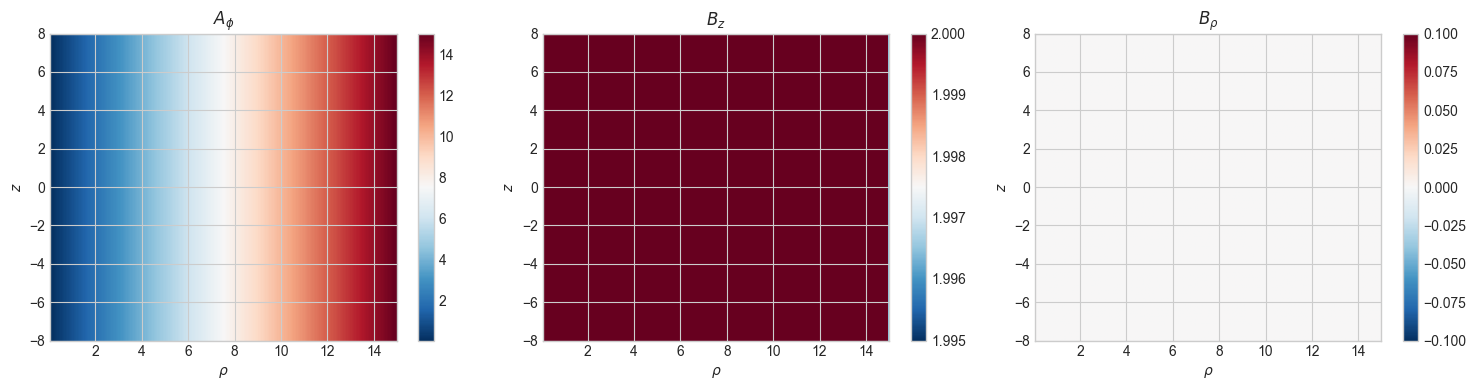

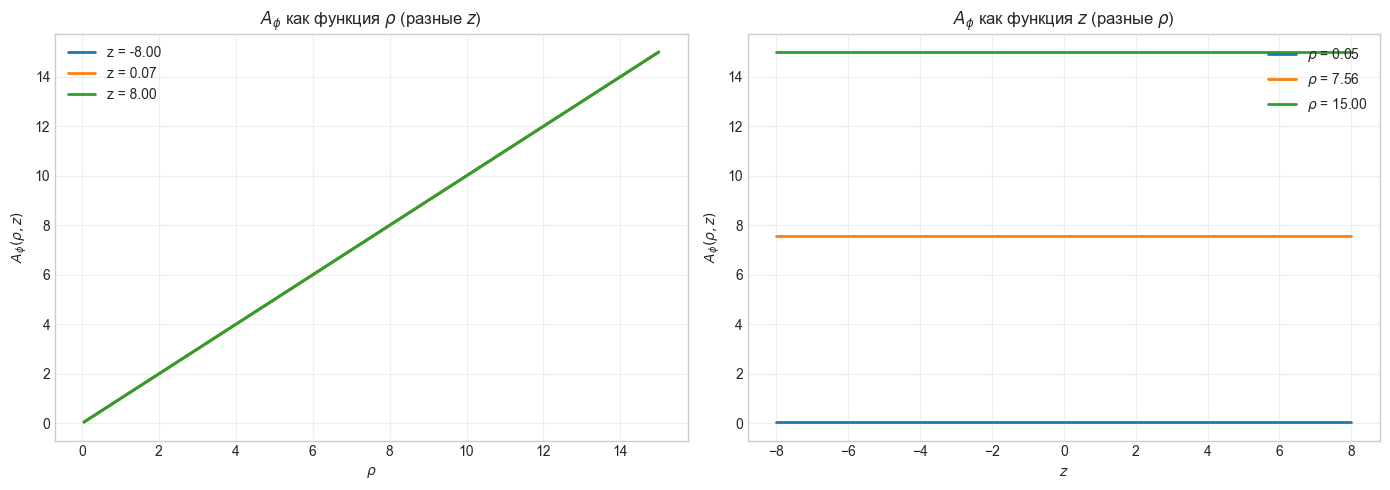

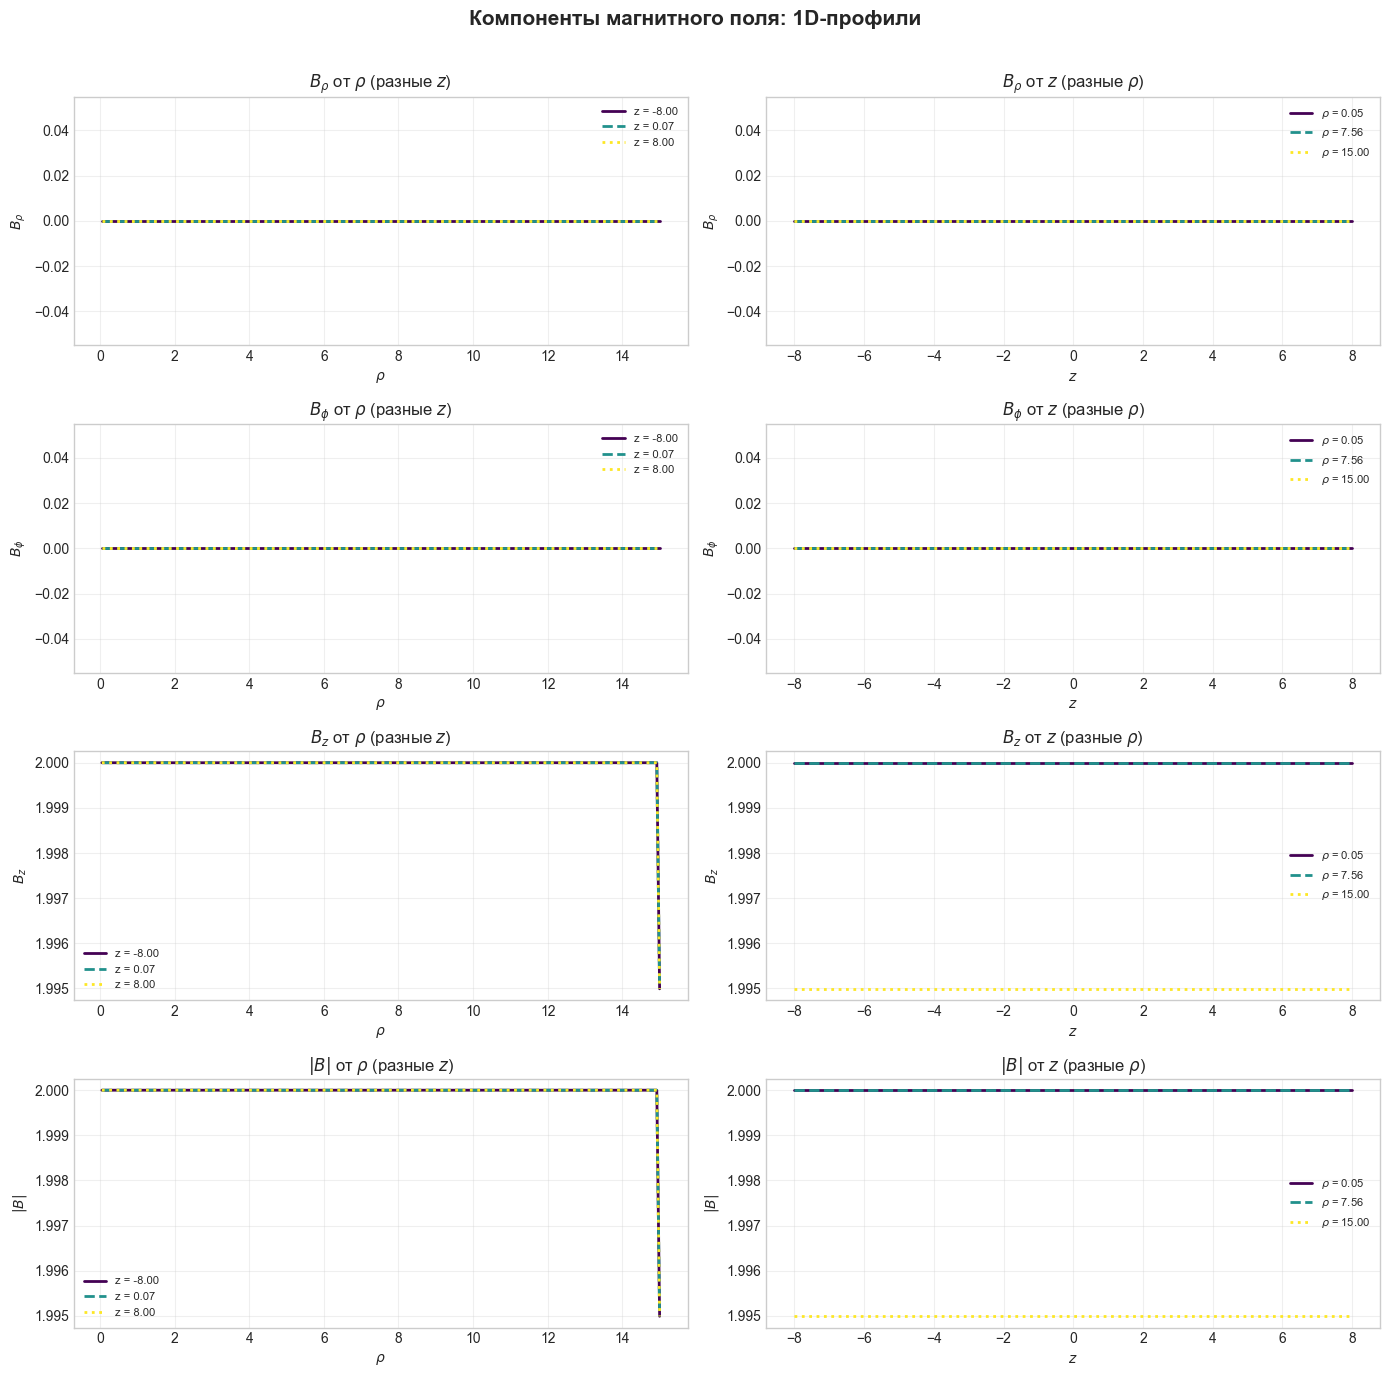

Осевой срез z = 0.07
max|B_z| = 2.0000,  max|B_phi| = 0.0000


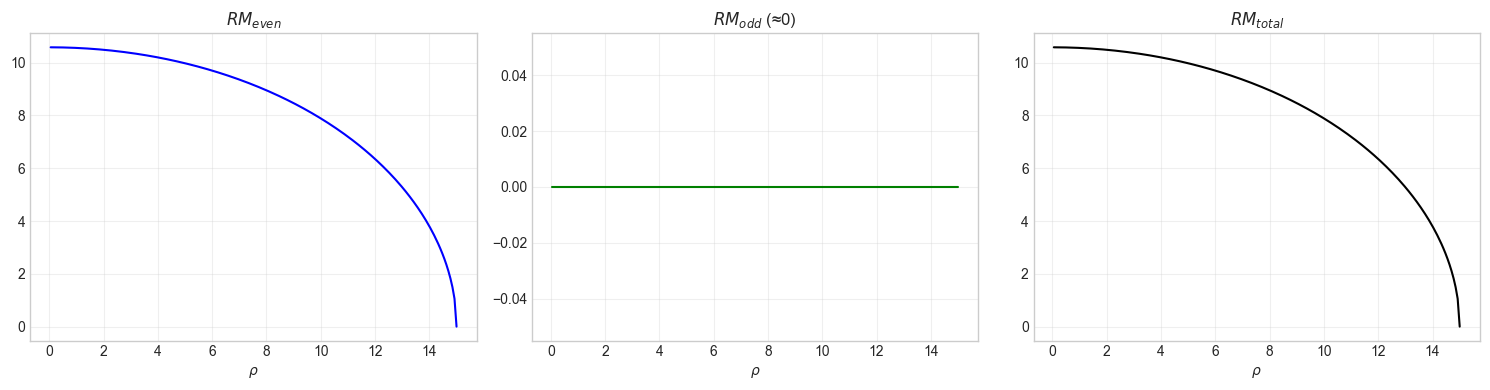

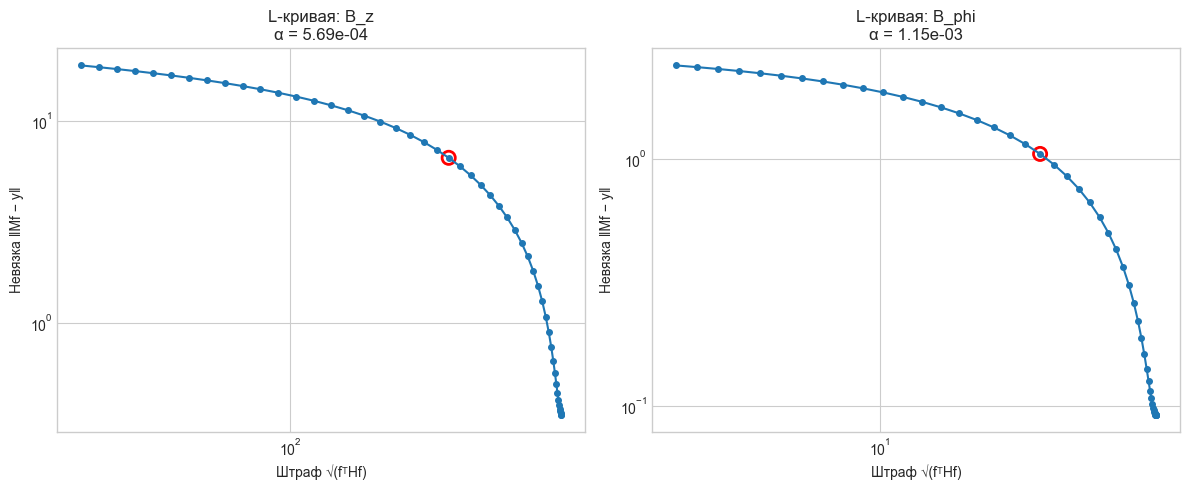

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


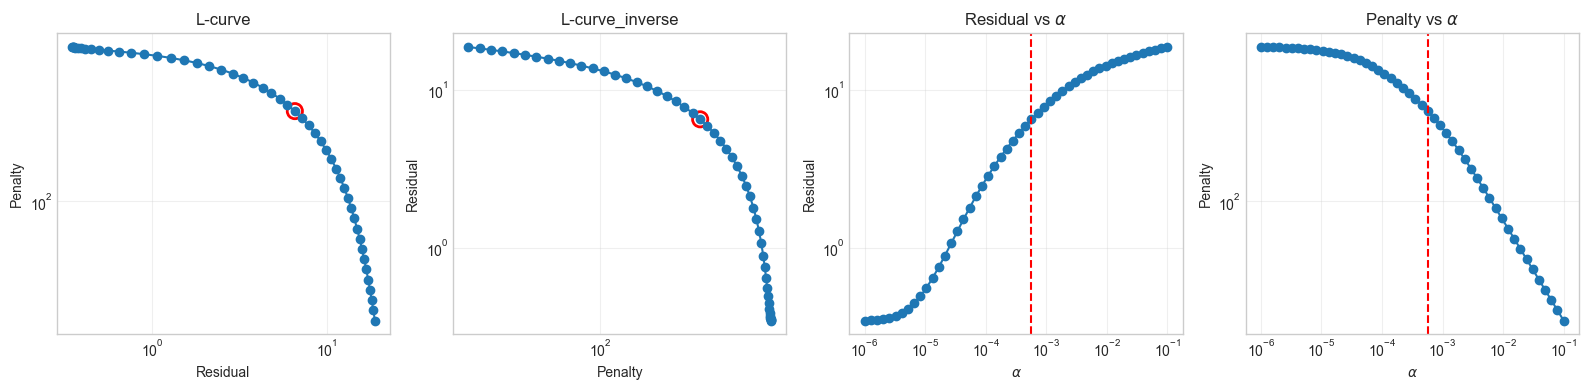

ε(B_z)   = 4.1185e+00
ε(B_phi) = 0.0000e+00


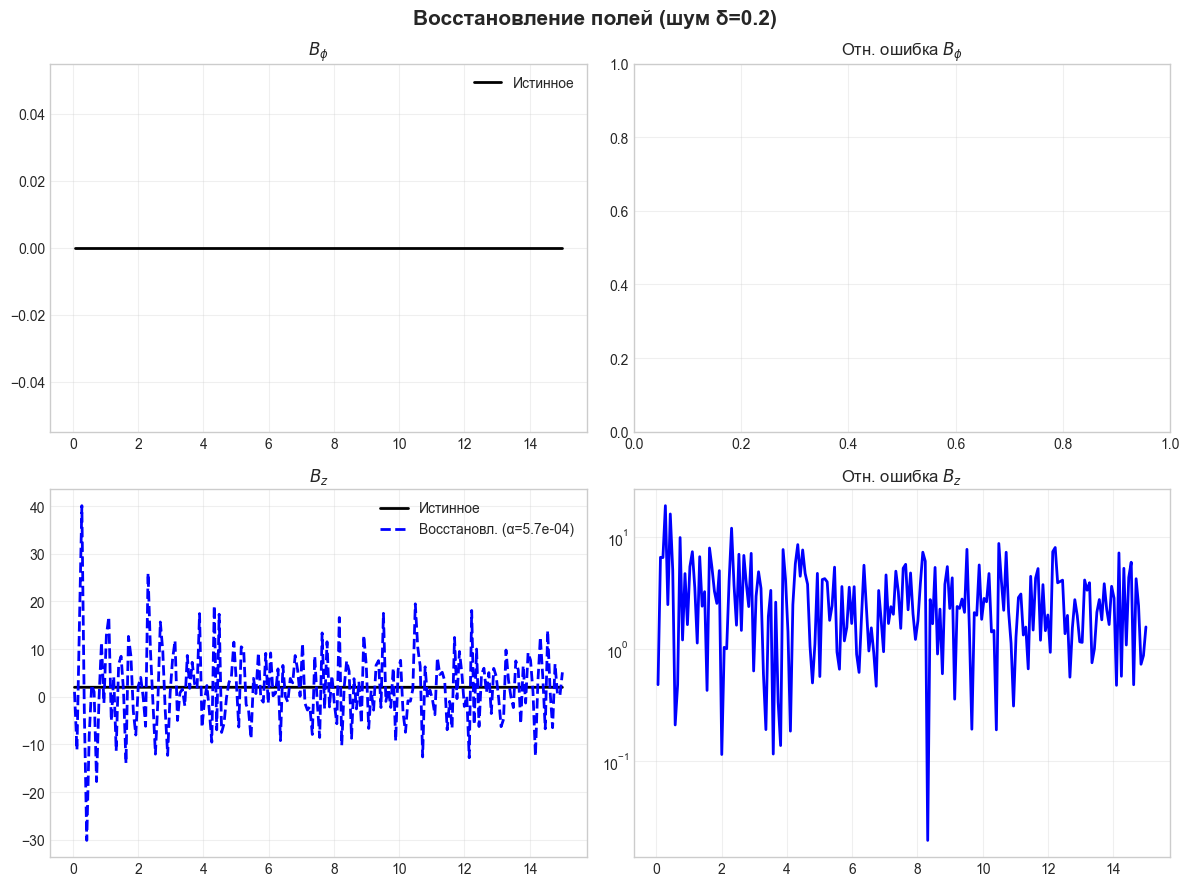

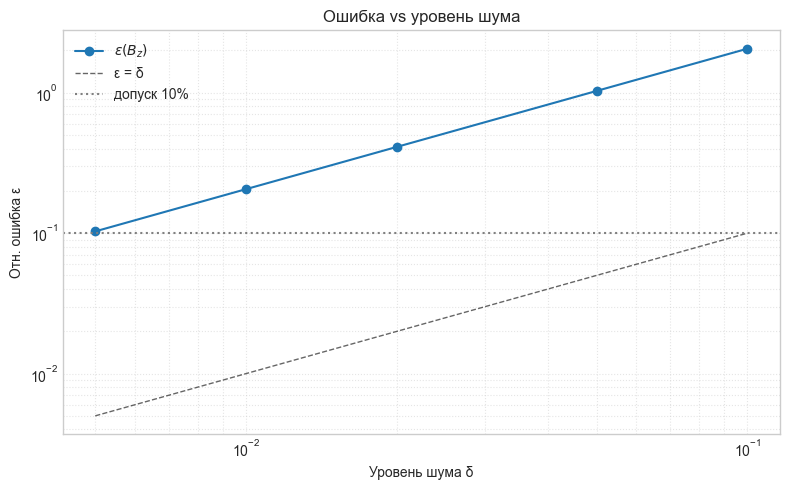

In [6]:
for delta in delta_arr:
    Calculate(A_phi_uniform, delta= delta)

# $A_\phi = \rho ^ 2$

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


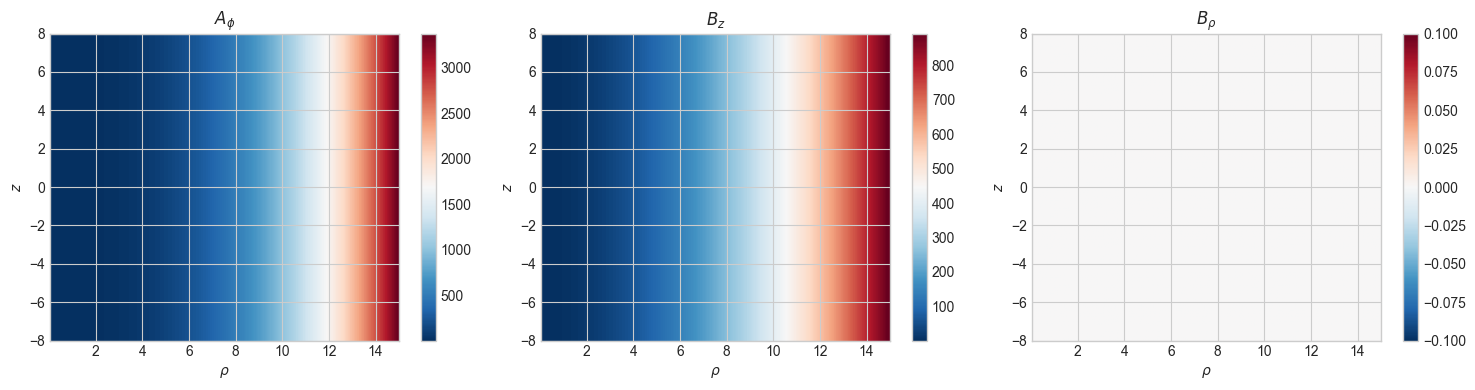

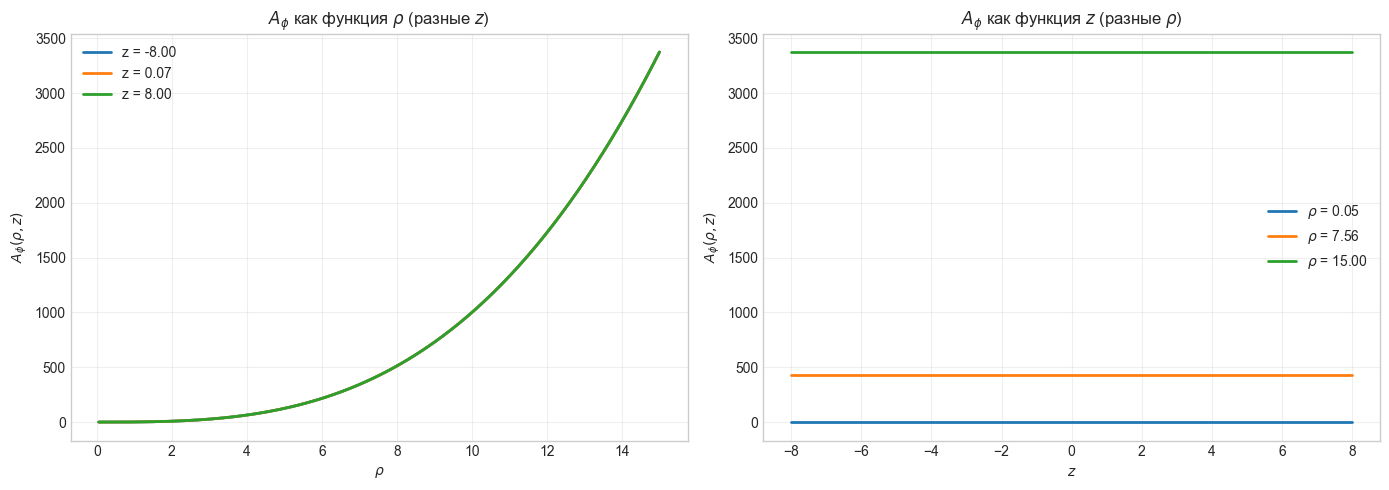

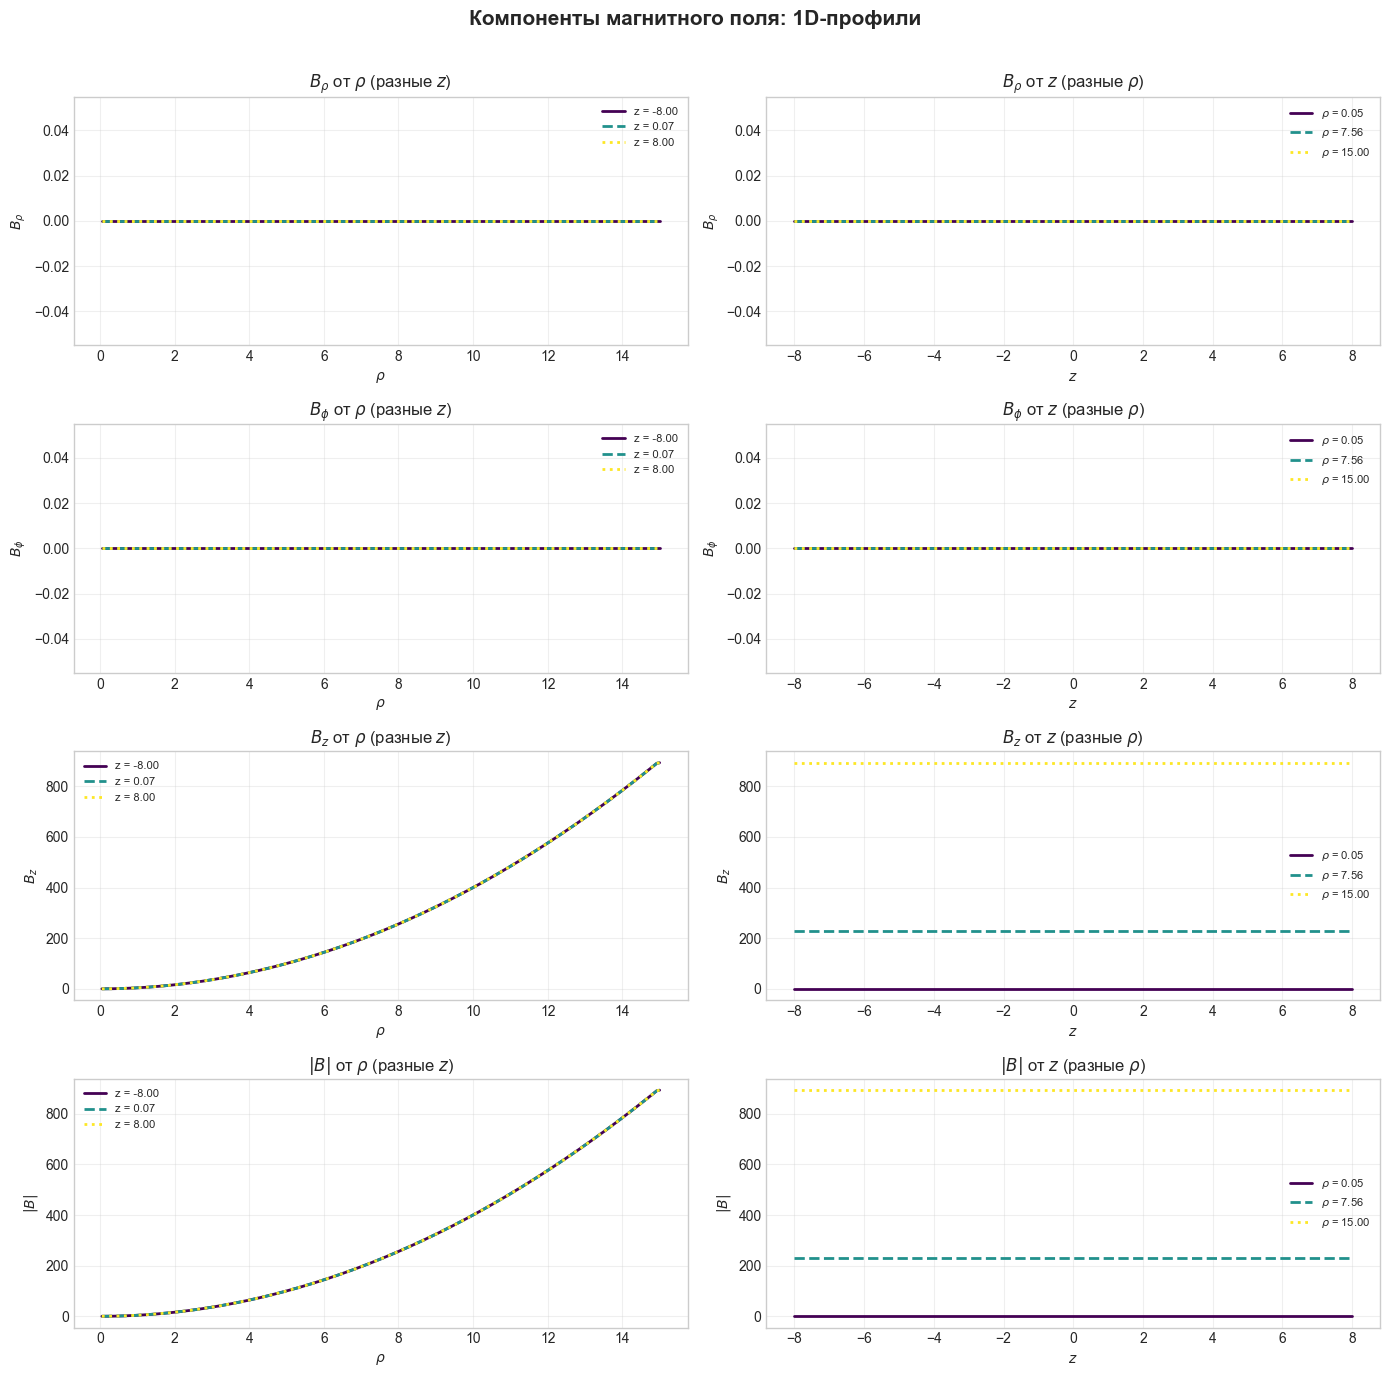

Осевой срез z = 0.07
max|B_z| = 893.2612,  max|B_phi| = 0.0000


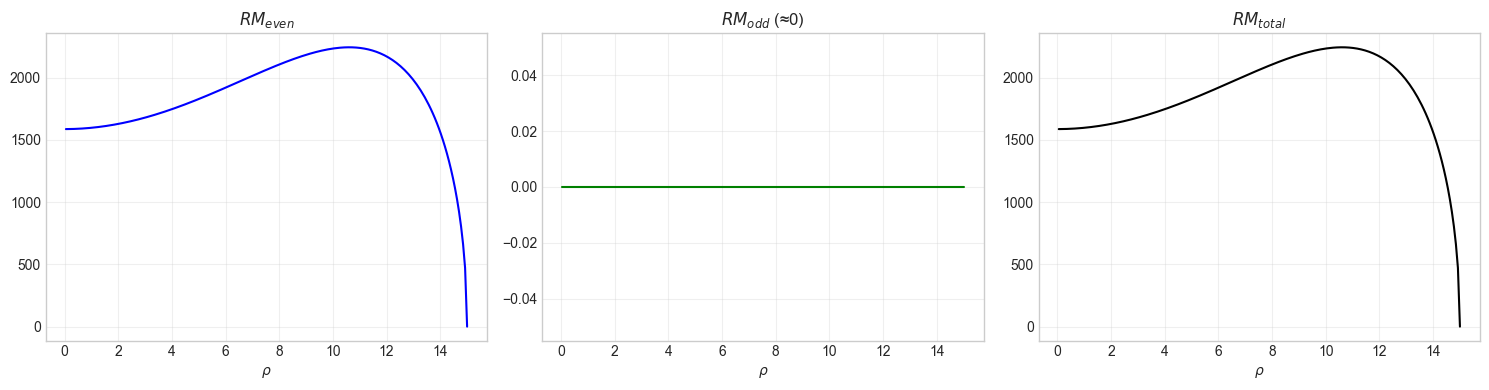

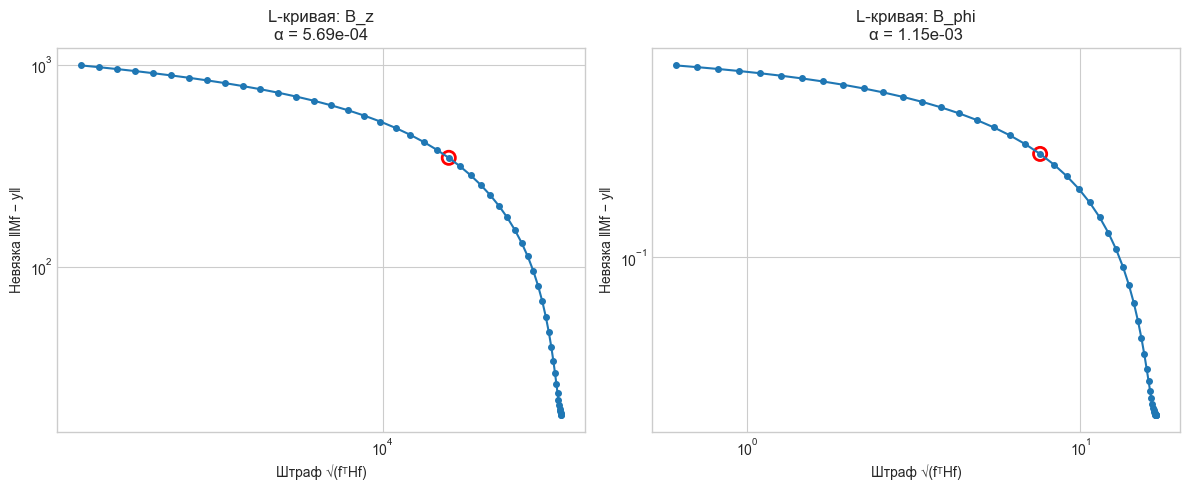

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


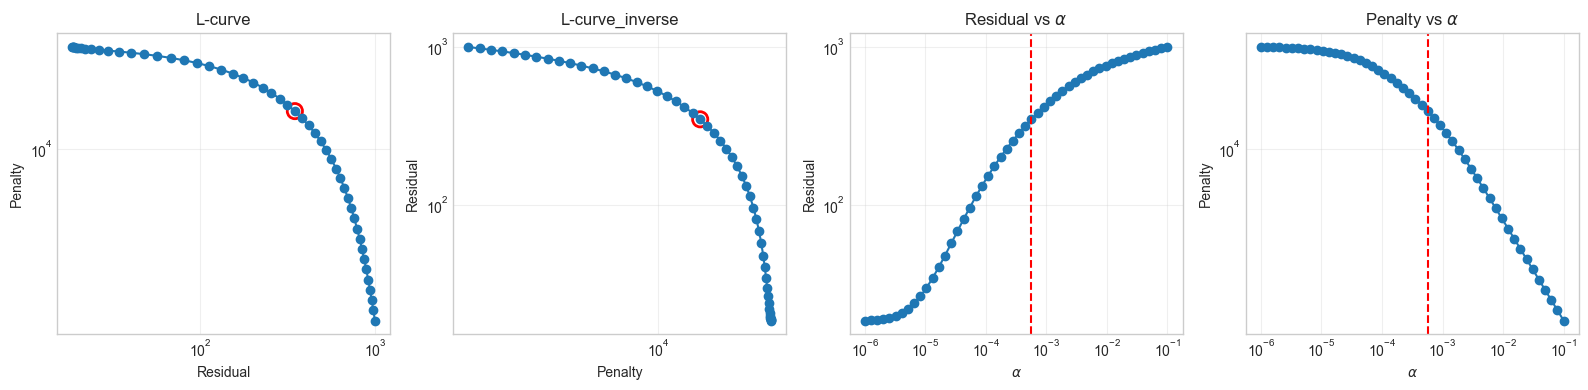

ε(B_z)   = 1.0796e+00
ε(B_phi) = 0.0000e+00


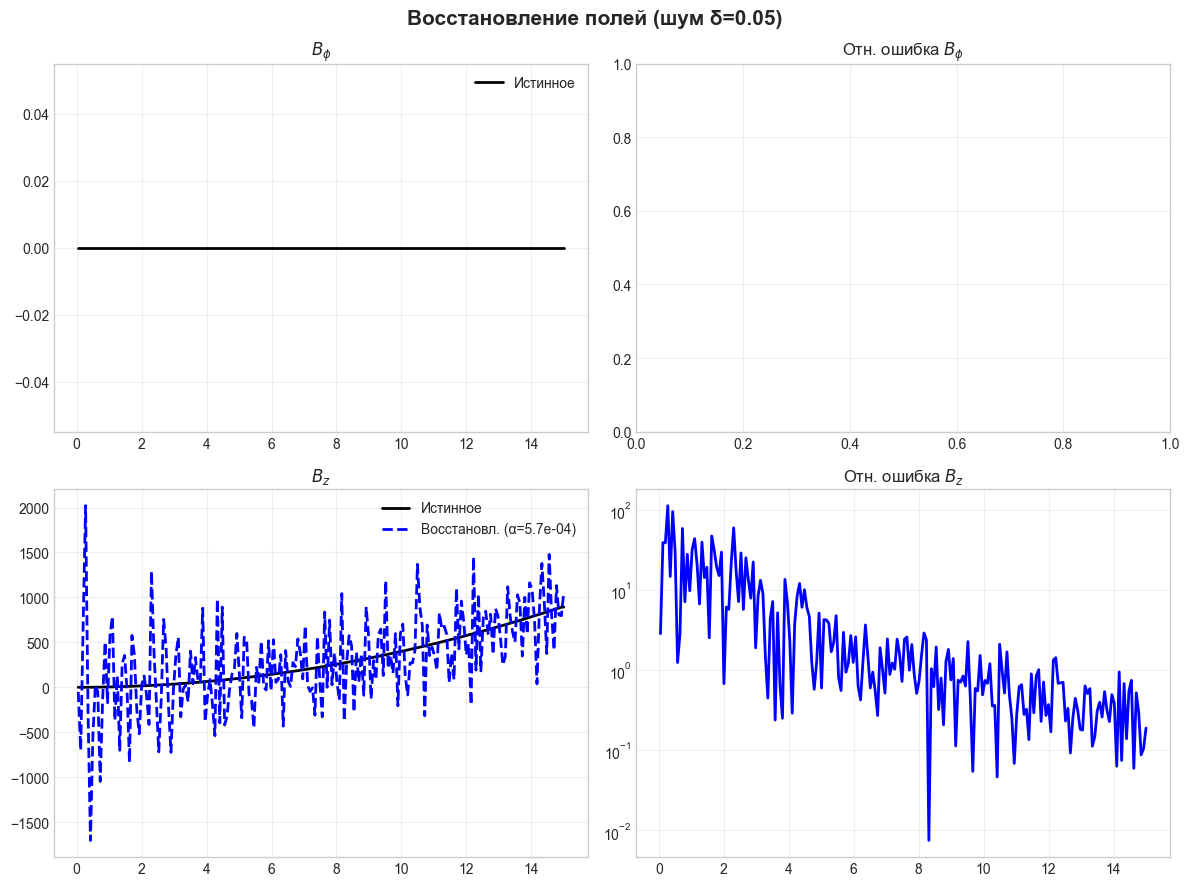

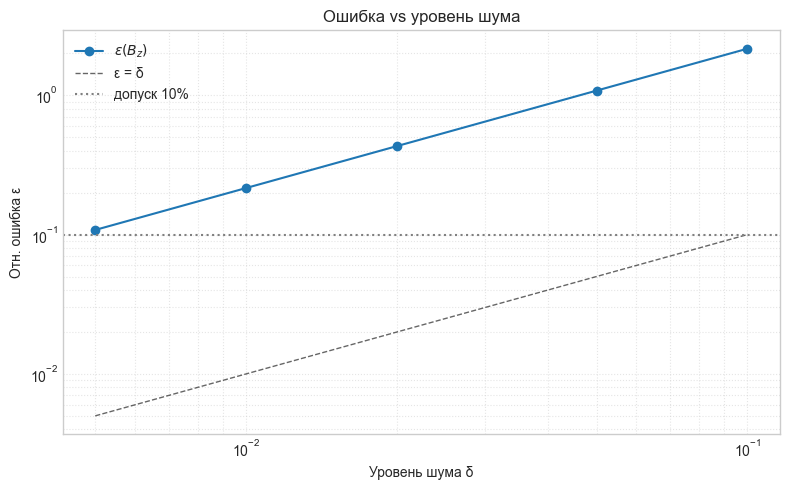

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


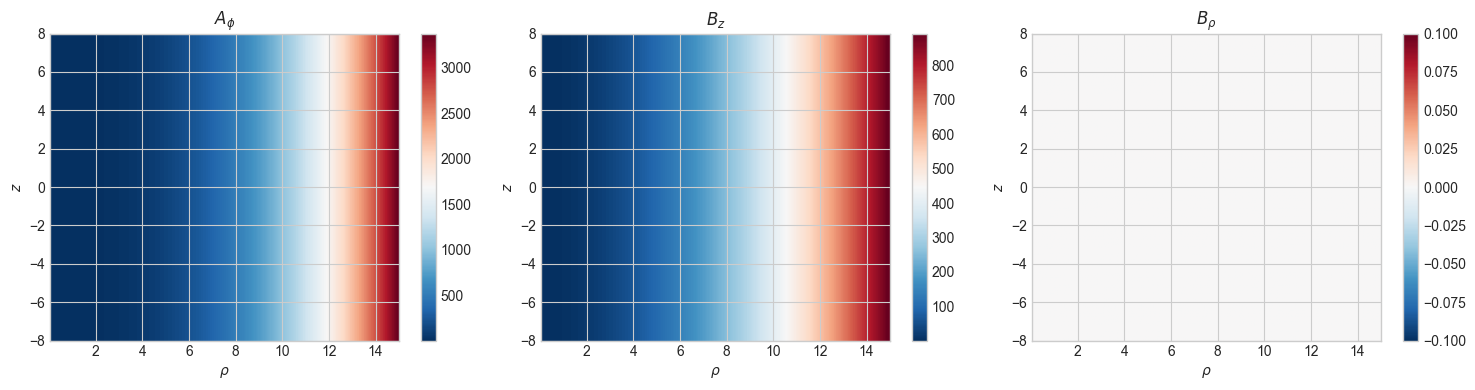

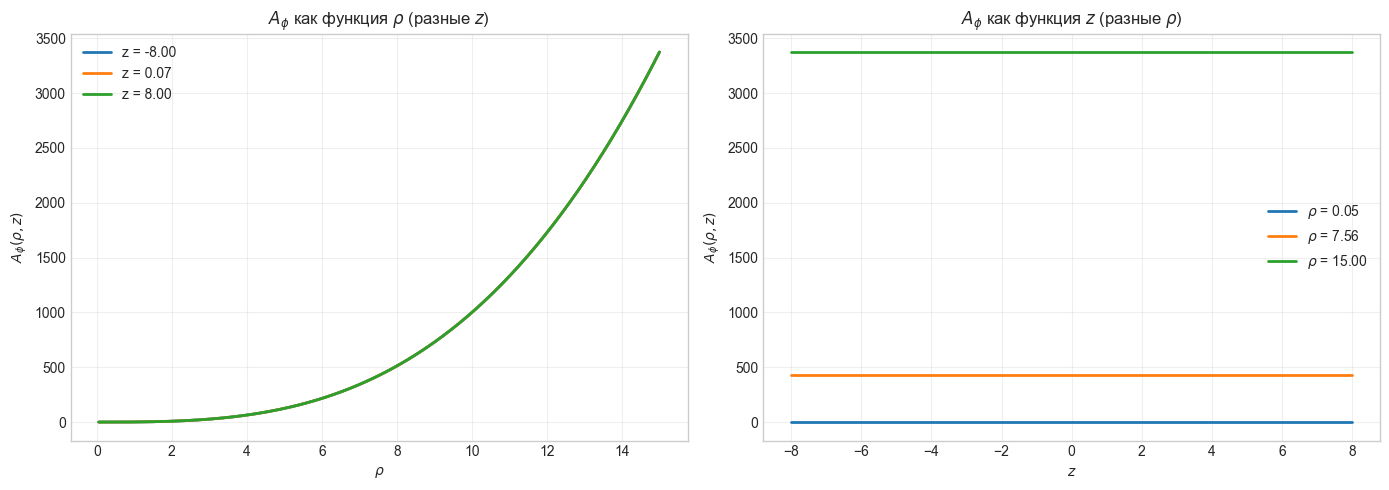

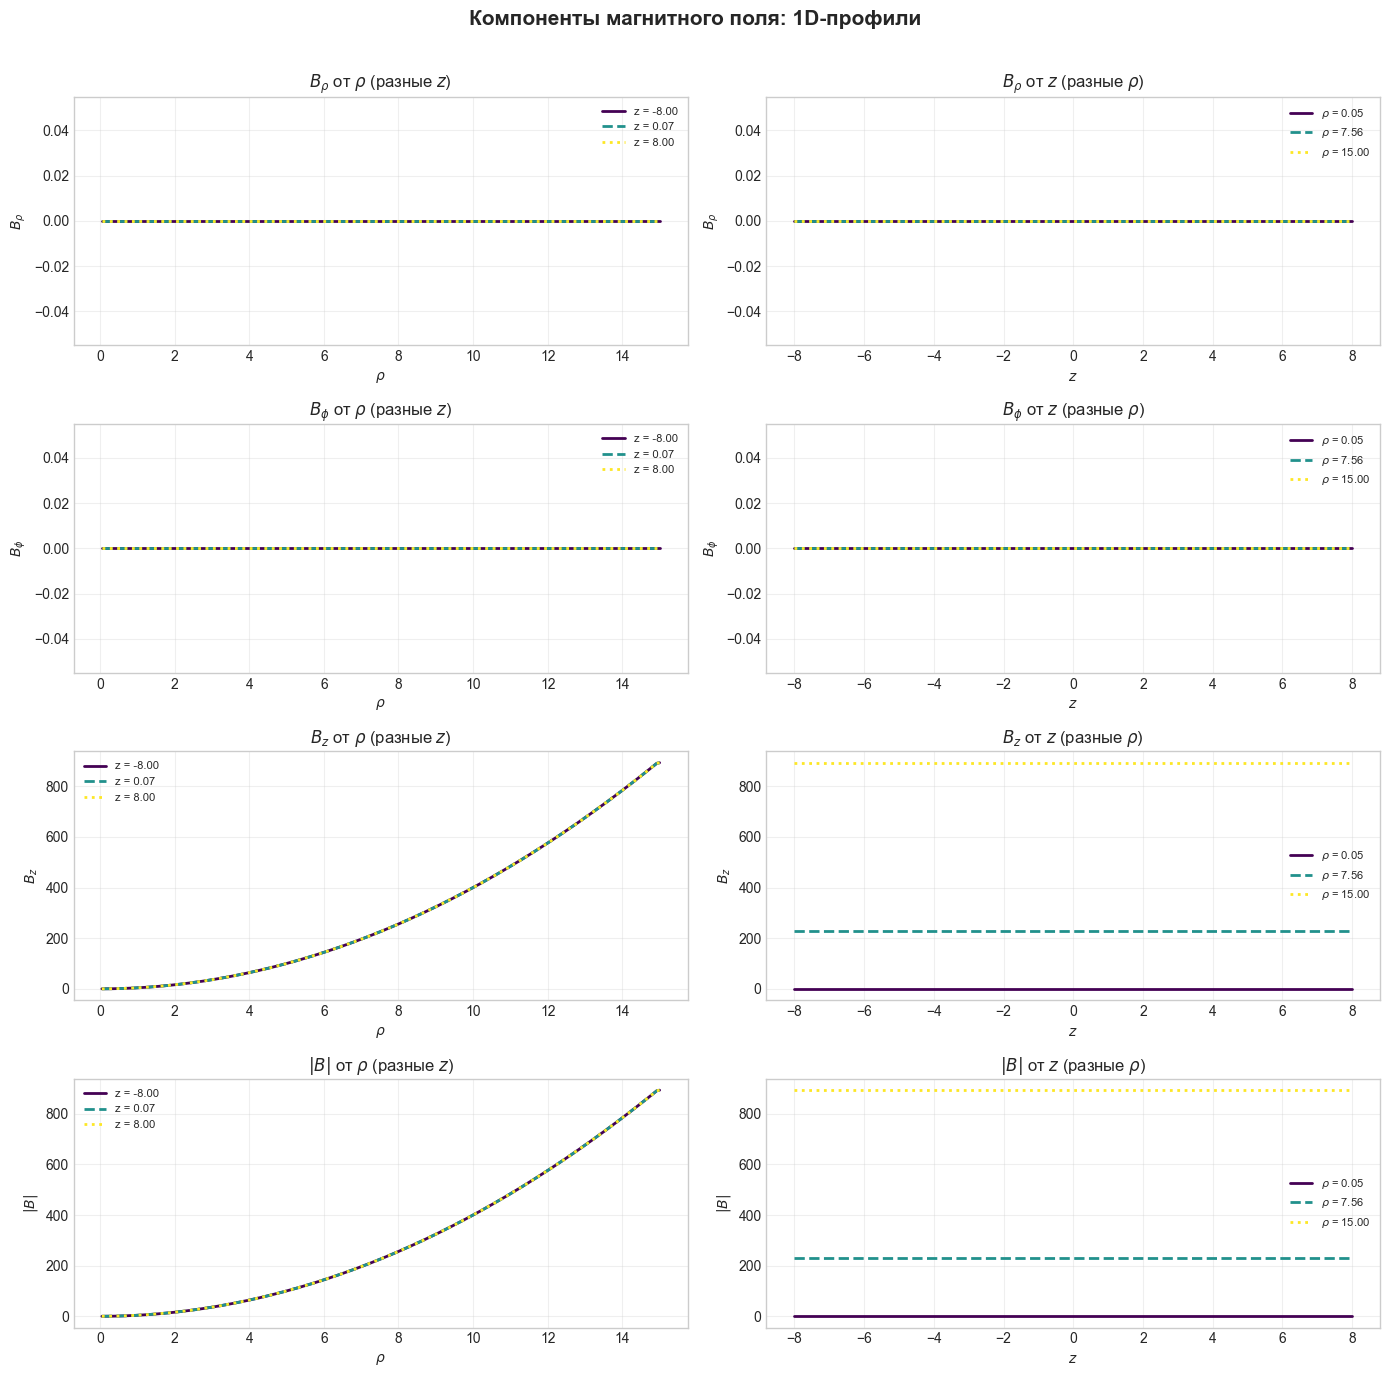

Осевой срез z = 0.07
max|B_z| = 893.2612,  max|B_phi| = 0.0000


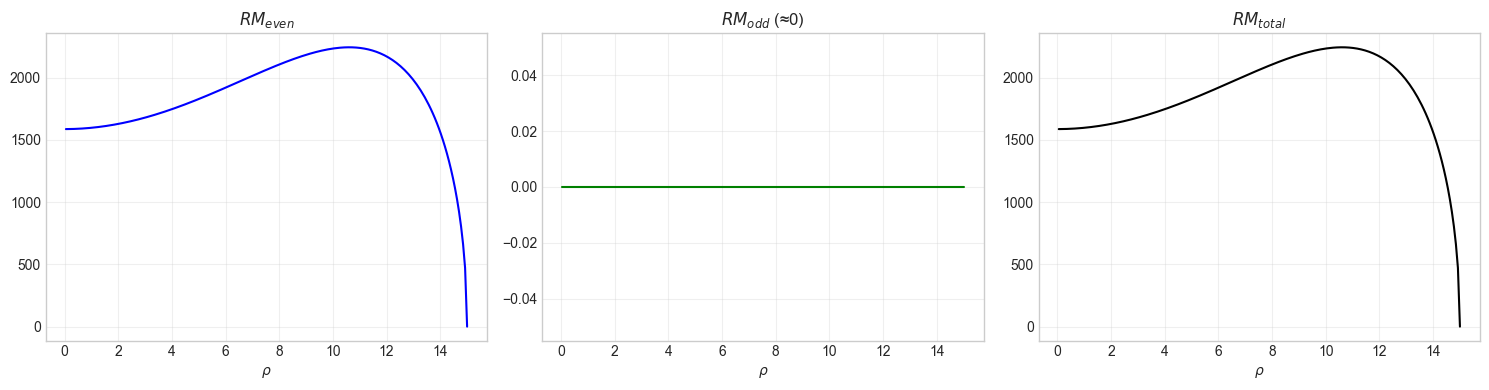

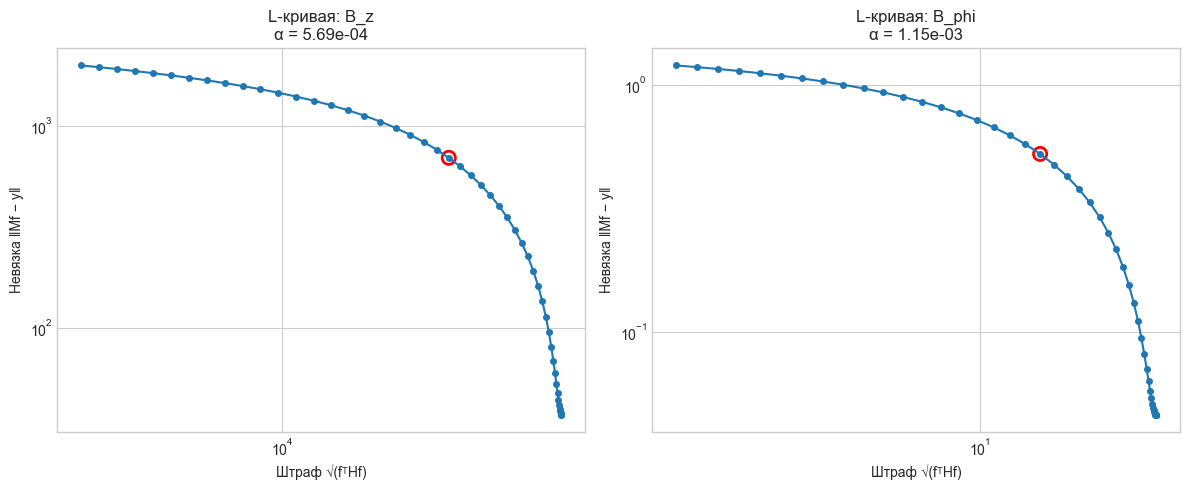

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


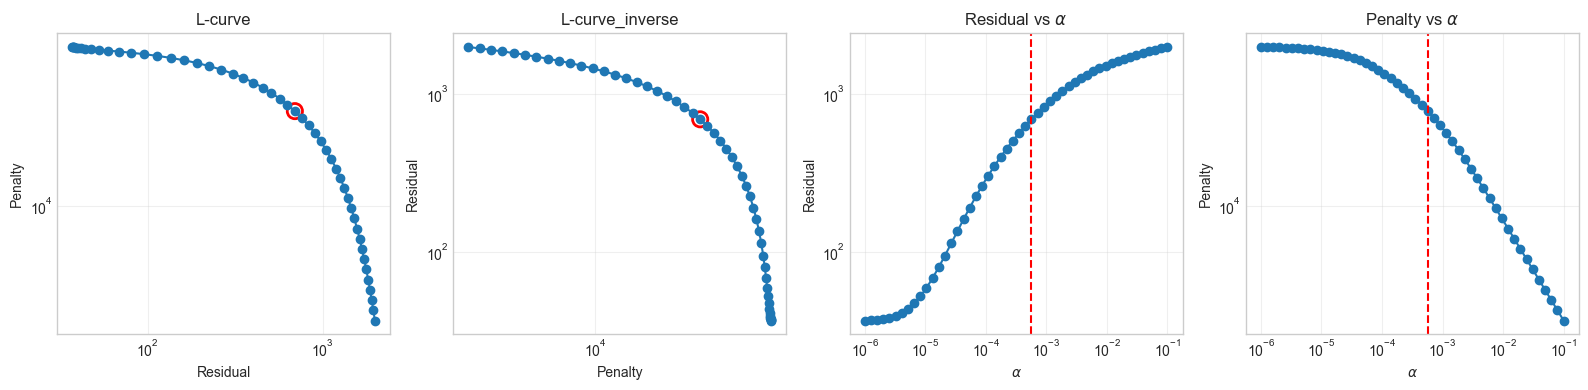

ε(B_z)   = 2.1592e+00
ε(B_phi) = 0.0000e+00


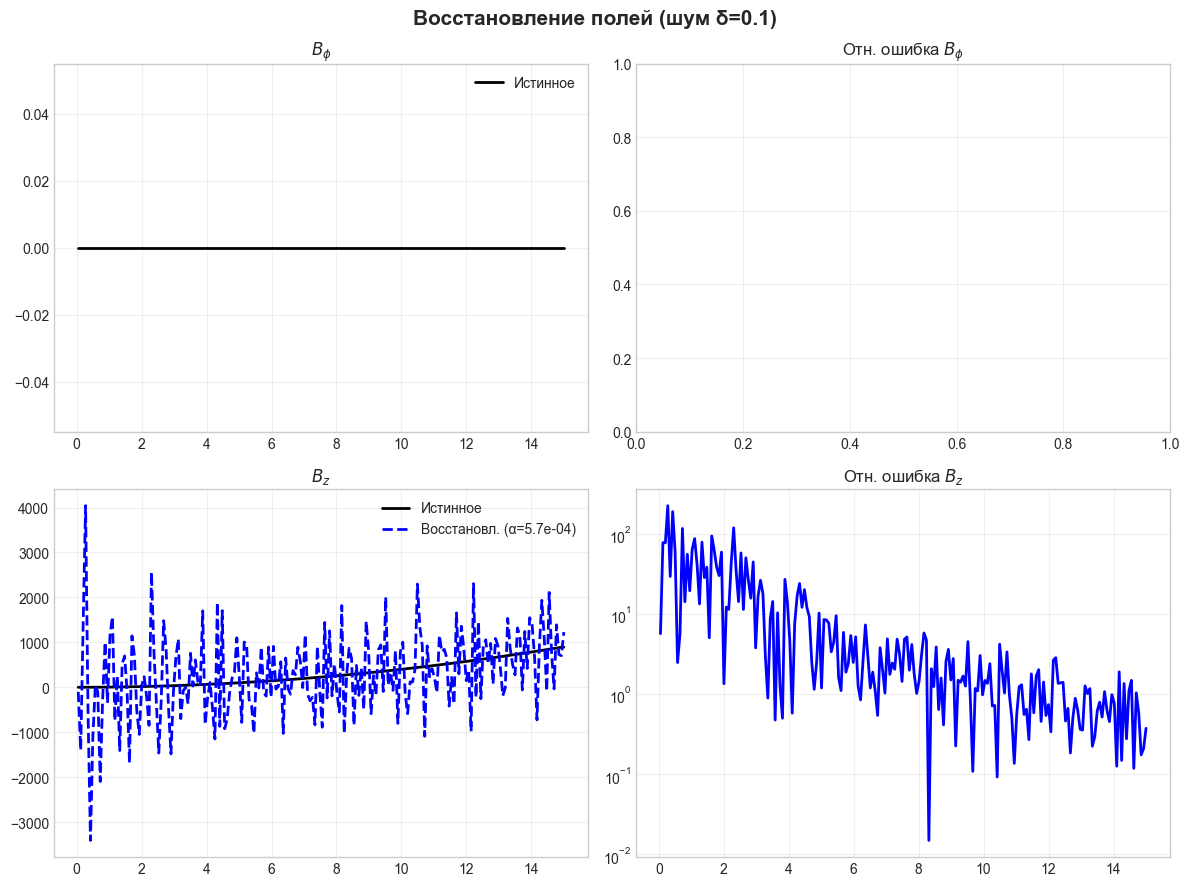

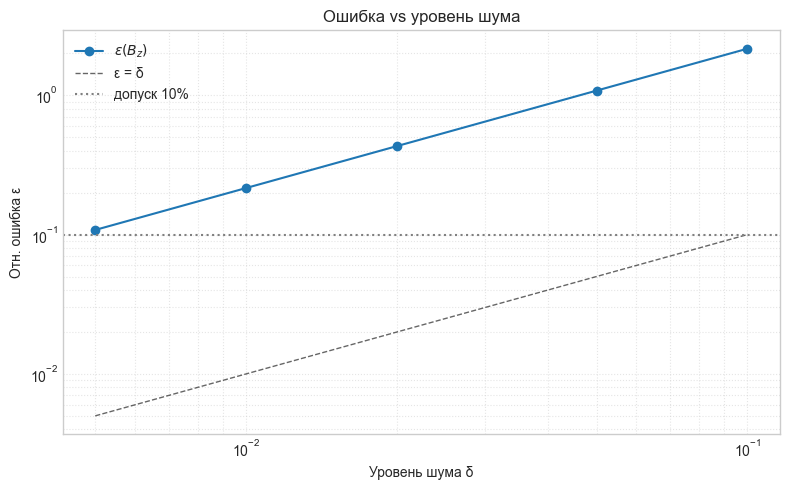

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


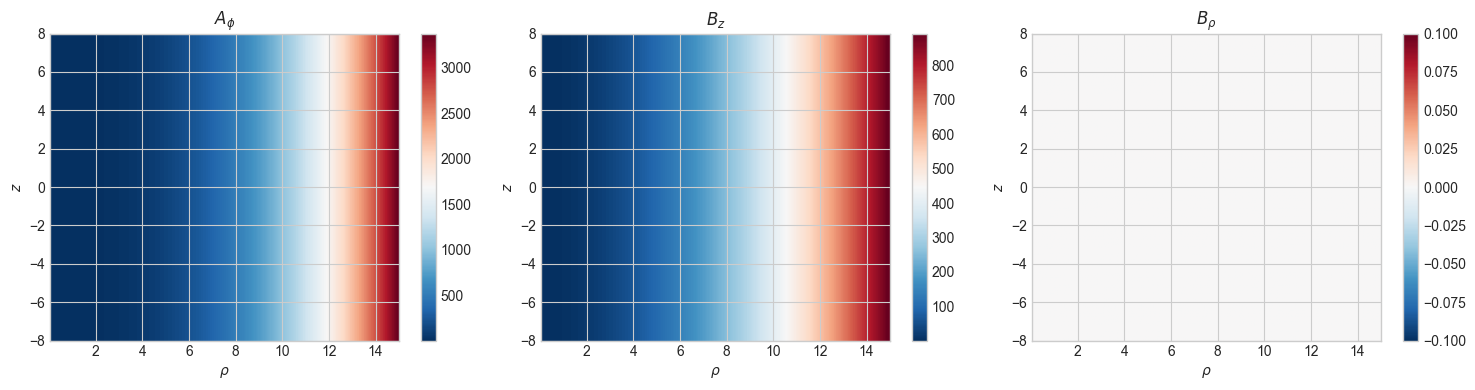

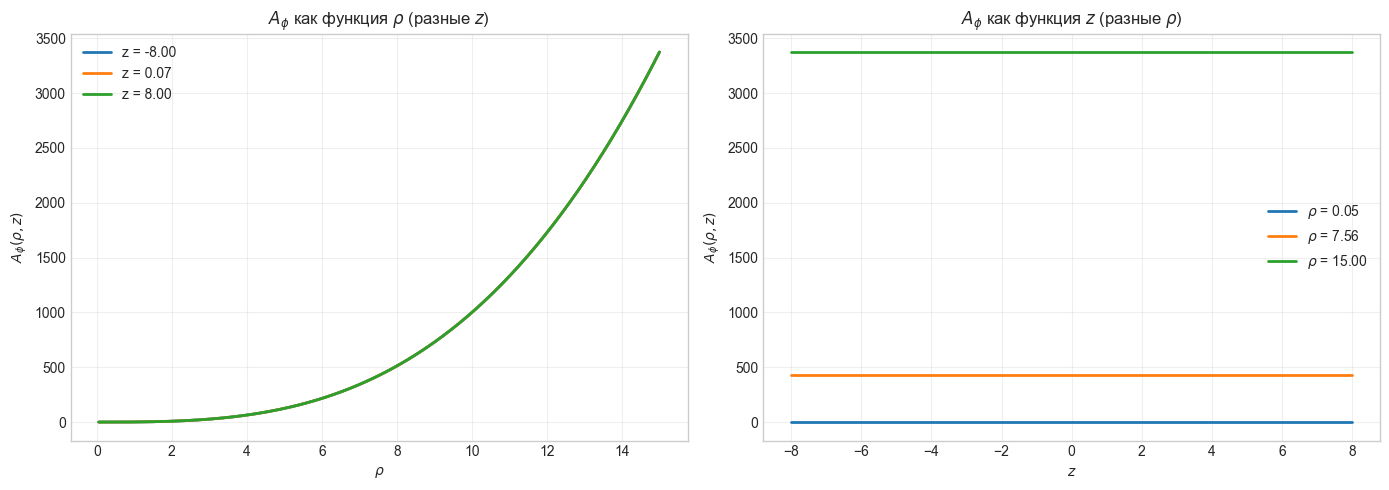

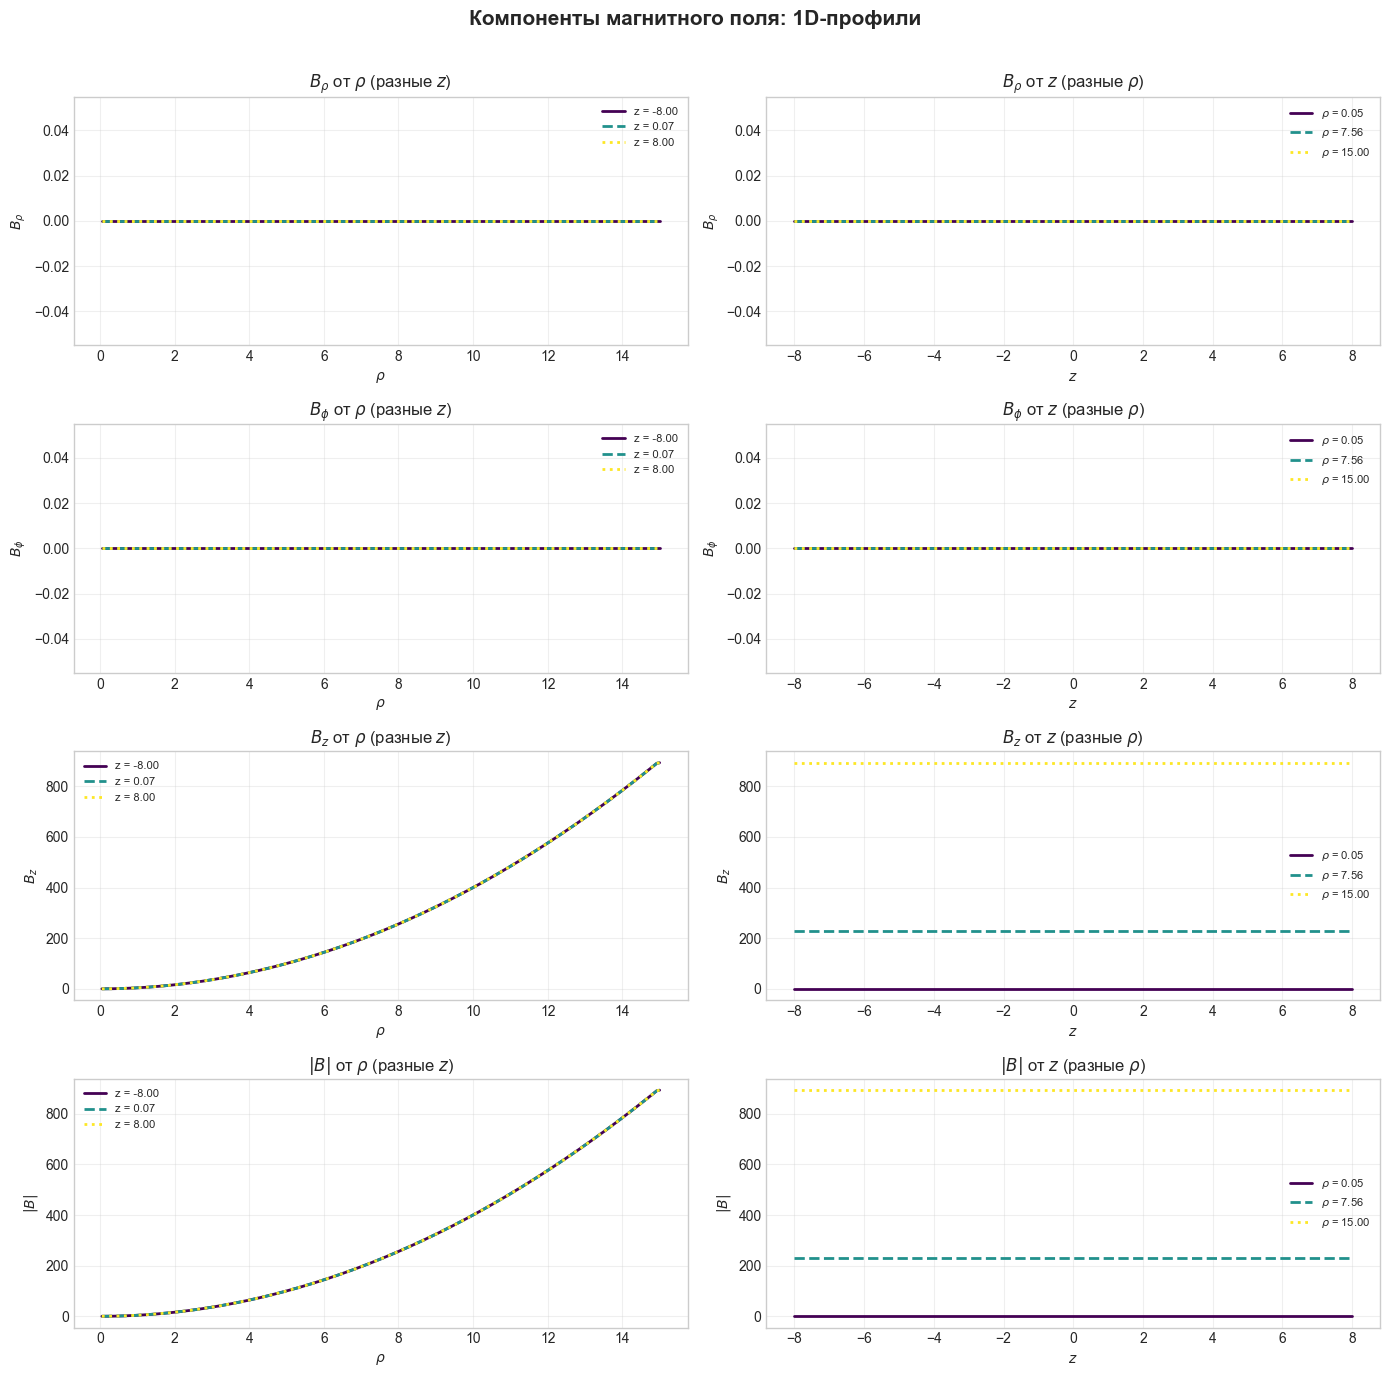

Осевой срез z = 0.07
max|B_z| = 893.2612,  max|B_phi| = 0.0000


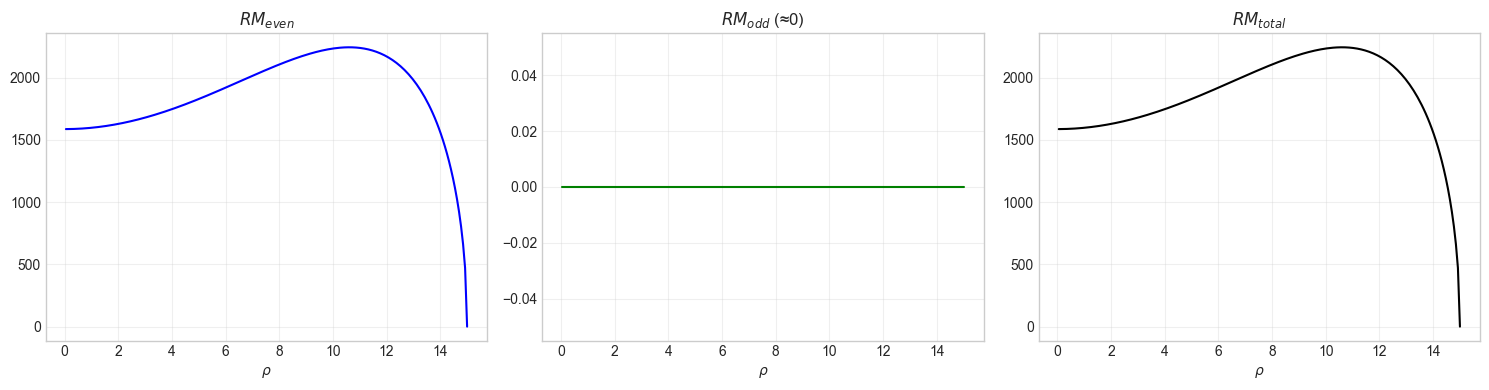

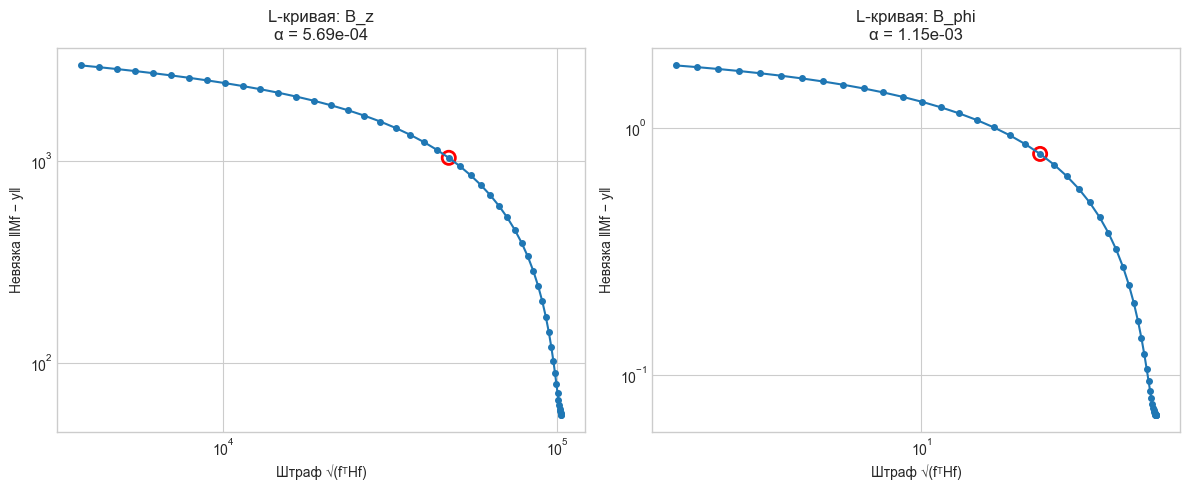

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


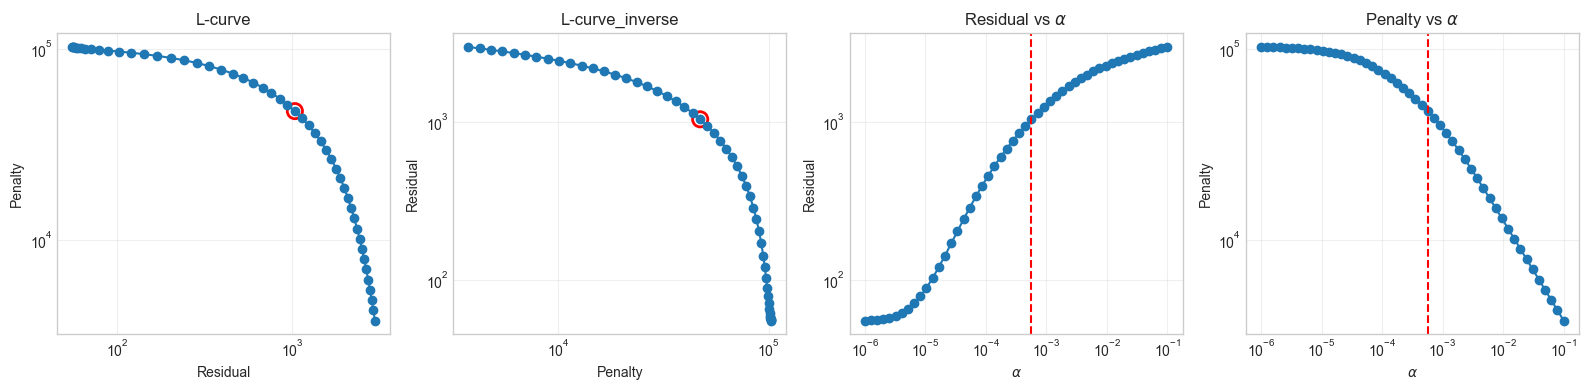

ε(B_z)   = 3.2388e+00
ε(B_phi) = 0.0000e+00


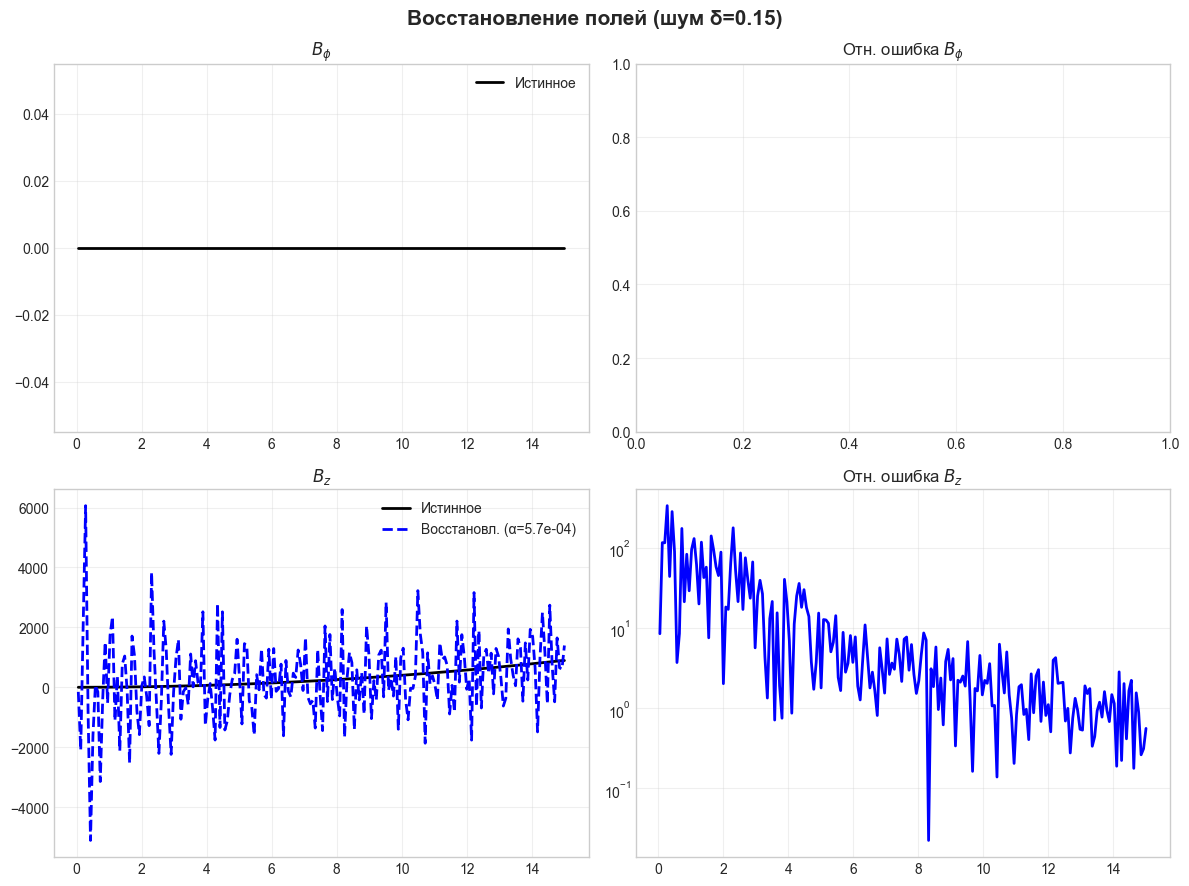

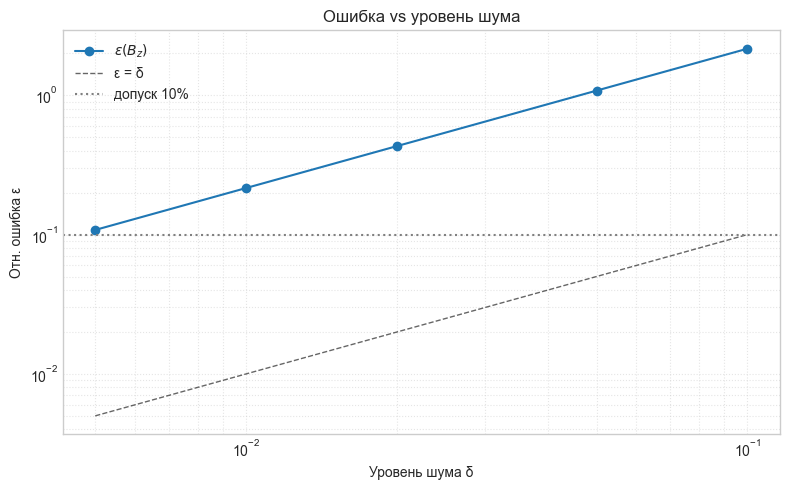

Сетка: N_rho=200, N_z=120, ρ∈[0.05,15.0], z∈[-8.0,8.0]


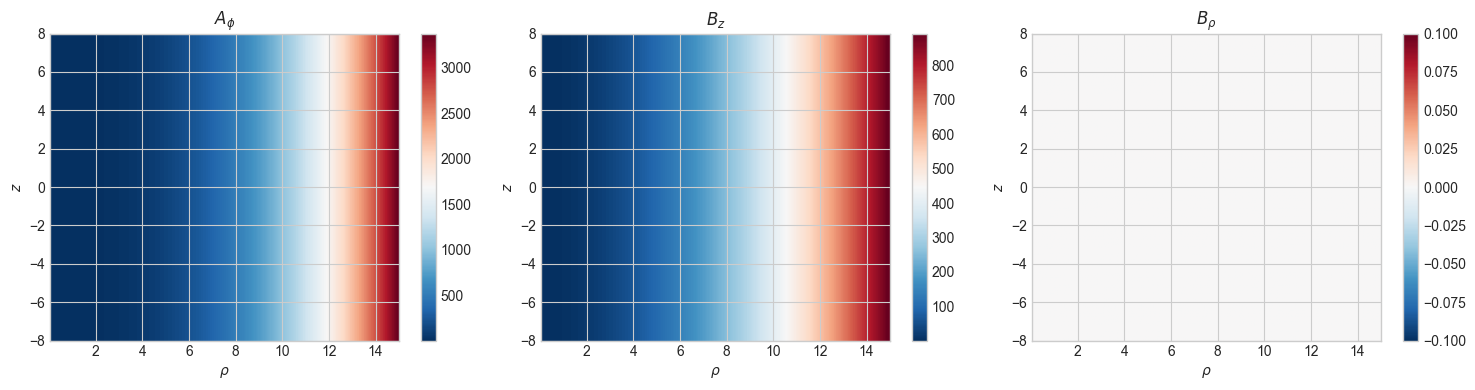

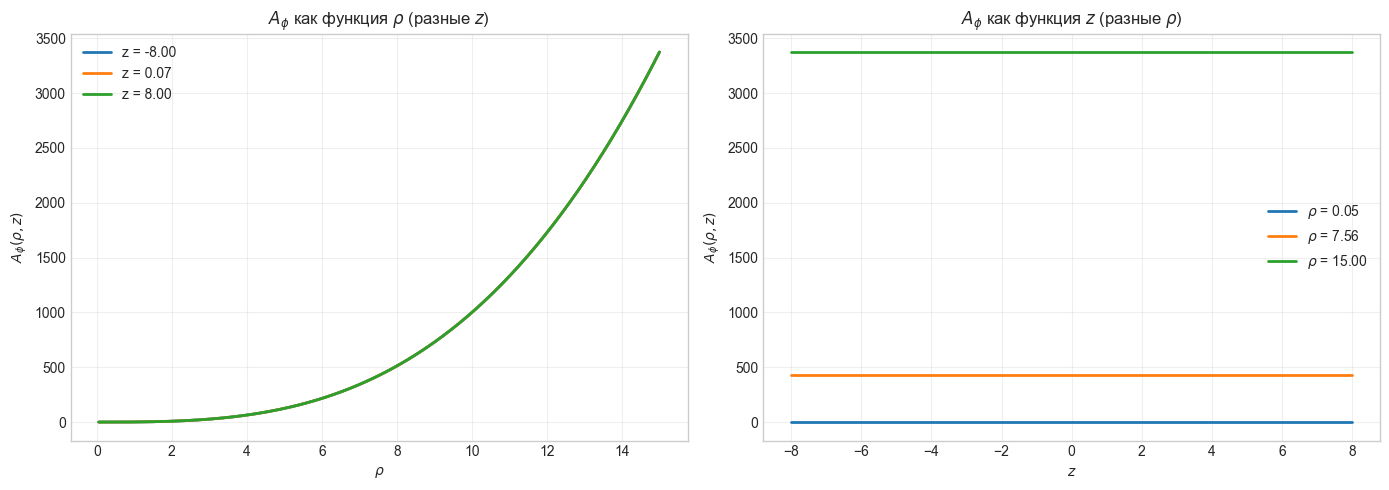

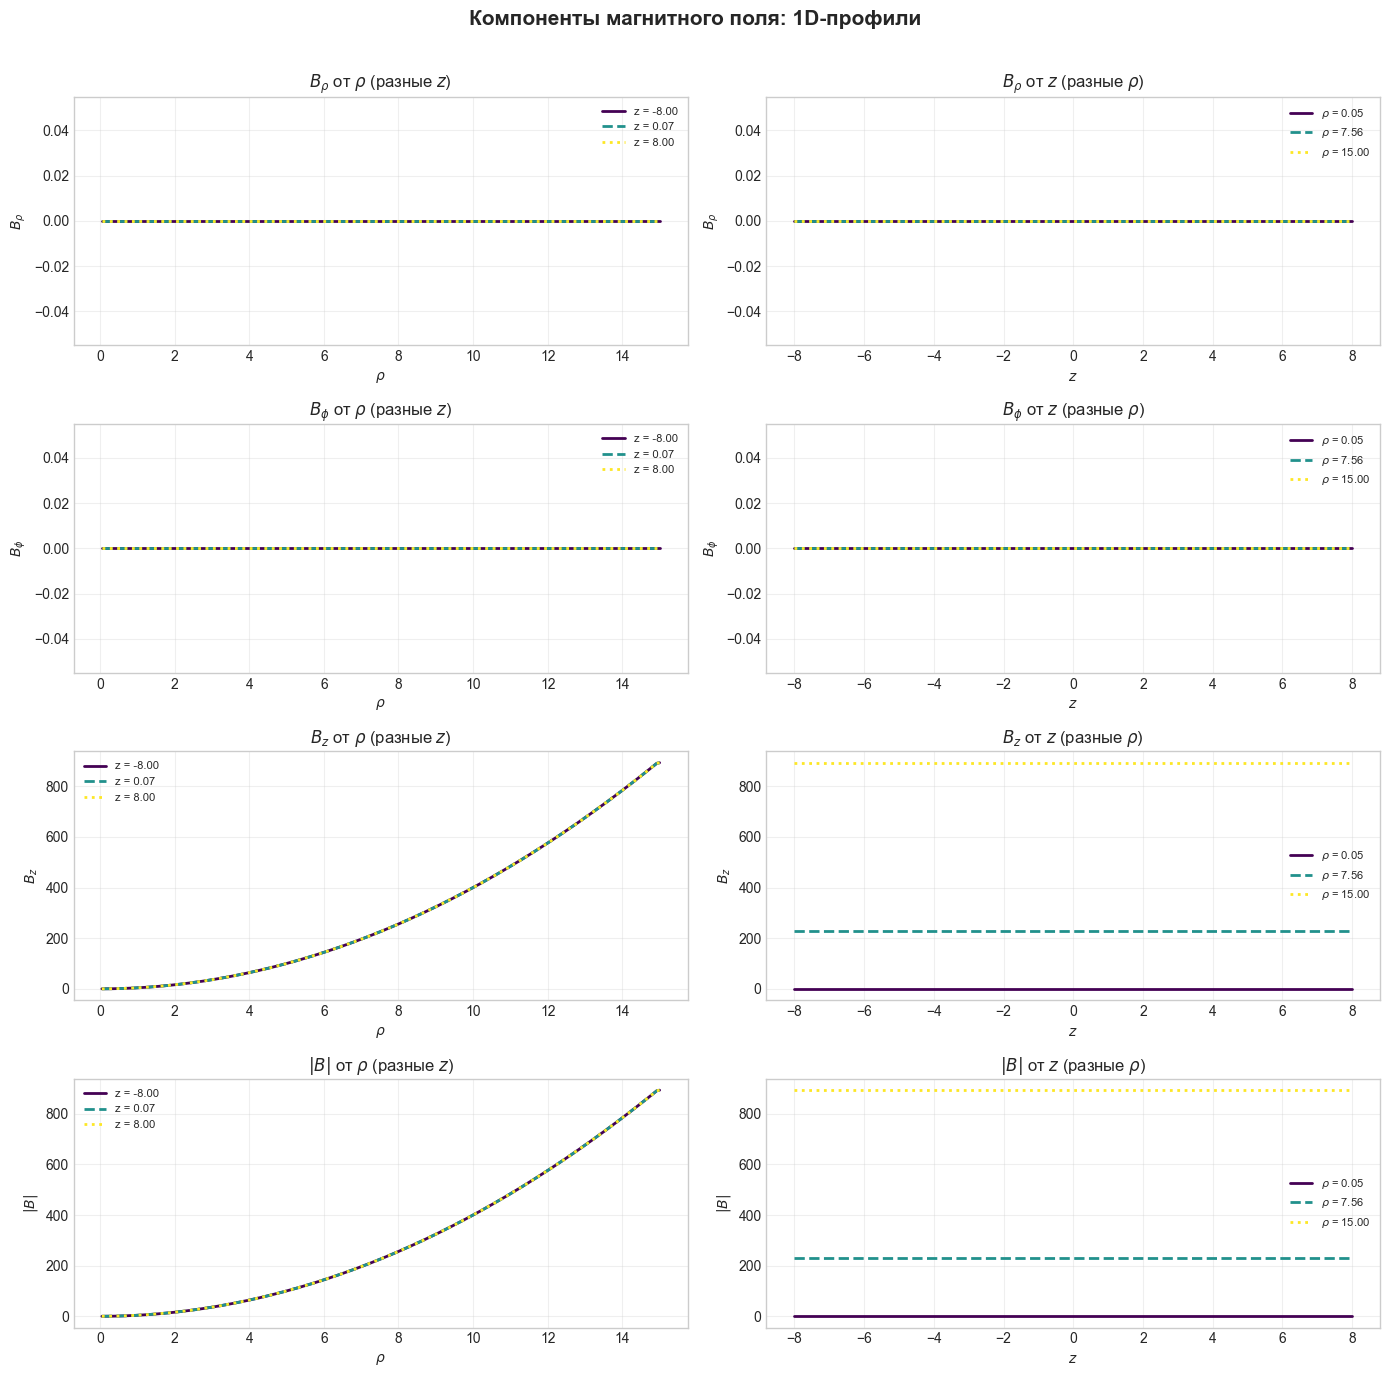

Осевой срез z = 0.07
max|B_z| = 893.2612,  max|B_phi| = 0.0000


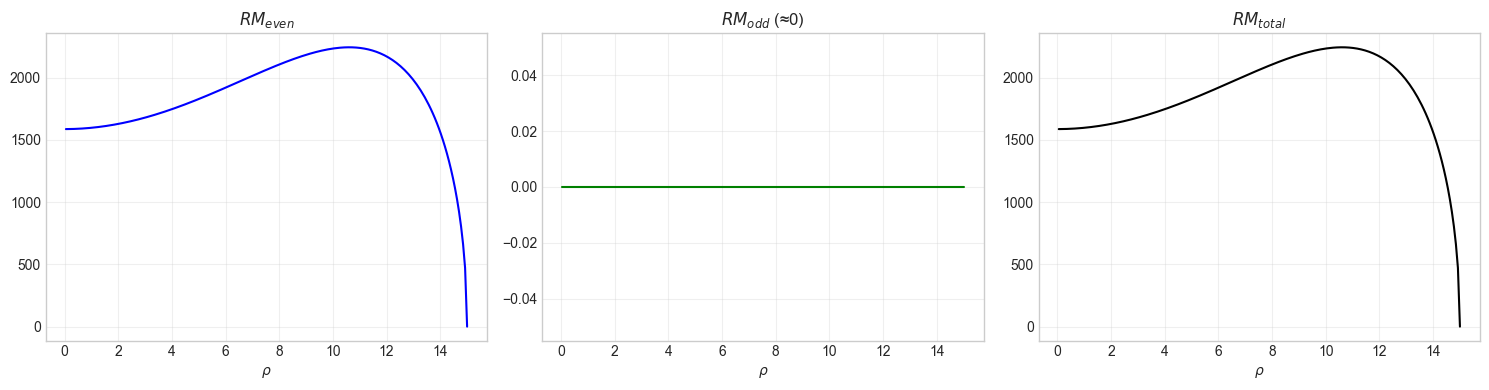

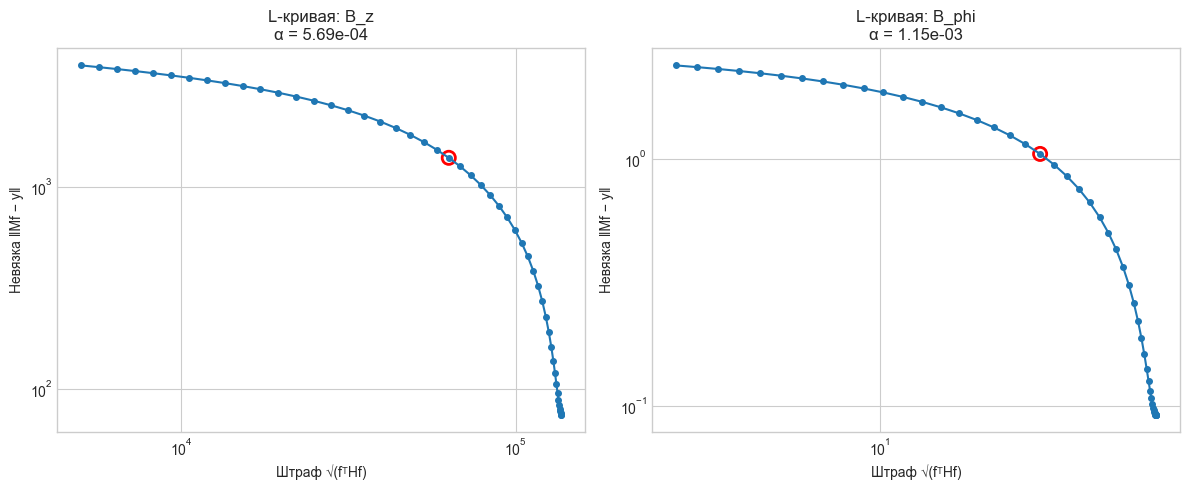

α(B_z)   = 5.69e-04
α(B_phi) = 1.15e-03


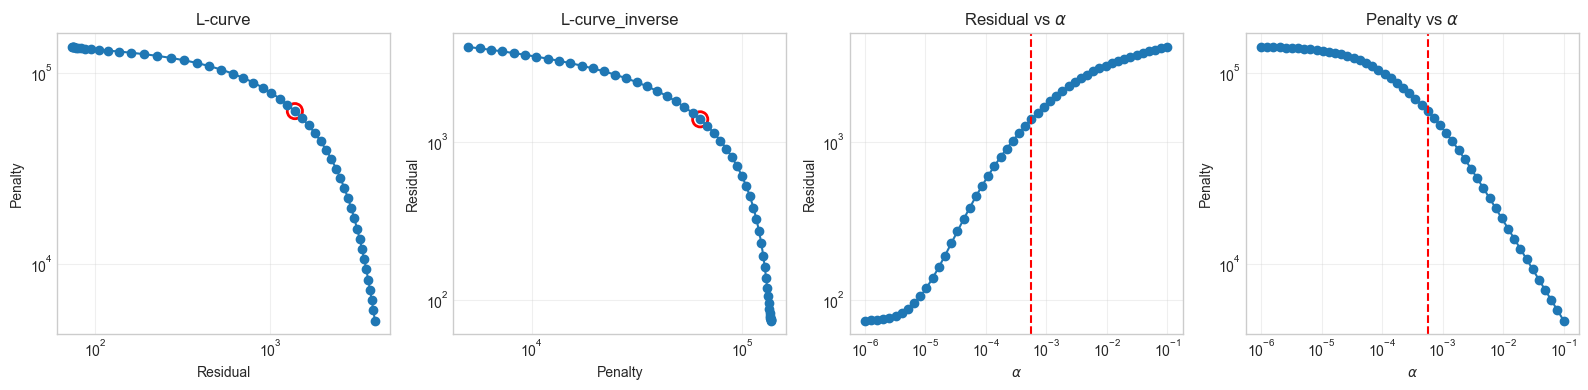

ε(B_z)   = 4.3183e+00
ε(B_phi) = 0.0000e+00


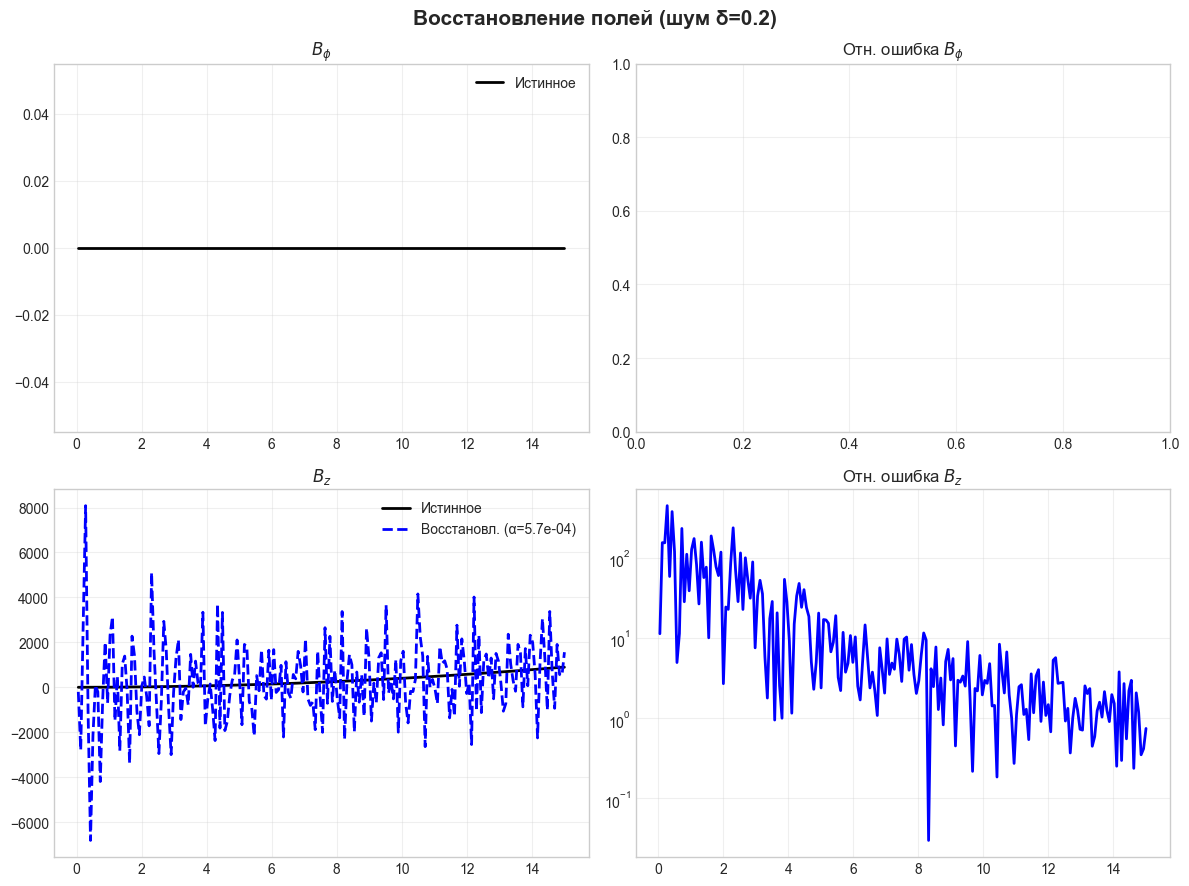

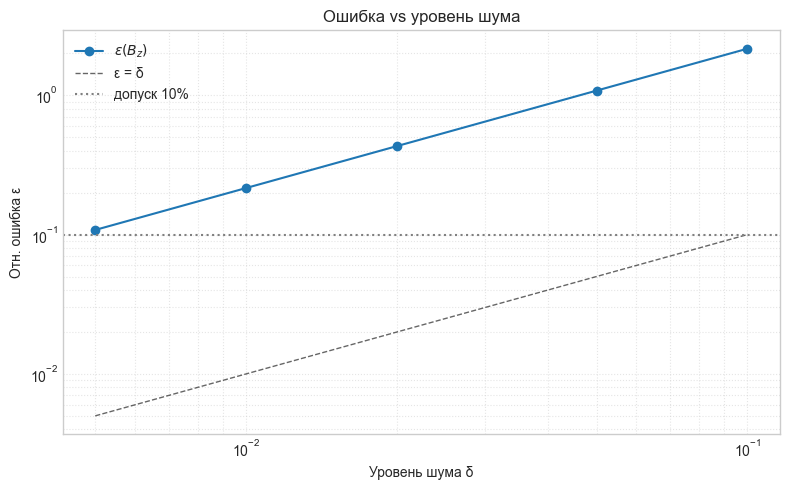

In [7]:
for delta in delta_arr:
    Calculate(A_phi_power, delta= delta)

In [8]:

    
    # ==============================================================================
    # ЯЧЕЙКА 8: Сравнение регуляризаторов
    # ==============================================================================
    reg_kinds  = ["zero_order", "first_order", "second_order"]
    alpha_test = 1e-4
    
    print(f"{'Регуляризатор':<15} {'ε(B_z)':>12}")
    print("-" * 30)
    for kind in reg_kinds:
        H  = regularizer(N, kind=kind)
        iv = RegularizedInversion(M_z, H)
        bz = iv(RM_even_noisy, alpha_test) / n_e_safe
        print(f"{kind:<15} {relative_error(B_z_true, bz):>12.4e}")

Регуляризатор         ε(B_z)
------------------------------


NameError: name 'N' is not defined